Table des matières

[1.Rappel de l'énoncé](#1rappel-de-lénoncé)

[2.Exploration des données](#2exploration-des-données)

[3.Choix des indicateurs par mots-clés](#3choix-des-indicateurs-par-mots-clés)

[4.Choix de l’année d’étude](#4valeur-gardée-de-lannée-la-plus-pertinente-pour-chaque-pays)

[5.taux de complétion par pays](#5taux-de-completion-pour-chaque-pays)

[6.Analyse univariée](#6analyse-univariée)

[7.Analyse bivariée et matrice de corrélation](#7analyse-bivariée-matrice-de-corrélation)

[8.Scoring](#8scoring)

[9.Prédiction/évolution](#9prédiction--évolution)

[10.Etude des pays potentiels par régions](#10etude-des-pays-potentiels-par-régions)

# 1.Rappel de l'énoncé

<span>Vous êtes Data Scientist dans une start-up de la EdTech, nommée Academy, qui propose des contenus de formation en ligne pour un <b>public de niveau lycée et université.</b>

Mark, votre manager, vous a convié à une réunion pour vous présenter le projet d’expansion à l’international de l’entreprise. Il vous confie une première mission d’analyse exploratoire, pour déterminer si les données sur l’éducation de la banque mondiale permettent d’informer le projet d’expansion.

Voici les différentes questions que Mark aimerait explorer, que vous avez notées durant la réunion :

<b>• Quels sont les pays avec un fort potentiel de clients pour nos services ?<b><br><br>
<b>• Pour chacun de ces pays, quelle sera l’évolution de ce potentiel de clients ?</b><br><br>
<b>• Dans quels pays l'entreprise doit-elle opérer en priorité ?</b></span>

# 2.Exploration des données

In [1]:
!pip install missingno # librairie pour les informations manquantes et importation des librairies python utiles

## 2.1 Importation données et librairies

In [6]:
#Importation des librairies Python (pandas, numpy, seaborn, missingno) :
import pandas as pd # importation des librairies pour lire les fichiers csv files et importer les dataframes
import numpy as np # algèbre linéaire
import matplotlib.pyplot as plt # représentations graphiques
import seaborn as sns # représentations graphiques

## 2.2 Description du jeu de données du stack csv 

In [7]:
#Importations des dataframes et vérification du typage des colonnes :
#on renomme le nom des fichiers csv
country = pd.read_csv('EdStatsCountry.csv', sep=",")
series = pd.read_csv('EdStatsSeries.csv', sep=",")
statsdata = pd.read_csv('EdStatsData.csv', sep=",")
footnote = pd.read_csv('EdStatsFootNote.csv', sep=",")
countryseries = pd.read_csv('EdStatsCountry-Series.csv', sep=",")

### 2.2.1 Description du contenu des colonnes des tables du dataset

In [8]:
def nom_du_dataframe(obj, namespace):
    return [name for name in namespace if namespace[name] is obj]
# fonction qui retourne les noms de toutes les colonnes pour chaque dataset

def dataframe_columns(data):
    print('___________________________________________________________')
        # imprime le nom du dataframe
    print('Data : {}'.format(nom_du_dataframe(data, globals())))
    print('Columns : {}'.format(data.columns.values))
       # imprime le nombre de lignes et de colonnes du dataframe
    print('Nombre de lignes, puis de colonnes du dataframe :', data.shape)

dataframe_columns(country)
dataframe_columns(series)
dataframe_columns(statsdata)
dataframe_columns(footnote)
dataframe_columns(countryseries)


___________________________________________________________
Data : ['country']
Columns : ['Country Code' 'Short Name' 'Table Name' 'Long Name' '2-alpha code'
 'Currency Unit' 'Special Notes' 'Region' 'Income Group' 'WB-2 code'
 'National accounts base year' 'National accounts reference year'
 'SNA price valuation' 'Lending category' 'Other groups'
 'System of National Accounts' 'Alternative conversion factor'
 'PPP survey year' 'Balance of Payments Manual in use'
 'External debt Reporting status' 'System of trade'
 'Government Accounting concept' 'IMF data dissemination standard'
 'Latest population census' 'Latest household survey'
 'Source of most recent Income and expenditure data'
 'Vital registration complete' 'Latest agricultural census'
 'Latest industrial data' 'Latest trade data'
 'Latest water withdrawal data' 'Unnamed: 31']
Nombre de lignes, puis de colonnes du dataframe : (241, 32)
___________________________________________________________
Data : ['series']
Columns : ['Ser

>• On remarque que les colonnes </span><span style="color:red">"Indicator Name" <span style="color:black">et</span> "Short et Long definition"</span>  se situent dans la table <span style="color:red">series</span> qui contient les renseignements sur les indicateurs. Cette table nous servira de repère pour les indicateurs


>• On retrouve <span style="color:red">"Indicator Name"</span> à nouveau cette fois dans la table <span style="color:red">statsdata</span> avec pour information supplémentaire l' <span style="color:red">"Indicator Code"</span><span style="color:black"> et </span><span style="color:red">les années à l'étude</span>

>• La table <span style="color:red">country</span> contient les renseignements sur les pays

>• une table <span style="color:red">countryseries</span> avec indications sur les sources des données


>On a également pour chaque table une colonne en trop que l'on va supprimer dans l'étape suivante



In [9]:
country = country.drop(['Unnamed: 31'], axis=1)
series = series.drop(['Unnamed: 20'], axis=1)
footnote = footnote.drop(['Unnamed: 4'], axis=1)
countryseries = countryseries.drop(['Unnamed: 3'], axis=1)
statsdata = statsdata.drop(['Unnamed: 69'], axis=1)

### 2.2.2 Valider la qualité de ce jeu de données (comporte-t-il beaucoup de données manquantes, dupliquées ?)

> <span style="color:black"><b>On vérifie au préalable que les colonnes inutiles ont bien été supprimées :</b></span>

In [10]:
country.columns

Index(['Country Code', 'Short Name', 'Table Name', 'Long Name', '2-alpha code',
       'Currency Unit', 'Special Notes', 'Region', 'Income Group', 'WB-2 code',
       'National accounts base year', 'National accounts reference year',
       'SNA price valuation', 'Lending category', 'Other groups',
       'System of National Accounts', 'Alternative conversion factor',
       'PPP survey year', 'Balance of Payments Manual in use',
       'External debt Reporting status', 'System of trade',
       'Government Accounting concept', 'IMF data dissemination standard',
       'Latest population census', 'Latest household survey',
       'Source of most recent Income and expenditure data',
       'Vital registration complete', 'Latest agricultural census',
       'Latest industrial data', 'Latest trade data',
       'Latest water withdrawal data'],
      dtype='object')

In [11]:
series.columns

Index(['Series Code', 'Topic', 'Indicator Name', 'Short definition',
       'Long definition', 'Unit of measure', 'Periodicity', 'Base Period',
       'Other notes', 'Aggregation method', 'Limitations and exceptions',
       'Notes from original source', 'General comments', 'Source',
       'Statistical concept and methodology', 'Development relevance',
       'Related source links', 'Other web links', 'Related indicators',
       'License Type'],
      dtype='object')

In [12]:
statsdata.columns

Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978',
       '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987',
       '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996',
       '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005',
       '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014',
       '2015', '2016', '2017', '2020', '2025', '2030', '2035', '2040', '2045',
       '2050', '2055', '2060', '2065', '2070', '2075', '2080', '2085', '2090',
       '2095', '2100'],
      dtype='object')

In [13]:
footnote.columns

Index(['CountryCode', 'SeriesCode', 'Year', 'DESCRIPTION'], dtype='object')

In [14]:
countryseries.columns

Index(['CountryCode', 'SeriesCode', 'DESCRIPTION'], dtype='object')

> Les colonnes en trop ont bien été supprimées des dataframes

#### Nombre de valeurs manquantes et de doublons par dataframe

In [ ]:
# Nombre total de valeurs manquantes
print(f'Nombre total de valeurs manquantes pour country {country.isnull().sum().sum()}, {(series.isnull().sum() * 100 / len(series)).mean()}   en %, détails :') 
print('\n')
print(f'Nombre total de valeurs manquantes pour chaque caractéristique de country \n{country.isnull().sum()}')

print('\n')
print('\n')
print(f'Nombre total de valeurs manquantes pour series {series.isnull().sum().sum()}, {(series.isnull().sum() * 100 / len(series)).mean()}  en %, détails :') 
print('\n')
print(f'Nombre total de valeurs manquantes pour chaque caractéristique de series \n{series.isnull().sum()}')

print('\n')
print('\n')
print(f'Nombre total de valeurs manquantes pour statsdata {statsdata.isnull().sum().sum()}, {(statsdata.isnull().sum() * 100 / len(statsdata)).mean()}  en %, détails :')
print('\n')
print(f'Nombre total de valeurs manquantes pour chaque caractéristique de statsdata \n{statsdata.isnull().sum()}') 

print('\n')
print('\n')
print(f'Nombre total de valeurs manquantes pour footnote {footnote.isnull().sum().sum()}, {(footnote.isnull().sum() * 100 / len(footnote)).mean()}  en %, détails :') 
print('\n')
print(f'Nombre total de valeurs manquantes pour chaque caractéristique de footnote \n{footnote.isnull().sum()}') 

print('\n')
print('\n')
print(f'Nombre total de valeurs manquantes pour countryseries {countryseries.isnull().sum().sum()},  {(countryseries.isnull().sum() * 100 / len(countryseries)).mean()}  en %, détails :') 
print('\n')
print(f'Nombre total de valeurs manquantes pour chaque caractéristique de countryseries \n{countryseries.isnull().sum()}') 


><span style="color:red"><b>Les doublons :</b></span>

In [ ]:
country.duplicated().sum()
series.duplicated().sum()
statsdata.duplicated().sum()
footnote.duplicated().sum()
countryseries.duplicated().sum()

><span style="color:red"><b>Conclusion : 0 doublons, mais beaucoup de data manquantes.</b></span> 

#### Graphique avec taux de complétion

<AxesSubplot:>

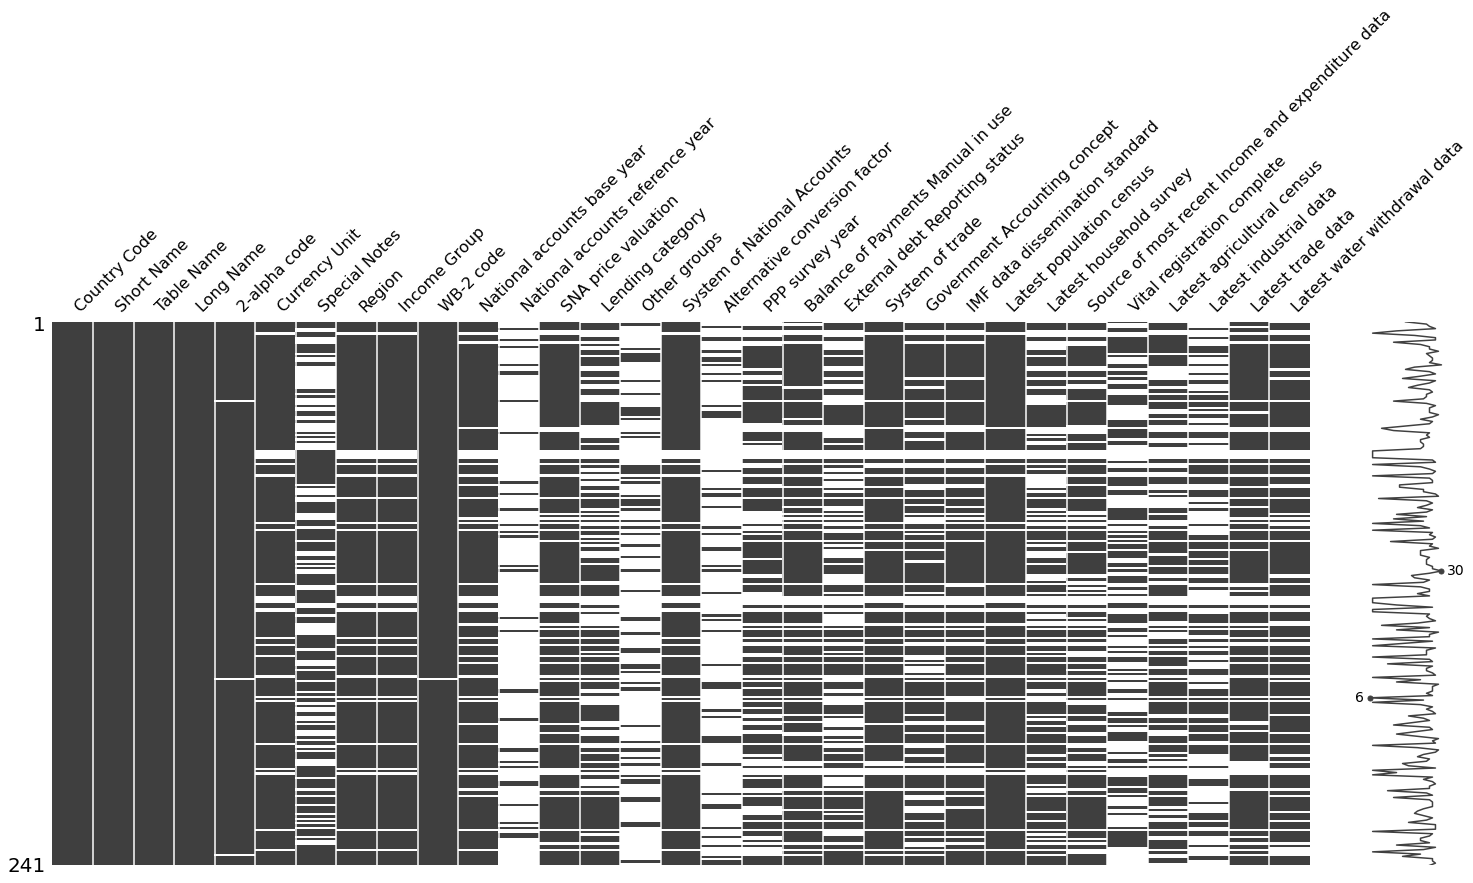

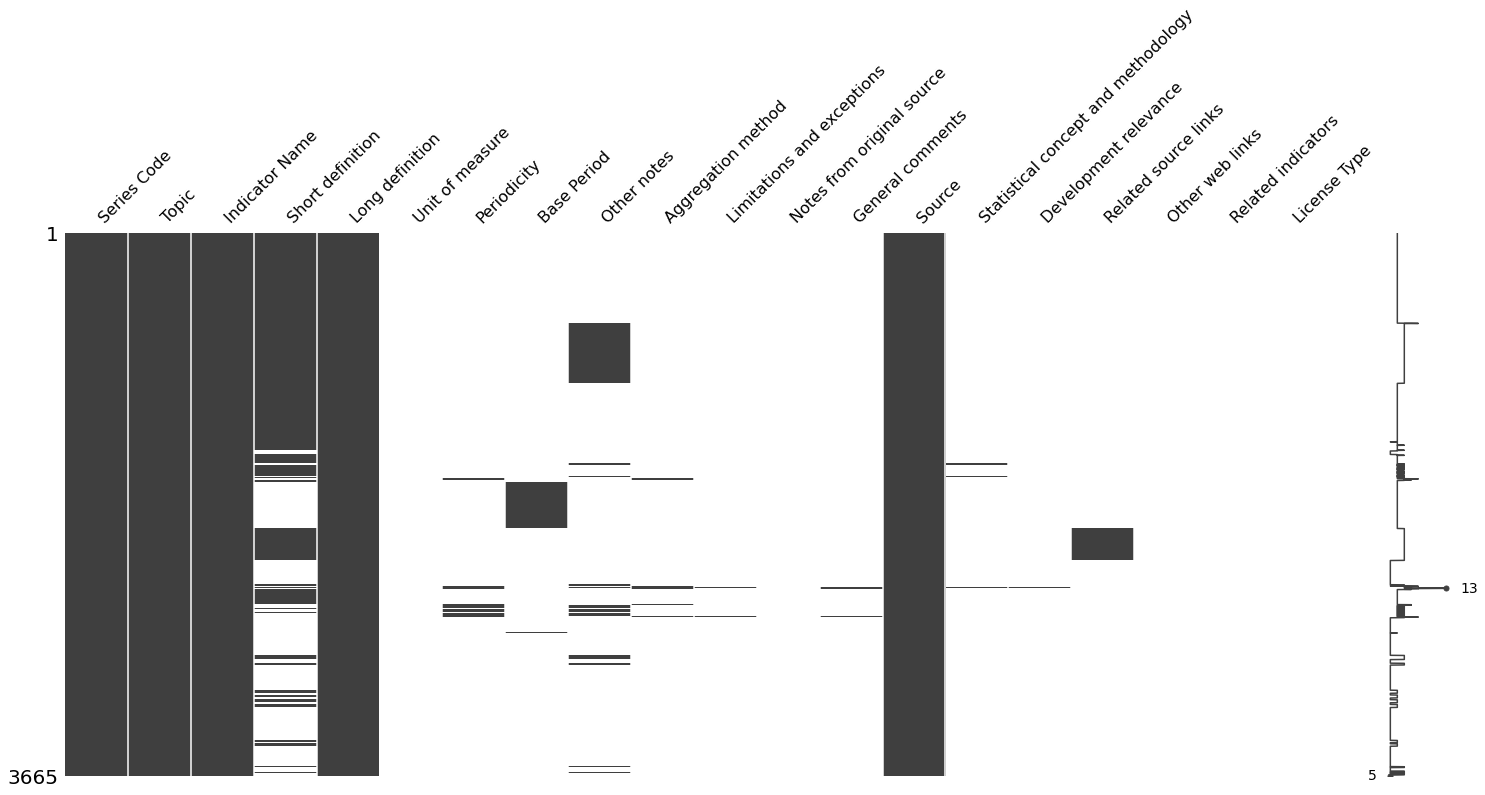

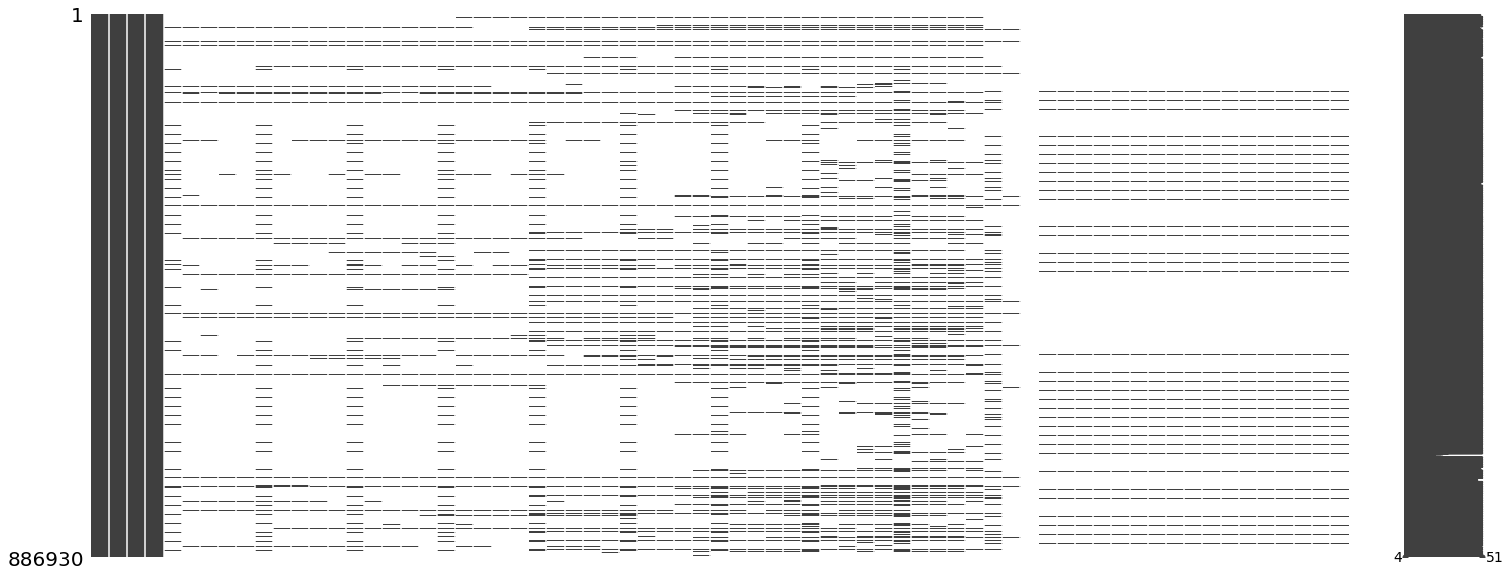

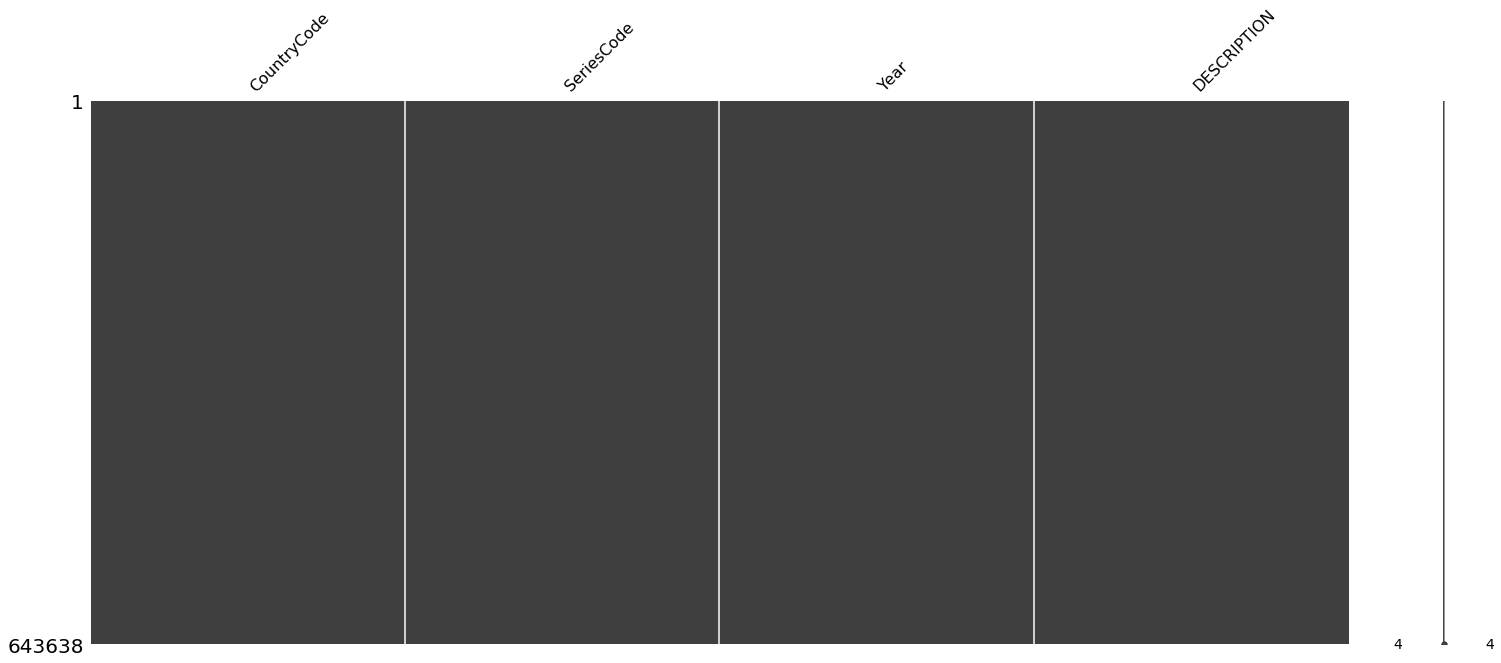

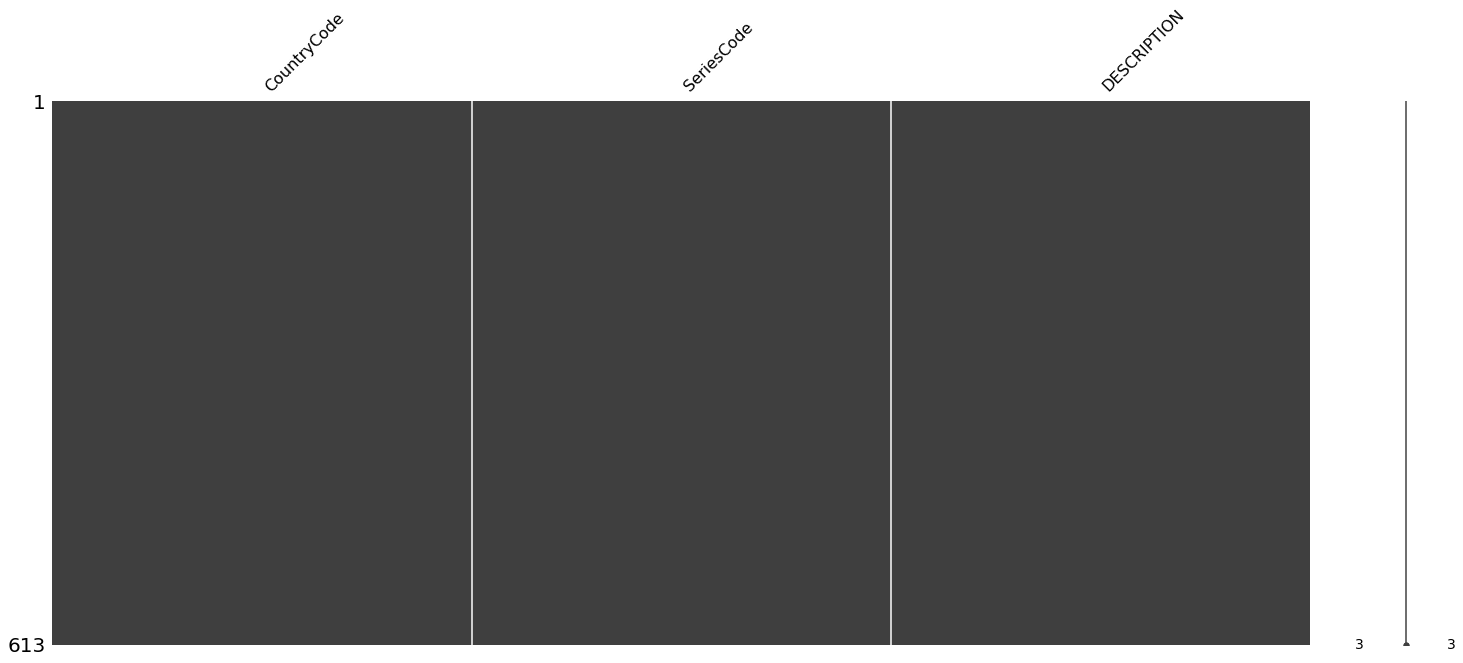

In [15]:
# Graphique aperçu du taux de complétion pour chaque caractéristique
import missingno as msno
%matplotlib inline
msno.matrix(country)
msno.matrix(series)
msno.matrix(statsdata)
msno.matrix(footnote)
msno.matrix(countryseries)

In [ ]:
msno.dendrogram(statsdata)

Le graphique dendrogramme fournit un graphique arborescent généré par le regroupement hiérarchique et regroupe les colonnes qui présentent de fortes corrélations en matière de nullité.
Si un certain nombre de colonnes sont regroupées au niveau zéro, alors la présence de valeurs nulles dans l'une de ces colonnes est directement liée à la présence ou à l'absence de valeurs nulles dans les autres colonnes. Plus les colonnes sont séparées dans l'arbre, moins les valeurs nulles sont susceptibles d'être corrélées entre les colonnes.

### 2.2.3 informations contenues dans le jeu de données 

#### nombre de colonnes et nombre de lignes des dataset

In [16]:
print("Le nombre de lignes et de colonnes pour chacun des dataset sont respectivement de :")
print(f'{country.shape} pour le dataset country')
print(f'{countryseries.shape} pour le dataset des series')
print(f'{statsdata.shape} pour le dataset des stats data')
print(f'{footnote.shape} pour le dataset contenant les footnote')
print(f'{countryseries.shape} pour le dataset contenant les countryseries')


Le nombre de lignes et de colonnes pour chacun des dataset sont respectivement de :
(241, 31) pour le dataset country
(613, 3) pour le dataset des series
(886930, 69) pour le dataset des stats data
(643638, 4) pour le dataset contenant les footnote
(613, 3) pour le dataset contenant les countryseries


#### type de chaque colonnes pour tous les dataset

In [17]:
country.dtypes

Country Code                                          object
Short Name                                            object
Table Name                                            object
Long Name                                             object
2-alpha code                                          object
Currency Unit                                         object
Special Notes                                         object
Region                                                object
Income Group                                          object
WB-2 code                                             object
National accounts base year                           object
National accounts reference year                     float64
SNA price valuation                                   object
Lending category                                      object
Other groups                                          object
System of National Accounts                           object
Alternative conversion f

In [18]:
series.dtypes

Series Code                             object
Topic                                   object
Indicator Name                          object
Short definition                        object
Long definition                         object
Unit of measure                        float64
Periodicity                             object
Base Period                             object
Other notes                             object
Aggregation method                      object
Limitations and exceptions              object
Notes from original source             float64
General comments                        object
Source                                  object
Statistical concept and methodology     object
Development relevance                   object
Related source links                    object
Other web links                        float64
Related indicators                     float64
License Type                           float64
dtype: object

In [19]:
statsdata.dtypes

Country Name       object
Country Code       object
Indicator Name     object
Indicator Code     object
1970              float64
                   ...   
2080              float64
2085              float64
2090              float64
2095              float64
2100              float64
Length: 69, dtype: object

In [20]:
footnote.dtypes

CountryCode    object
SeriesCode     object
Year           object
DESCRIPTION    object
dtype: object

In [21]:
countryseries.dtypes

CountryCode    object
SeriesCode     object
DESCRIPTION    object
dtype: object

><b>Conclusion : types des colonnes cohérents avec les données qui les composent

#### aperçu des tables

In [22]:
country.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,Budgetary central government,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,...,Budgetary central government,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09",Living Standards Measurement Study Survey (LSM...,Yes,2012,2010.0,2012.0,2006
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,...,NaN,NaN,2011. Population figures compiled from adminis...,NaN,NaN,Yes,NaN,NaN,2006.0,NaN


In [23]:
country.columns

Index(['Country Code', 'Short Name', 'Table Name', 'Long Name', '2-alpha code',
       'Currency Unit', 'Special Notes', 'Region', 'Income Group', 'WB-2 code',
       'National accounts base year', 'National accounts reference year',
       'SNA price valuation', 'Lending category', 'Other groups',
       'System of National Accounts', 'Alternative conversion factor',
       'PPP survey year', 'Balance of Payments Manual in use',
       'External debt Reporting status', 'System of trade',
       'Government Accounting concept', 'IMF data dissemination standard',
       'Latest population census', 'Latest household survey',
       'Source of most recent Income and expenditure data',
       'Vital registration complete', 'Latest agricultural census',
       'Latest industrial data', 'Latest trade data',
       'Latest water withdrawal data'],
      dtype='object')

In [24]:
country["Region"].unique()

array(['Latin America & Caribbean', 'South Asia', 'Sub-Saharan Africa',
       'Europe & Central Asia', nan, 'Middle East & North Africa',
       'East Asia & Pacific', 'North America'], dtype=object)

In [25]:
country.loc[country["Region"].isna(),["Region","Country Code","Table Name"]]

,Region,Country Code,Table Name
5,NaN,ARB,Arab World
57,NaN,EAP,East Asia & Pacific
58,NaN,EAS,East Asia & Pacific (all income levels)
59,NaN,ECA,Europe & Central Asia
60,NaN,ECS,Europe & Central Asia (all income levels)
63,NaN,EMU,Euro area
68,NaN,EUU,European Union
78,NaN,GIB,Gibraltar
89,NaN,HIC,High income
92,NaN,HPC,Heavily indebted poor countries (HIPC)


In [26]:
list_a_suppr = country.loc[country["Region"].isna(),["Country Code"]]

In [27]:
list_a_suppr = list_a_suppr['Country Code'].tolist()

In [28]:
list_a_suppr

['ARB',
 'EAP',
 'EAS',
 'ECA',
 'ECS',
 'EMU',
 'EUU',
 'GIB',
 'HIC',
 'HPC',
 'LAC',
 'LCN',
 'LDC',
 'LIC',
 'LMC',
 'LMY',
 'MEA',
 'MIC',
 'MNA',
 'NAC',
 'NRU',
 'OED',
 'SAS',
 'SSA',
 'SSF',
 'UMC',
 'WLD']

> On remarque une anomalie dans le dataset avec des catégories qui ne sont pas des pays
On ne prendra donc pas en compte cette liste dans notre scoring final

In [29]:
series.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15-19 with...,Percentage of female population age 15-19 with...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 ...,Percentage of population age 15-19 with no edu...,Percentage of population age 15-19 with no edu...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15+ with n...,Percentage of female population age 15+ with n...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ wi...,Percentage of population age 15+ with no educa...,Percentage of population age 15+ with no educa...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 20-24 with...,Percentage of female population age 20-24 with...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
statsdata.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,54.822121,54.894138,56.209438,57.267109,57.991138,59.36554,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


> On supprime les anomalies de pays qui n'en sont pas :

In [31]:
statsdata = statsdata[~statsdata['Country Code'].isin(list_a_suppr)]

In [32]:
statsdata

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100
91625,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,7.05911,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91626,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,NaN,NaN,NaN,2.53138,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91627,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,0.22154,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91628,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,NaN,NaN,NaN,NaN,11.42652,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91629,Afghanistan,AFG,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886925,Zimbabwe,ZWE,"Youth illiterate population, 15-24 years, male...",UIS.LP.AG15T24.M,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
886926,Zimbabwe,ZWE,"Youth literacy rate, population 15-24 years, b...",SE.ADT.1524.LT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
886927,Zimbabwe,ZWE,"Youth literacy rate, population 15-24 years, f...",SE.ADT.1524.LT.FE.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
886928,Zimbabwe,ZWE,"Youth literacy rate, population 15-24 years, g...",SE.ADT.1524.LT.FM.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
footnote.head()

,CountryCode,SeriesCode,Year,DESCRIPTION
0,ABW,SE.PRE.ENRL.FE,YR2001,Country estimation.
1,ABW,SE.TER.TCHR.FE,YR2005,Country estimation.
2,ABW,SE.PRE.TCHR.FE,YR2000,Country estimation.
3,ABW,SE.SEC.ENRL.GC,YR2004,Country estimation.
4,ABW,SE.PRE.TCHR,YR2006,Country estimation.


In [34]:
countryseries.head()

,CountryCode,SeriesCode,DESCRIPTION
0,ABW,SP.POP.TOTL,Data sources : United Nations World Population...
1,ABW,SP.POP.GROW,Data sources: United Nations World Population ...
2,AFG,SP.POP.GROW,Data sources: United Nations World Population ...
3,AFG,NY.GDP.PCAP.PP.CD,Estimates are based on regression.
4,AFG,SP.POP.TOTL,Data sources : United Nations World Population...


>Contenu : 

• Deux tables ‘Series’ et ‘Country’ qui contiennent des renseignements sur les pays et des renseignements sur les indicateurs


• 5 tables ayant des clés communes


• Une table principale ‘Data’ qui contient 8 629 921 Valeurs renseignées de 3665 indicateurs différents pour 242 pays et 65 années traitant de 37 ‘topics’


• Deux tables ‘Footnote’ et ‘CountrySeries’ contenant des indications complémentaires et sources sur les données

### 2.2.4 Colonnes contenant des informations qui peuvent être utiles pour répondre à la problématique de l’entreprise

#### identification des colonnes utiles

<AxesSubplot:>

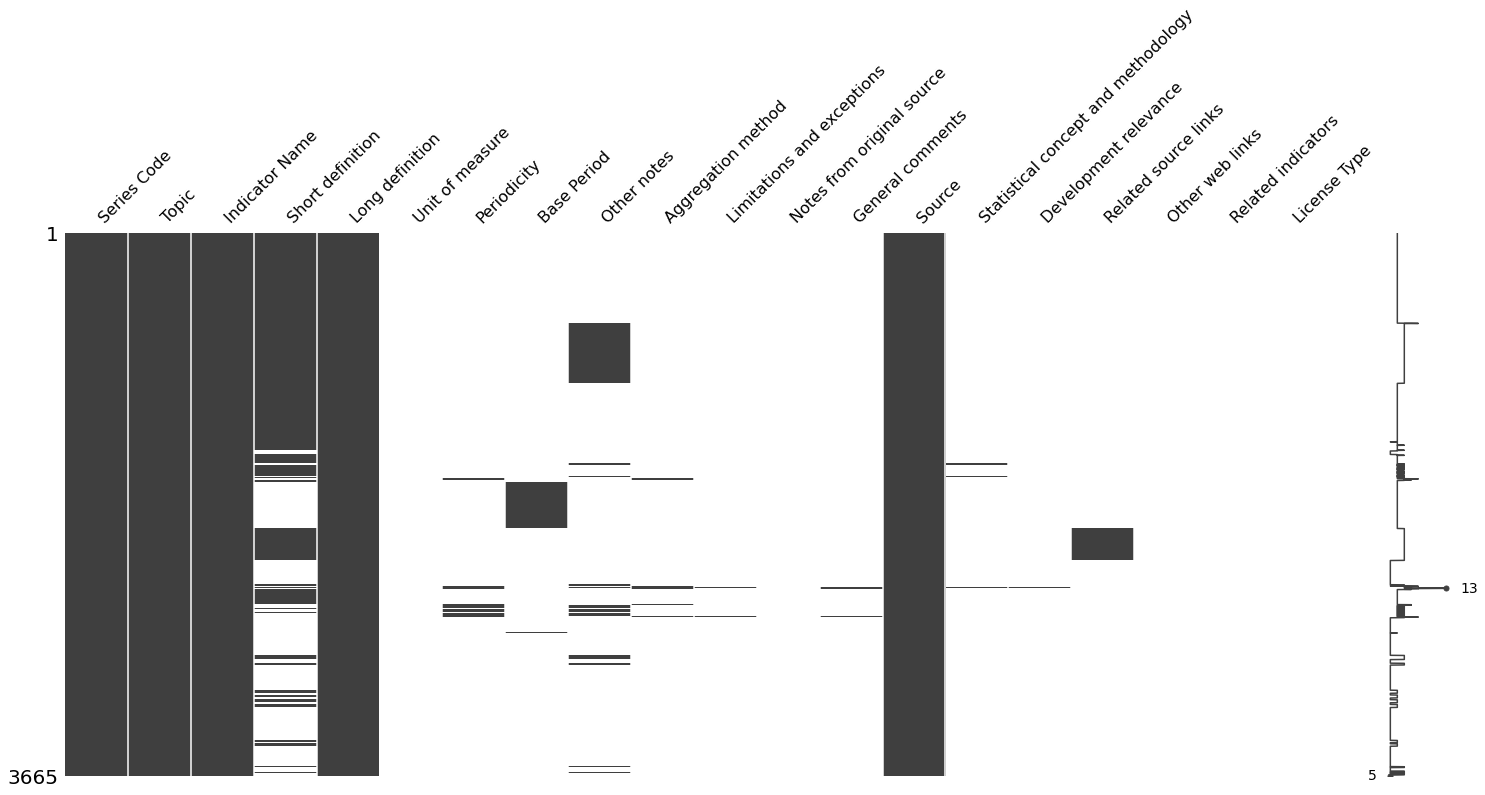

In [42]:
%matplotlib inline
msno.matrix(series)

In [43]:
series.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3665 entries, 0 to 3664
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Series Code                          3665 non-null   object 
 1   Topic                                3665 non-null   object 
 2   Indicator Name                       3665 non-null   object 
 3   Short definition                     2156 non-null   object 
 4   Long definition                      3665 non-null   object 
 5   Unit of measure                      0 non-null      float64
 6   Periodicity                          99 non-null     object 
 7   Base Period                          314 non-null    object 
 8   Other notes                          552 non-null    object 
 9   Aggregation method                   47 non-null     object 
 10  Limitations and exceptions           14 non-null     object 
 11  Notes from original source    

In [44]:
statsdata.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100
91625,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,7.05911,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91626,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,NaN,NaN,NaN,2.53138,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91627,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,0.22154,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91628,Afghanistan,AFG,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,NaN,NaN,NaN,NaN,11.42652,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91629,Afghanistan,AFG,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<AxesSubplot:>

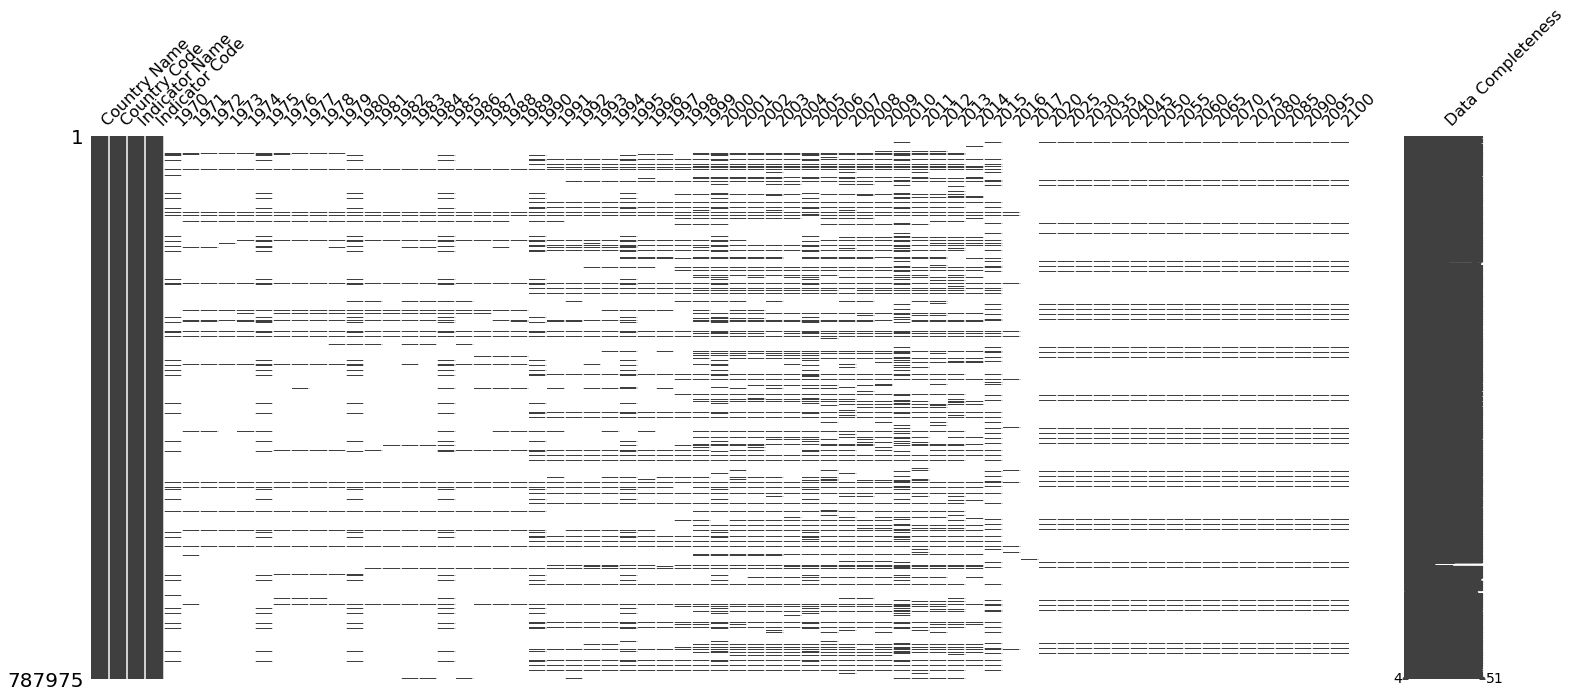

In [45]:
%matplotlib inline
msno.matrix(statsdata, labels=True)

<AxesSubplot:>

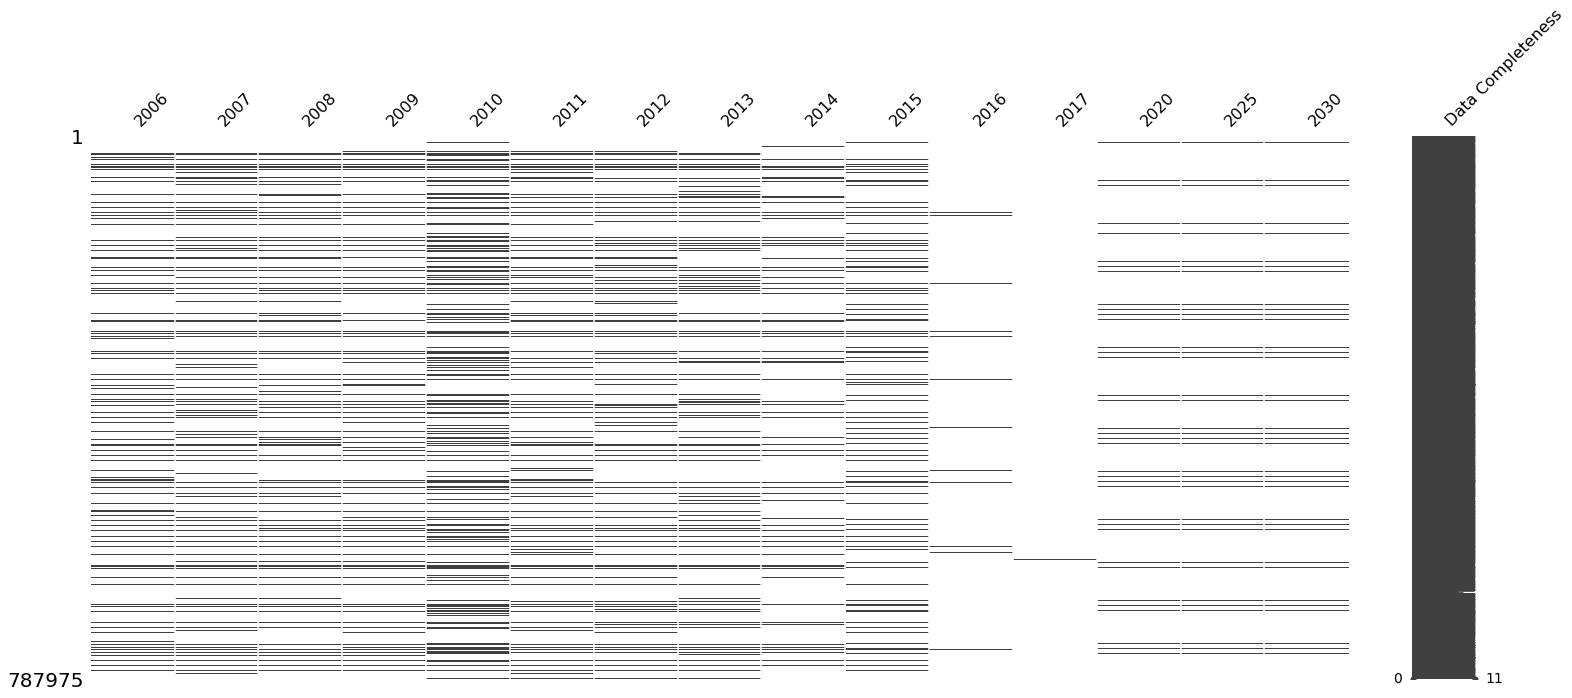

In [46]:
msno.matrix(statsdata.loc[:,"2006":"2030"], labels=True)

<AxesSubplot:>

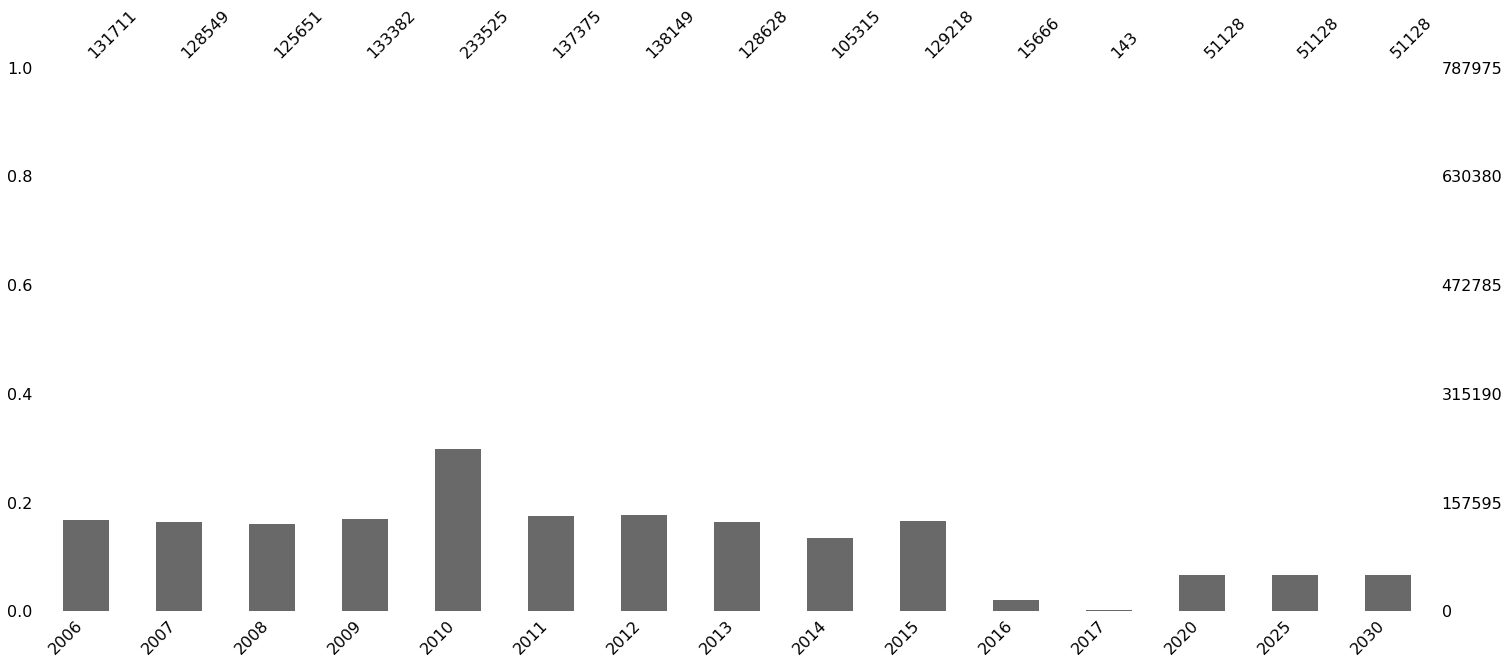

In [47]:
msno.bar(statsdata.loc[:,"2006":"2030"], labels=True)

> on voit qu'on a le plus de data pour l'année 2010 dans la table statsdata mais très peu en 2017, l'année d'étude

In [48]:
print(statsdata.isnull().sum())

Country Name           0
Country Code           0
Indicator Name         0
Indicator Code         0
1970              719412
                   ...  
2080              736847
2085              736847
2090              736847
2095              736847
2100              736847
Length: 69, dtype: int64


# 3.Choix des indicateurs par mots-clés

In [49]:
indicateurs_pertinents = ['population','Internet','education','thousands','high-school','university','15-19','20-24', 'population growth', 
'computers','GDP','total poulation size']
dataset_ind = series[series['Long definition'].str.contains('|'.join(indicateurs_pertinents))]

print("Indicateurs en lien avec ces mots-clés {} sont au nombre de {}".format(indicateurs_pertinents,len(dataset_ind)))
indicators = pd.DataFrame(columns=['Series Code','Long definition'])
for serie in dataset_ind.iterrows():
    indicators = indicators.append(pd.DataFrame([[serie[1]['Series Code'],serie[1]['Long definition']]],
    columns=['Series Code','Long definition']))
indicators

Indicateurs en lien avec ces mots-clés ['population', 'Internet', 'education', 'thousands', 'high-school', 'university', '15-19', '20-24', 'population growth', 'computers', 'GDP', 'total poulation size'] sont au nombre de 1918


,Series Code,Long definition
0,BAR.NOED.1519.FE.ZS,Percentage of female population age 15-19 with...
0,BAR.NOED.1519.ZS,Percentage of population age 15-19 with no edu...
0,BAR.NOED.15UP.FE.ZS,Percentage of female population age 15+ with n...
0,BAR.NOED.15UP.ZS,Percentage of population age 15+ with no educa...
0,BAR.NOED.2024.FE.ZS,Percentage of female population age 20-24 with...
...,...,...
0,UIS.XUNIT.USCONST.3.FSGOV,"Average total (current, capital and transfers)..."
0,UIS.XUNIT.USCONST.4.FSGOV,"Average total (current, capital and transfers)..."
0,UIS.XUNIT.USCONST.56.FSGOV,"Average total (current, capital and transfers)..."
0,XGDP.23.FSGOV.FDINSTADM.FFD,"Total general (local, regional and central) go..."


In [50]:
indicators.to_csv('indicators.csv', index=False)

> ensuite on va chercher manuellement dans le csv et en s'aidant du site worldbank pour sélectionner notre choix final d'indicateurs.
Ce qui nous donne :

In [51]:
list_indicators=[""]
indicator_tab = statsdata[(statsdata["Indicator Code"]=="BAR.SEC.CMPT.1519.ZS") |
        
          (statsdata["Indicator Code"]=="BAR.SEC.CMPT.2024.ZS")|  
          (statsdata["Indicator Code"]=="BAR.SEC.SCHL.1519.FE")|
          (statsdata["Indicator Code"]=="BAR.SEC.SCHL.2024.FE")|

          
          (statsdata["Indicator Code"]=="IT.CMP.PCMP.P2") |
          (statsdata["Indicator Code"]=="IT.NET.USER.P2")|

           (statsdata["Indicator Code"]=="SP.POP.GROW") |
           (statsdata["Indicator Code"]=="NY.GDP.PCAP.CD") |
          (statsdata["Indicator Code"]=="XGDP.23.FSGOV.FDINSTADM.FFD")
          |
          (statsdata["Indicator Code"]=="SP.POP.TOTL")
          |
          (statsdata["Indicator Code"]=="SP.POP.1524.TO.UN")]
indicator_tab.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100
91806,Afghanistan,AFG,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.1519.FE,0.050000,NaN,NaN,NaN,NaN,0.060000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
91808,Afghanistan,AFG,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.2024.FE,0.100000,NaN,NaN,NaN,NaN,0.100000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
92009,Afghanistan,AFG,Barro-Lee: Percentage of population age 15-19 ...,BAR.SEC.CMPT.1519.ZS,0.800000,NaN,NaN,NaN,NaN,1.250000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
92016,Afghanistan,AFG,Barro-Lee: Percentage of population age 20-24 ...,BAR.SEC.CMPT.2024.ZS,0.990000,NaN,NaN,NaN,NaN,1.020000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
92870,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,157.187422,160.372836,136.117014,144.110319,174.942038,187.975604,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
indicator_tab.columns

Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978',
       '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987',
       '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996',
       '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005',
       '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014',
       '2015', '2016', '2017', '2020', '2025', '2030', '2035', '2040', '2045',
       '2050', '2055', '2060', '2065', '2070', '2075', '2080', '2085', '2090',
       '2095', '2100'],
      dtype='object')

In [53]:
indicator_tab.iloc[:,[2,3]]

,Indicator Name,Indicator Code
91806,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.1519.FE
91808,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.2024.FE
92009,Barro-Lee: Percentage of population age 15-19 ...,BAR.SEC.CMPT.1519.ZS
92016,Barro-Lee: Percentage of population age 20-24 ...,BAR.SEC.CMPT.2024.ZS
92870,GDP per capita (current US$),NY.GDP.PCAP.CD
...,...,...
884640,Internet users (per 100 people),IT.NET.USER.P2
885349,Personal computers (per 100 people),IT.CMP.PCMP.P2
885572,Population growth (annual %),SP.POP.GROW
885747,"Population, ages 15-24, total",SP.POP.1524.TO.UN


#  4.valeur gardée de l'année la plus pertinente pour chaque pays

> simplification du dataset en ne gardant qu'une valeur d'étude pour chaque pays, pour faire ce choix on choisit la valeur non Nan la plus proche de notre année d'étude

In [54]:
 num_row = 0
for index, row in indicator_tab.iterrows():
    indicator = float("nan")
    distance_2017 = 0
    year = 2017
    while np.isnan(indicator) and year > 2004:
        year = year - 1
        distance_2017 = distance_2017 - 1
        indicator = row[str(year)]
    
    print("ligne : " + str(index) + ", année : " + str(year) + ", valeur : "+ str(indicator))
    indicator_tab.at[index,'value_for_most_accurate_year'] = indicator  

ligne : 91806, année : 2010, valeur : 1.67
ligne : 91808, année : 2010, valeur : 0.96
ligne : 92009, année : 2010, valeur : 9.45
ligne : 92016, année : 2010, valeur : 15.6
ligne : 92870, année : 2016, valeur : 561.77874627093
ligne : 92883, année : 2004, valeur : nan
ligne : 93000, année : 2016, valeur : 10.59572642
ligne : 93709, année : 2006, valeur : 0.390148257118001
ligne : 93932, année : 2016, valeur : 2.6891634730922
ligne : 94107, année : 2015, valeur : 7252785.0
ligne : 94158, année : 2016, valeur : 34656032.0
ligne : 95471, année : 2010, valeur : 5.26
ligne : 95473, année : 2010, valeur : 3.14
ligne : 95674, année : 2010, valeur : 36.85
ligne : 95681, année : 2010, valeur : 55.96
ligne : 96535, année : 2016, valeur : 4124.98239042866
ligne : 96548, année : 2013, valeur : 0.701640009880066
ligne : 96665, année : 2016, valeur : 66.3634447
ligne : 97374, année : 2008, valeur : 4.59353838043875
ligne : 97597, année : 2016, valeur : -0.159880412127734
ligne : 97772, année : 2015, 

/Users/laureagrech/opt/anaconda3/lib/python3.9/site-packages/pandas/core/indexing.py:1684: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.obj[key] = infer_fill_value(value)
/Users/laureagrech/opt/anaconda3/lib/python3.9/site-packages/pandas/core/indexing.py:1817: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value, pi)



ligne : 693069, année : 2004, valeur : nan
ligne : 693076, année : 2004, valeur : nan
ligne : 693930, année : 2016, valeur : 1714.68018368506
ligne : 693943, année : 2014, valeur : 0.876500010490417
ligne : 694060, année : 2016, valeur : 28.0
ligne : 694769, année : 2005, valeur : 3.88060666817579
ligne : 694992, année : 2016, valeur : 2.2035822838881
ligne : 695167, année : 2015, valeur : 38279.0
ligne : 695218, année : 2016, valeur : 199910.0
ligne : 696531, année : 2010, valeur : 3.15
ligne : 696533, année : 2010, valeur : 5.15
ligne : 696734, année : 2010, valeur : 18.67
ligne : 696741, année : 2010, valeur : 60.18
ligne : 697595, année : 2016, valeur : 20028.6482069305
ligne : 697608, année : 2004, valeur : nan
ligne : 697725, année : 2016, valeur : 73.75090368
ligne : 698434, année : 2008, valeur : 65.2346448455263
ligne : 698657, année : 2016, valeur : 2.25142247448685
ligne : 698832, année : 2015, valeur : 5298036.0
ligne : 698883, année : 2016, valeur : 32275687.0
ligne : 700

In [55]:
indicator_tab['Country Name'].unique().tolist()

['Afghanistan',
 'Albania',
 'Algeria',
 'American Samoa',
 'Andorra',
 'Angola',
 'Antigua and Barbuda',
 'Argentina',
 'Armenia',
 'Aruba',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas, The',
 'Bahrain',
 'Bangladesh',
 'Barbados',
 'Belarus',
 'Belgium',
 'Belize',
 'Benin',
 'Bermuda',
 'Bhutan',
 'Bolivia',
 'Bosnia and Herzegovina',
 'Botswana',
 'Brazil',
 'British Virgin Islands',
 'Brunei Darussalam',
 'Bulgaria',
 'Burkina Faso',
 'Burundi',
 'Cabo Verde',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Cayman Islands',
 'Central African Republic',
 'Chad',
 'Channel Islands',
 'Chile',
 'China',
 'Colombia',
 'Comoros',
 'Congo, Dem. Rep.',
 'Congo, Rep.',
 'Costa Rica',
 "Cote d'Ivoire",
 'Croatia',
 'Cuba',
 'Curacao',
 'Cyprus',
 'Czech Republic',
 'Denmark',
 'Djibouti',
 'Dominica',
 'Dominican Republic',
 'Ecuador',
 'Egypt, Arab Rep.',
 'El Salvador',
 'Equatorial Guinea',
 'Eritrea',
 'Estonia',
 'Ethiopia',
 'Faroe Islands',
 'Fiji',
 'Finland',
 'France',
 'French Pol

In [56]:
indicator_tab

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2060,2065,2070,2075,2080,2085,2090,2095,2100,value_for_most_accurate_year
91806,Afghanistan,AFG,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.1519.FE,5.000000e-02,NaN,NaN,NaN,NaN,6.000000e-02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.670000e+00
91808,Afghanistan,AFG,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.2024.FE,1.000000e-01,NaN,NaN,NaN,NaN,1.000000e-01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.600000e-01
92009,Afghanistan,AFG,Barro-Lee: Percentage of population age 15-19 ...,BAR.SEC.CMPT.1519.ZS,8.000000e-01,NaN,NaN,NaN,NaN,1.250000e+00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.450000e+00
92016,Afghanistan,AFG,Barro-Lee: Percentage of population age 20-24 ...,BAR.SEC.CMPT.2024.ZS,9.900000e-01,NaN,NaN,NaN,NaN,1.020000e+00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.560000e+01
92870,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,1.571874e+02,1.603728e+02,1.361170e+02,1.441103e+02,1.749420e+02,1.879756e+02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.617787e+02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
884640,Zimbabwe,ZWE,Internet users (per 100 people),IT.NET.USER.P2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.311999e+01
885349,Zimbabwe,ZWE,Personal computers (per 100 people),IT.CMP.PCMP.P2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.431140e+00
885572,Zimbabwe,ZWE,Population growth (annual %),SP.POP.GROW,3.261985e+00,3.336115e+00,3.392956e+00,3.395006e+00,3.329621e+00,3.230955e+00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.336070e+00
885747,Zimbabwe,ZWE,"Population, ages 15-24, total",SP.POP.1524.TO.UN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.333716e+06


In [57]:

print(indicator_tab['Indicator Name'].unique().tolist()) 

['Barro-Lee: Average years of secondary schooling, age 15-19, female', 'Barro-Lee: Average years of secondary schooling, age 20-24, female', 'Barro-Lee: Percentage of population age 15-19 with secondary schooling. Completed Secondary', 'Barro-Lee: Percentage of population age 20-24 with secondary schooling. Completed Secondary', 'GDP per capita (current US$)', 'Government expenditure in secondary institutions education as % of GDP (%)', 'Internet users (per 100 people)', 'Personal computers (per 100 people)', 'Population growth (annual %)', 'Population, ages 15-24, total', 'Population, total']


In [58]:
indicators = ['IT.NET.USER.P2','IT.CMP.PCMP.P2','SP.POP.GROW','BAR.SEC.CMPT.1519.ZS','BAR.SEC.CMPT.2024.ZS','BAR.SEC.SCHL.1519.FE','BAR.SEC.SCHL.2024.FE','IT.CMP.PCMP.P2','IT.NET.USER.P2','NY.GDP.PCAP.CD','XGDP.23.FSGOV.FDINSTADM.FFD','SP.POP.TOTL','SP.POP.1524.TO.UN']
indicator_value_by_countries = indicator_tab[indicator_tab['Indicator Code'].isin(indicators)][["Country Name","Country Code",'Indicator Name',"Indicator Code","value_for_most_accurate_year"]]



In [59]:
indicator_value_by_countries

,Country Name,Country Code,Indicator Name,Indicator Code,value_for_most_accurate_year
91806,Afghanistan,AFG,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.1519.FE,1.670000e+00
91808,Afghanistan,AFG,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.2024.FE,9.600000e-01
92009,Afghanistan,AFG,Barro-Lee: Percentage of population age 15-19 ...,BAR.SEC.CMPT.1519.ZS,9.450000e+00
92016,Afghanistan,AFG,Barro-Lee: Percentage of population age 20-24 ...,BAR.SEC.CMPT.2024.ZS,1.560000e+01
92870,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,5.617787e+02
...,...,...,...,...,...
884640,Zimbabwe,ZWE,Internet users (per 100 people),IT.NET.USER.P2,2.311999e+01
885349,Zimbabwe,ZWE,Personal computers (per 100 people),IT.CMP.PCMP.P2,7.431140e+00
885572,Zimbabwe,ZWE,Population growth (annual %),SP.POP.GROW,2.336070e+00
885747,Zimbabwe,ZWE,"Population, ages 15-24, total",SP.POP.1524.TO.UN,3.333716e+06


In [60]:
indicator_value_by_countries_and_region = indicator_value_by_countries.merge(right = country[['Country Code', 'Region']]) 

In [61]:
indicator_value_by_countries_and_region

,Country Name,Country Code,Indicator Name,Indicator Code,value_for_most_accurate_year,Region
0,Afghanistan,AFG,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.1519.FE,1.670000e+00,South Asia
1,Afghanistan,AFG,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.2024.FE,9.600000e-01,South Asia
2,Afghanistan,AFG,Barro-Lee: Percentage of population age 15-19 ...,BAR.SEC.CMPT.1519.ZS,9.450000e+00,South Asia
3,Afghanistan,AFG,Barro-Lee: Percentage of population age 20-24 ...,BAR.SEC.CMPT.2024.ZS,1.560000e+01,South Asia
4,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,5.617787e+02,South Asia
...,...,...,...,...,...,...
2349,Zimbabwe,ZWE,Internet users (per 100 people),IT.NET.USER.P2,2.311999e+01,Sub-Saharan Africa
2350,Zimbabwe,ZWE,Personal computers (per 100 people),IT.CMP.PCMP.P2,7.431140e+00,Sub-Saharan Africa
2351,Zimbabwe,ZWE,Population growth (annual %),SP.POP.GROW,2.336070e+00,Sub-Saharan Africa
2352,Zimbabwe,ZWE,"Population, ages 15-24, total",SP.POP.1524.TO.UN,3.333716e+06,Sub-Saharan Africa


# 5.taux de completion pour chaque pays

> taux de completion sous forme de graphique pour chaque pays, avec seuil de 90% afin de supprimer les pays dépassant ce seuil

In [62]:
data_etude = pd.pivot_table(indicator_value_by_countries,index=["Country Name"],values=["value_for_most_accurate_year"],columns=["Indicator Code"])
data_etude = data_etude["value_for_most_accurate_year"]

In [63]:
data_etude

Indicator Code,BAR.SEC.CMPT.1519.ZS,BAR.SEC.CMPT.2024.ZS,BAR.SEC.SCHL.1519.FE,BAR.SEC.SCHL.2024.FE,IT.CMP.PCMP.P2,IT.NET.USER.P2,NY.GDP.PCAP.CD,SP.POP.1524.TO.UN,SP.POP.GROW,SP.POP.TOTL,XGDP.23.FSGOV.FDINSTADM.FFD
Country Name,,,,,,,,,,,
Afghanistan,9.45,15.60,1.67,0.96,0.390148,10.595726,561.778746,7252785.0,2.689163,34656032.0,NaN
Albania,36.85,55.96,5.26,3.14,4.593538,66.363445,4124.982390,556269.0,-0.159880,2876101.0,0.70164
Algeria,19.22,22.37,2.74,3.28,1.030597,42.945527,3916.881571,6467818.0,1.825463,40606052.0,NaN
American Samoa,NaN,NaN,NaN,NaN,NaN,NaN,11834.745229,NaN,0.111575,55599.0,NaN
Andorra,NaN,NaN,NaN,NaN,NaN,97.930637,36988.622030,8715.0,-0.944017,77281.0,0.60503
...,...,...,...,...,...,...,...,...,...,...,...
Virgin Islands (U.S.),NaN,NaN,NaN,NaN,2.783758,59.608316,36350.821635,NaN,-0.603319,102951.0,NaN
West Bank and Gaza,NaN,NaN,NaN,NaN,5.477750,61.178385,2943.404534,1053004.0,2.884693,4551566.0,NaN
"Yemen, Rep.",9.79,19.24,1.64,2.02,2.903922,24.579208,990.334774,5995687.0,2.451502,27584213.0,NaN


In [64]:
data_etude.columns = [" Percentage of population age 15-19 who completed sec schooling","Percentage of population age 20-24 completed sec schooling","Average years of secondary schooling, 15-19, female ","Average years of secondary schooling, 20-24, female","Personal computers (per 100 people)","Internet users (per 100 people","GDP per capita (current US$)","Population, ages 15-24, total","Population growth (annual %)","Population, total","Government expenditure in secondary institution"]



In [65]:
data_etude_avec_taux = data_etude.copy()
data_etude_avec_taux['tx_completion']= 1-(data_etude_avec_taux.shape[1] - data_etude_avec_taux.count(axis=1))/data_etude_avec_taux.shape[1] 
data_etude_completion = data_etude_avec_taux.drop(data_etude_avec_taux.loc[:,data_etude_avec_taux.columns!="tx_completion"],1,inplace=False)
data_etude_completion



/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_17606/408650518.py:3: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  data_etude_completion = data_etude_avec_taux.drop(data_etude_avec_taux.loc[:,data_etude_avec_taux.columns!="tx_completion"],1,inplace=False)


,tx_completion
Country Name,
Afghanistan,0.909091
Albania,1.000000
Algeria,0.909091
American Samoa,0.272727
Andorra,0.545455
...,...
Virgin Islands (U.S.),0.454545
West Bank and Gaza,0.545455
"Yemen, Rep.",0.909091


taux de completion pour l'ensemble des pays, pour les 10 indicateurs choisis:

Text(0.5, 0, 'répartition du taux de complétion des pays')

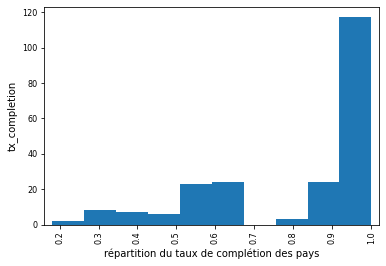

In [66]:
from pandas.plotting import scatter_matrix
scatter_matrix(data_etude_completion)
plt.xlabel('répartition du taux de complétion des pays')

On observe que le taux de complétion est tres correct avec environ 120 pays dont les data sont renseignées à 100% pour les 11 indicateurs de notre étude

>  Les 11 indicateurs sélectionnés semblent donc pertinents pour notre etude (en nombre suffisant)

## comparaison taux de valeurs manquantes du dataset original avec dataset filtré par indicateurs :

## taux de complétion pour le dataset d'étude de départ :

In [68]:
statsdata.isna().sum().sum()/(statsdata.size)

0.8539393997915221

## taux de complétion pour l'ensemble de notre nouveau dataset d'étude :

In [69]:
data_etude.isna().sum().sum()/(data_etude.size)

0.17332200509770604

## taux de complétion par indicateurs avec nouveau dataset d'étude :

<AxesSubplot:>

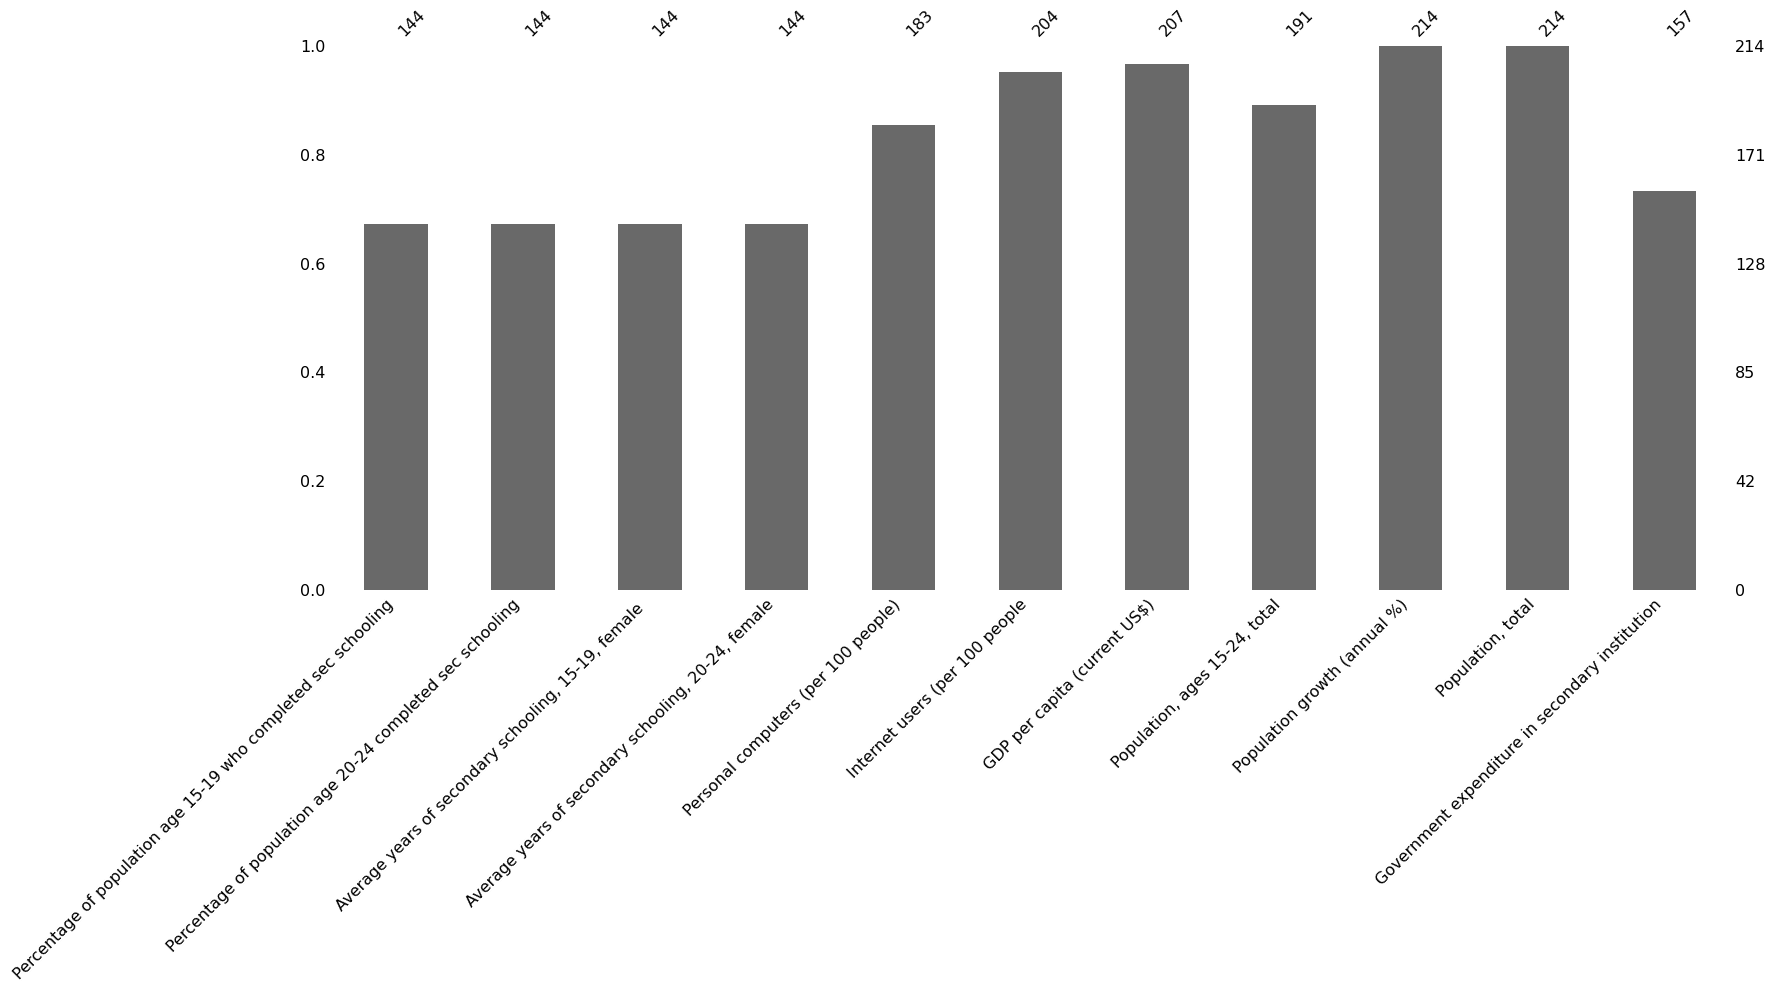

In [70]:
import missingno as msno
%matplotlib inline
msno.bar(data_etude, labels=True)

<AxesSubplot:>

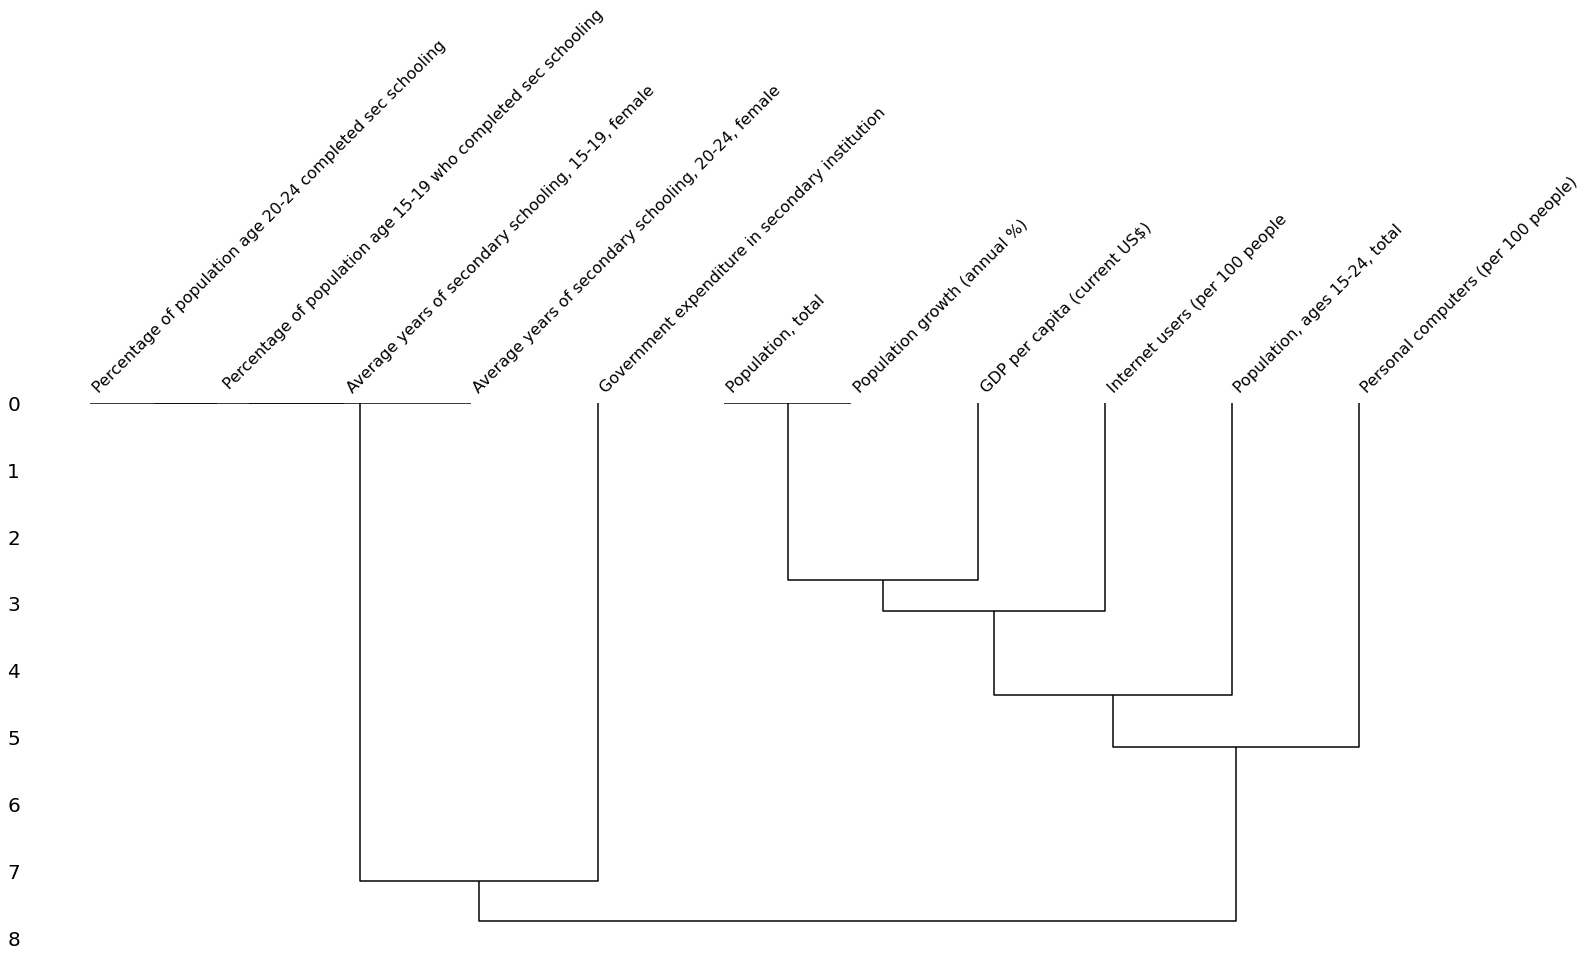

In [71]:
msno.dendrogram(data_etude)

> Ce graphique nous montre la corrélation entre le taux de nan pour chaque lindicateur.

Ceux qui sont au niveau 0 sont directement corrélés (si cette colonne n'est pas remplie alors c'est directement liée à l'autre du niveau 0)
Le plus les colonnes sont éloignées dans l'arbre, le moins il y aurait de corrélation entre ces colonnes par rapport à leur taux de complétion

In [72]:
data_etude_completion.sort_values("tx_completion")

,tx_completion
Country Name,
Sint Maarten (Dutch part),0.181818
St. Martin (French part),0.181818
Channel Islands,0.272727
Isle of Man,0.272727
American Samoa,0.272727
...,...
Jamaica,1.000000
Jordan,1.000000
Kenya,1.000000


## supression des pays pas assez renseignés pour nos 10 indicateurs

> Ici on choisit un seuil de 80% afin de supprimer les pays qui ne sont pas remplis à au moins 80%

In [73]:
pays_a_suppr = data_etude_completion[data_etude_completion['tx_completion'] <= 0.8]

In [74]:
pays_a_suppr #avec taux de complétion inférieur à 80%

,tx_completion
Country Name,
American Samoa,0.272727
Andorra,0.545455
Angola,0.636364
Antigua and Barbuda,0.636364
Aruba,0.636364
...,...
Tuvalu,0.454545
Uzbekistan,0.545455
Vanuatu,0.636364


In [75]:
pays_a_suppr = pays_a_suppr.index

In [76]:
pays_a_suppr

Index(['American Samoa', 'Andorra', 'Angola', 'Antigua and Barbuda', 'Aruba',
       'Azerbaijan', 'Bahamas, The', 'Belarus', 'Bermuda', 'Bhutan',
       'Bosnia and Herzegovina', 'Burkina Faso', 'Cabo Verde',
       'Cayman Islands', 'Chad', 'Channel Islands', 'Comoros', 'Curacao',
       'Djibouti', 'Dominica', 'Equatorial Guinea', 'Eritrea', 'Ethiopia',
       'Faroe Islands', 'French Polynesia', 'Georgia', 'Greenland', 'Grenada',
       'Guam', 'Guinea', 'Guinea-Bissau', 'Isle of Man', 'Kiribati',
       'Korea, Dem. People’s Rep.', 'Kosovo', 'Lebanon', 'Liechtenstein',
       'Macedonia, FYR', 'Madagascar', 'Marshall Islands',
       'Micronesia, Fed. Sts.', 'Monaco', 'Montenegro', 'New Caledonia',
       'Nigeria', 'Northern Mariana Islands', 'Oman', 'Palau', 'Puerto Rico',
       'Samoa', 'San Marino', 'Sao Tome and Principe', 'Seychelles',
       'Sint Maarten (Dutch part)', 'Solomon Islands', 'Somalia',
       'South Sudan', 'St. Kitts and Nevis', 'St. Lucia',
       'St. Mart

In [77]:
data_etude_completion2=data_etude.reset_index()

In [78]:
data_etude_completion2

,Country Name,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution
0,Afghanistan,9.45,15.60,1.67,0.96,0.390148,10.595726,561.778746,7252785.0,2.689163,34656032.0,NaN
1,Albania,36.85,55.96,5.26,3.14,4.593538,66.363445,4124.982390,556269.0,-0.159880,2876101.0,0.70164
2,Algeria,19.22,22.37,2.74,3.28,1.030597,42.945527,3916.881571,6467818.0,1.825463,40606052.0,NaN
3,American Samoa,NaN,NaN,NaN,NaN,NaN,NaN,11834.745229,NaN,0.111575,55599.0,NaN
4,Andorra,NaN,NaN,NaN,NaN,NaN,97.930637,36988.622030,8715.0,-0.944017,77281.0,0.60503
...,...,...,...,...,...,...,...,...,...,...,...,...
209,Virgin Islands (U.S.),NaN,NaN,NaN,NaN,2.783758,59.608316,36350.821635,NaN,-0.603319,102951.0,NaN
210,West Bank and Gaza,NaN,NaN,NaN,NaN,5.477750,61.178385,2943.404534,1053004.0,2.884693,4551566.0,NaN
211,"Yemen, Rep.",9.79,19.24,1.64,2.02,2.903922,24.579208,990.334774,5995687.0,2.451502,27584213.0,NaN
212,Zambia,13.13,15.32,2.20,1.33,1.142108,25.506579,1269.573537,3068044.0,3.002816,16591390.0,0.25146


## suppression des pays avec taux de complétion inf à 80%

In [79]:
data_etude_pays = data_etude_completion2[~data_etude_completion2['Country Name'].isin(pays_a_suppr)]

In [80]:
data_etude_pays=data_etude_pays.reset_index().rename_axis(index=None, columns=None)
data_etude_pays

,index,Country Name,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution
0,0,Afghanistan,9.45,15.60,1.67,0.96,0.390148,10.595726,561.778746,7252785.0,2.689163,34656032.0,NaN
1,1,Albania,36.85,55.96,5.26,3.14,4.593538,66.363445,4124.982390,556269.0,-0.159880,2876101.0,0.70164
2,2,Algeria,19.22,22.37,2.74,3.28,1.030597,42.945527,3916.881571,6467818.0,1.825463,40606052.0,NaN
3,7,Argentina,17.26,45.37,2.99,3.45,9.056130,70.150764,12440.320982,6886530.0,0.984742,43847430.0,2.05773
4,8,Armenia,38.51,36.47,6.19,6.65,9.851017,62.000000,3614.688357,446958.0,0.269302,2924816.0,1.21187
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,207,"Venezuela, RB",36.21,54.70,3.16,3.85,9.260681,60.000000,15692.412878,5479911.0,1.317057,31568179.0,1.19851
140,208,Vietnam,11.91,32.91,1.76,4.07,9.467318,46.500000,2214.387662,16939813.0,1.071293,92701100.0,2.72829
141,211,"Yemen, Rep.",9.79,19.24,1.64,2.02,2.903922,24.579208,990.334774,5995687.0,2.451502,27584213.0,NaN
142,212,Zambia,13.13,15.32,2.20,1.33,1.142108,25.506579,1269.573537,3068044.0,3.002816,16591390.0,0.25146


In [81]:
data_etude_pays.columns

Index(['index', 'Country Name',
       ' Percentage of population age 15-19 who completed sec schooling',
       'Percentage of population age 20-24 completed sec schooling',
       'Average years of secondary schooling, 15-19, female ',
       'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population, ages 15-24, total',
       'Population growth (annual %)', 'Population, total',
       'Government expenditure in secondary institution'],
      dtype='object')

In [82]:
data_etude_pays = data_etude_pays.drop(columns=['index']) 

In [83]:
data_etude.columns = [" Percentage of population age 15-19 who completed sec schooling","Percentage of population age 20-24 completed sec schooling","Average years of secondary schooling, 15-19, female ","Average years of secondary schooling, 20-24, female","Personal computers (per 100 people)","Internet users (per 100 people","GDP per capita (current US$)","Population, ages 15-24, total","Population growth (annual %)","Population, total","Government expenditure in secondary institution"]


In [84]:
data_etude_pays = data_etude_pays.set_index('Country Name')

In [85]:
data_etude_pays_taux = data_etude_pays.copy()
data_etude_pays_taux['tx_completion']= 1-(data_etude_pays_taux.shape[1] - data_etude_pays_taux.count(axis=1))/data_etude_pays_taux.shape[1] 
data_etude_pays_completion = data_etude_pays_taux.drop(data_etude_pays_taux.loc[:,data_etude_pays_taux.columns!="tx_completion"],1,inplace=False)
data_etude_pays_completion


/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_17606/3540438656.py:3: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  data_etude_pays_completion = data_etude_pays_taux.drop(data_etude_pays_taux.loc[:,data_etude_pays_taux.columns!="tx_completion"],1,inplace=False)


,tx_completion
Country Name,
Afghanistan,0.909091
Albania,1.000000
Algeria,0.909091
Argentina,1.000000
Armenia,1.000000
...,...
"Venezuela, RB",1.000000
Vietnam,1.000000
"Yemen, Rep.",0.909091


## taux de complétion des pays pour les 11 indicateurs et 141 pays :

Text(0.5, 0, 'répartition du taux de complétion des pays')

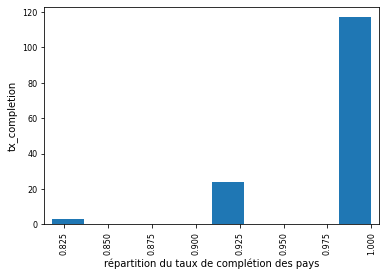

In [86]:
from pandas.plotting import scatter_matrix
scatter_matrix(data_etude_pays_completion)
plt.xlabel('répartition du taux de complétion des pays')

## Versus taux de complétion antérieur des 240 pays pour les 11 indicateurs :

Text(0.5, 0, 'répartition du taux de complétion des pays')

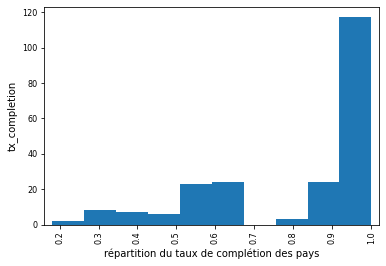

In [87]:
from pandas.plotting import scatter_matrix
scatter_matrix(data_etude_completion)
plt.xlabel('répartition du taux de complétion des pays')

In [88]:
data_etude_pays.isna().sum().sum()/(data_etude_pays.size)

0.01893939393939394

## taux de completion sous forme de graphique pour chaque indicateurs

In [89]:
data_etude_indicator=data_etude_pays.copy()

In [90]:
data_etude_indicator_completion = data_etude_indicator.transpose()

In [91]:
data_etude_indicator_completion

Country Name,Afghanistan,Albania,Algeria,Argentina,Armenia,Australia,Austria,Bahrain,Bangladesh,Barbados,...,Ukraine,United Arab Emirates,United Kingdom,United States,Uruguay,"Venezuela, RB",Vietnam,"Yemen, Rep.",Zambia,Zimbabwe
Percentage of population age 15-19 who completed sec schooling,9.450000e+00,3.685000e+01,1.922000e+01,1.726000e+01,3.851000e+01,3.203000e+01,7.060000e+00,2.077000e+01,3.241000e+01,6.340000,...,3.491000e+01,4.523000e+01,5.881000e+01,3.390000e+01,8.910000e+00,3.621000e+01,1.191000e+01,9.790000e+00,1.313000e+01,1.950000e+00
Percentage of population age 20-24 completed sec schooling,1.560000e+01,5.596000e+01,2.237000e+01,4.537000e+01,3.647000e+01,7.663000e+01,7.098000e+01,4.992000e+01,4.088000e+01,15.330000,...,1.526000e+01,5.040000e+01,6.370000e+01,3.763000e+01,3.495000e+01,5.470000e+01,3.291000e+01,1.924000e+01,1.532000e+01,4.400000e+00
"Average years of secondary schooling, 15-19, female",1.670000e+00,5.260000e+00,2.740000e+00,2.990000e+00,6.190000e+00,3.960000e+00,2.080000e+00,3.030000e+00,4.350000e+00,3.540000,...,4.950000e+00,3.890000e+00,5.060000e+00,4.330000e+00,2.230000e+00,3.160000e+00,1.760000e+00,1.640000e+00,2.200000e+00,1.210000e+00
"Average years of secondary schooling, 20-24, female",9.600000e-01,3.140000e+00,3.280000e+00,3.450000e+00,6.650000e+00,5.260000e+00,6.610000e+00,4.080000e+00,4.820000e+00,4.560000,...,5.440000e+00,4.630000e+00,6.300000e+00,5.920000e+00,3.460000e+00,3.850000e+00,4.070000e+00,2.020000e+00,1.330000e+00,2.000000e+00
Personal computers (per 100 people),3.901483e-01,4.593538e+00,1.030597e+00,9.056130e+00,9.851017e+00,NaN,6.064134e+01,5.182619e+01,2.415981e+00,14.621593,...,4.525581e+00,2.871418e+01,8.017036e+01,7.991549e+01,1.353320e+01,9.260681e+00,9.467318e+00,2.903922e+00,1.142108e+00,7.431140e+00
Internet users (per 100 people,1.059573e+01,6.636344e+01,4.294553e+01,7.015076e+01,6.200000e+01,8.823866e+01,8.432333e+01,9.799998e+01,1.824694e+01,79.549398,...,5.248181e+01,9.060001e+01,9.477580e+01,7.617674e+01,6.640000e+01,6.000000e+01,4.650000e+01,2.457921e+01,2.550658e+01,2.311999e+01
GDP per capita (current US$),5.617787e+02,4.124982e+03,3.916882e+03,1.244032e+04,3.614688e+03,4.992782e+04,4.467635e+04,2.257909e+04,1.358779e+03,15891.626549,...,2.185728e+03,3.762221e+04,4.034141e+04,5.763816e+04,1.522057e+04,1.569241e+04,2.214388e+03,9.903348e+02,1.269574e+03,1.029077e+03
"Population, ages 15-24, total",7.252785e+06,5.562690e+05,6.467818e+06,6.886530e+06,4.469580e+05,2.914620e+06,9.646290e+05,1.326090e+05,3.440059e+07,37585.000000,...,4.842803e+06,7.436080e+05,7.731522e+06,4.514752e+07,5.192980e+05,5.479911e+06,1.693981e+07,5.995687e+06,3.068044e+06,3.333716e+06
Population growth (annual %),2.689163e+00,-1.598804e-01,1.825463e+00,9.847419e-01,2.693023e-01,1.410064e+00,1.314007e+00,3.812797e+00,1.080165e+00,0.273711,...,-3.313805e-01,1.251759e+00,7.775418e-01,6.928013e-01,3.622692e-01,1.317057e+00,1.071293e+00,2.451502e+00,3.002816e+00,2.336070e+00
"Population, total",3.465603e+07,2.876101e+06,4.060605e+07,4.384743e+07,2.924816e+06,2.412716e+07,8.747358e+06,1.425171e+06,1.629516e+08,284996.000000,...,4.500464e+07,9.269612e+06,6.563724e+07,3.231275e+08,3.444006e+06,3.156818e+07,9.270110e+07,2.758421e+07,1.659139e+07,1.615036e+07


In [92]:
data_etude_indicator_completion['tx_completion']= 1-(data_etude_indicator_completion.shape[1] - data_etude_indicator_completion.count(axis=1))/data_etude_indicator_completion.shape[1] 




In [93]:
data_etude_indicator_taux = data_etude_indicator_completion.drop(data_etude_indicator_completion.loc[:,data_etude_indicator_completion.columns!="tx_completion"],1,inplace=False)




/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_17606/1567316356.py:1: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  data_etude_indicator_taux = data_etude_indicator_completion.drop(data_etude_indicator_completion.loc[:,data_etude_indicator_completion.columns!="tx_completion"],1,inplace=False)


In [94]:
data_etude_indicator_taux.sort_values(by='tx_completion', ascending=True)

Country Name,tx_completion
Government expenditure in secondary institution,0.868056
Personal computers (per 100 people),0.930556
"Population, ages 15-24, total",0.993056
Percentage of population age 15-19 who completed sec schooling,1.000000
Percentage of population age 20-24 completed sec schooling,1.000000
"Average years of secondary schooling, 15-19, female",1.000000
"Average years of secondary schooling, 20-24, female",1.000000
Internet users (per 100 people,1.000000
GDP per capita (current US$),1.000000
Population growth (annual %),1.000000


<AxesSubplot:>

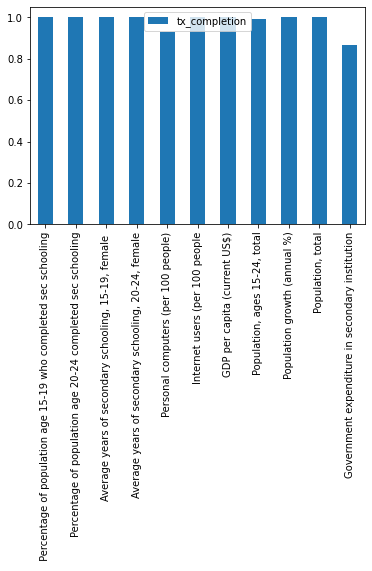

In [95]:
data_etude_completion = pd.DataFrame(data_etude_indicator_taux, columns=["tx_completion"])

data_etude_completion.plot.bar()

Text(0.5, 0, 'répartition du taux de complétion des indicateurs')

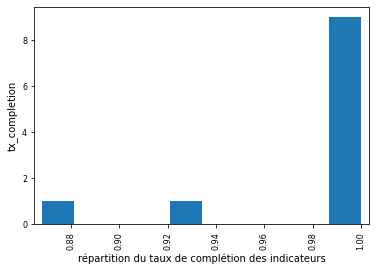

In [96]:
from pandas.plotting import scatter_matrix
scatter_matrix(data_etude_indicator_taux)
plt.xlabel('répartition du taux de complétion des indicateurs')

In [97]:
data_etude_indicator_completion

Country Name,Afghanistan,Albania,Algeria,Argentina,Armenia,Australia,Austria,Bahrain,Bangladesh,Barbados,...,United Arab Emirates,United Kingdom,United States,Uruguay,"Venezuela, RB",Vietnam,"Yemen, Rep.",Zambia,Zimbabwe,tx_completion
Percentage of population age 15-19 who completed sec schooling,9.450000e+00,3.685000e+01,1.922000e+01,1.726000e+01,3.851000e+01,3.203000e+01,7.060000e+00,2.077000e+01,3.241000e+01,6.340000,...,4.523000e+01,5.881000e+01,3.390000e+01,8.910000e+00,3.621000e+01,1.191000e+01,9.790000e+00,1.313000e+01,1.950000e+00,1.000000
Percentage of population age 20-24 completed sec schooling,1.560000e+01,5.596000e+01,2.237000e+01,4.537000e+01,3.647000e+01,7.663000e+01,7.098000e+01,4.992000e+01,4.088000e+01,15.330000,...,5.040000e+01,6.370000e+01,3.763000e+01,3.495000e+01,5.470000e+01,3.291000e+01,1.924000e+01,1.532000e+01,4.400000e+00,1.000000
"Average years of secondary schooling, 15-19, female",1.670000e+00,5.260000e+00,2.740000e+00,2.990000e+00,6.190000e+00,3.960000e+00,2.080000e+00,3.030000e+00,4.350000e+00,3.540000,...,3.890000e+00,5.060000e+00,4.330000e+00,2.230000e+00,3.160000e+00,1.760000e+00,1.640000e+00,2.200000e+00,1.210000e+00,1.000000
"Average years of secondary schooling, 20-24, female",9.600000e-01,3.140000e+00,3.280000e+00,3.450000e+00,6.650000e+00,5.260000e+00,6.610000e+00,4.080000e+00,4.820000e+00,4.560000,...,4.630000e+00,6.300000e+00,5.920000e+00,3.460000e+00,3.850000e+00,4.070000e+00,2.020000e+00,1.330000e+00,2.000000e+00,1.000000
Personal computers (per 100 people),3.901483e-01,4.593538e+00,1.030597e+00,9.056130e+00,9.851017e+00,NaN,6.064134e+01,5.182619e+01,2.415981e+00,14.621593,...,2.871418e+01,8.017036e+01,7.991549e+01,1.353320e+01,9.260681e+00,9.467318e+00,2.903922e+00,1.142108e+00,7.431140e+00,0.930556
Internet users (per 100 people,1.059573e+01,6.636344e+01,4.294553e+01,7.015076e+01,6.200000e+01,8.823866e+01,8.432333e+01,9.799998e+01,1.824694e+01,79.549398,...,9.060001e+01,9.477580e+01,7.617674e+01,6.640000e+01,6.000000e+01,4.650000e+01,2.457921e+01,2.550658e+01,2.311999e+01,1.000000
GDP per capita (current US$),5.617787e+02,4.124982e+03,3.916882e+03,1.244032e+04,3.614688e+03,4.992782e+04,4.467635e+04,2.257909e+04,1.358779e+03,15891.626549,...,3.762221e+04,4.034141e+04,5.763816e+04,1.522057e+04,1.569241e+04,2.214388e+03,9.903348e+02,1.269574e+03,1.029077e+03,1.000000
"Population, ages 15-24, total",7.252785e+06,5.562690e+05,6.467818e+06,6.886530e+06,4.469580e+05,2.914620e+06,9.646290e+05,1.326090e+05,3.440059e+07,37585.000000,...,7.436080e+05,7.731522e+06,4.514752e+07,5.192980e+05,5.479911e+06,1.693981e+07,5.995687e+06,3.068044e+06,3.333716e+06,0.993056
Population growth (annual %),2.689163e+00,-1.598804e-01,1.825463e+00,9.847419e-01,2.693023e-01,1.410064e+00,1.314007e+00,3.812797e+00,1.080165e+00,0.273711,...,1.251759e+00,7.775418e-01,6.928013e-01,3.622692e-01,1.317057e+00,1.071293e+00,2.451502e+00,3.002816e+00,2.336070e+00,1.000000
"Population, total",3.465603e+07,2.876101e+06,4.060605e+07,4.384743e+07,2.924816e+06,2.412716e+07,8.747358e+06,1.425171e+06,1.629516e+08,284996.000000,...,9.269612e+06,6.563724e+07,3.231275e+08,3.444006e+06,3.156818e+07,9.270110e+07,2.758421e+07,1.659139e+07,1.615036e+07,1.000000


In [98]:
#taux completion indicateurs

In [99]:
data_etude_pays

,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution
Country Name,,,,,,,,,,,
Afghanistan,9.45,15.60,1.67,0.96,0.390148,10.595726,561.778746,7252785.0,2.689163,34656032.0,NaN
Albania,36.85,55.96,5.26,3.14,4.593538,66.363445,4124.982390,556269.0,-0.159880,2876101.0,0.70164
Algeria,19.22,22.37,2.74,3.28,1.030597,42.945527,3916.881571,6467818.0,1.825463,40606052.0,NaN
Argentina,17.26,45.37,2.99,3.45,9.056130,70.150764,12440.320982,6886530.0,0.984742,43847430.0,2.05773
Armenia,38.51,36.47,6.19,6.65,9.851017,62.000000,3614.688357,446958.0,0.269302,2924816.0,1.21187
...,...,...,...,...,...,...,...,...,...,...,...
"Venezuela, RB",36.21,54.70,3.16,3.85,9.260681,60.000000,15692.412878,5479911.0,1.317057,31568179.0,1.19851
Vietnam,11.91,32.91,1.76,4.07,9.467318,46.500000,2214.387662,16939813.0,1.071293,92701100.0,2.72829
"Yemen, Rep.",9.79,19.24,1.64,2.02,2.903922,24.579208,990.334774,5995687.0,2.451502,27584213.0,NaN


In [100]:
data_etude_indicateurs = data_etude_pays.transpose()

In [101]:
data_etude_indicateurs['tx_completion']= 1-(data_etude_indicateurs.shape[1] - data_etude_indicateurs.count(axis=1))/data_etude_indicateurs.shape[1]



<AxesSubplot:>

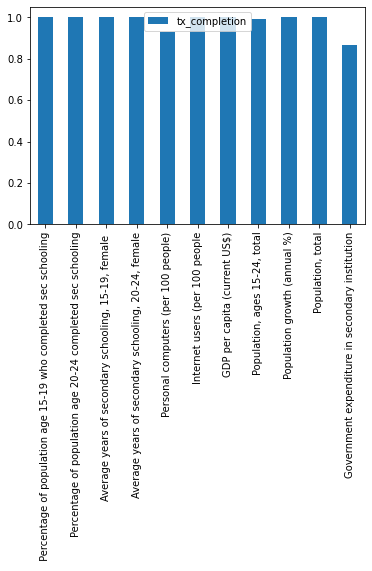

In [102]:
data_etude_indicateurs = pd.DataFrame(data_etude_indicateurs, columns=["tx_completion"])

data_etude_indicateurs.plot.bar()

Text(0.5, 0, 'répartition du taux de complétion des indicateurs')

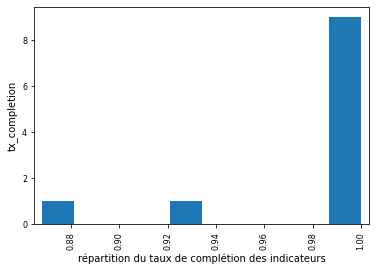

In [103]:
from pandas.plotting import scatter_matrix
scatter_matrix(data_etude_indicator_taux)
plt.xlabel('répartition du taux de complétion des indicateurs')

> notre dataset est de qualité, tous les indicateurs sélectionnés sont remplis à plus de 88% pour nos 141 pays

# 6.Analyse univariée


## correspondance indicateurs et definition


In [104]:
indicator_signification = indicator_tab[indicator_tab['Indicator Code'].isin(indicators)][['Indicator Name','Indicator Code']].groupby(['Indicator Name','Indicator Code']).count().reset_index().sort_values  (by='Indicator Code', ascending=True)
indicator_signification

,Indicator Name,Indicator Code
2,Barro-Lee: Percentage of population age 15-19 ...,BAR.SEC.CMPT.1519.ZS
3,Barro-Lee: Percentage of population age 20-24 ...,BAR.SEC.CMPT.2024.ZS
0,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.1519.FE
1,Barro-Lee: Average years of secondary schoolin...,BAR.SEC.SCHL.2024.FE
7,Personal computers (per 100 people),IT.CMP.PCMP.P2
6,Internet users (per 100 people),IT.NET.USER.P2
4,GDP per capita (current US$),NY.GDP.PCAP.CD
9,"Population, ages 15-24, total",SP.POP.1524.TO.UN
8,Population growth (annual %),SP.POP.GROW
10,"Population, total",SP.POP.TOTL


Pour chaque indicateur et pour la suite de notre étude on attribuera un coefficient différent afin de départager les pays. Pour ce faire, on va d'abord procéder à une analyse univariée puis bivariée afin de faire ces choix d'attribution de coefficient.

In [105]:
data_etude_pays.agg(['mean', 'var','count']).round(2)

,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution
mean,21.76,39.15,3.13,4.03,19.47,52.22,1.489975e+04,7.736205e+06,1.33,4.773999e+07,1.60
var,293.79,532.40,2.40,3.83,586.35,775.33,3.824882e+08,7.152529e+14,1.23,2.644139e+16,0.53
count,144.00,144.00,144.00,144.00,134.00,144.00,1.440000e+02,1.430000e+02,144.00,1.440000e+02,125.00


In [106]:
data_etude_pays.describe().round(2)

,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution
count,144.00,144.00,144.00,144.00,134.00,144.00,144.00,1.430000e+02,144.00,1.440000e+02,125.00
mean,21.76,39.15,3.13,4.03,19.47,52.22,14899.75,7.736205e+06,1.33,4.773999e+07,1.60
std,17.14,23.07,1.55,1.96,24.21,27.84,19557.31,2.674421e+07,1.11,1.626081e+08,0.73
min,0.17,0.19,0.12,0.46,0.02,4.00,285.73,2.295600e+04,-1.64,1.071220e+05,0.25
25%,9.77,19.07,2.08,2.46,2.59,25.64,1852.55,6.263125e+05,0.56,4.521220e+06,1.05
50%,17.84,37.30,3.14,4.10,9.13,54.00,5704.08,1.740436e+06,1.26,1.069777e+07,1.55
75%,28.69,56.82,4.21,5.48,26.06,76.56,18828.87,5.678546e+06,2.12,3.552920e+07,1.98
max,79.84,84.03,6.49,8.13,96.17,98.24,100573.14,2.441202e+08,3.83,1.378665e+09,3.74


In [107]:
column = data_etude_pays.columns

for i in column:
    print (data_etude_pays[[i]].idxmin(), data_etude_pays[[i]].min())

 Percentage of population age 15-19 who completed sec schooling    Sudan
dtype: object  Percentage of population age 15-19 who completed sec schooling    0.17
dtype: float64
Percentage of population age 20-24 completed sec schooling    New Zealand
dtype: object Percentage of population age 20-24 completed sec schooling    0.19
dtype: float64
Average years of secondary schooling, 15-19, female     Sudan
dtype: object Average years of secondary schooling, 15-19, female     0.12
dtype: float64
Average years of secondary schooling, 20-24, female    Mozambique
dtype: object Average years of secondary schooling, 20-24, female    0.46
dtype: float64
Personal computers (per 100 people)    Congo, Dem. Rep.
dtype: object Personal computers (per 100 people)    0.022211
dtype: float64
Internet users (per 100 people    Central African Republic
dtype: object Internet users (per 100 people    4.0
dtype: float64
GDP per capita (current US$)    Burundi
dtype: object GDP per capita (current US$)    285.

In [108]:
df_univarie = pd.DataFrame(data=data_etude_pays,index=list(data_etude_pays.index),columns=list(data_etude_pays.columns))
df_univarie=df_univarie.rename_axis('Country Name')

df_univarie

,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution
Country Name,,,,,,,,,,,
Afghanistan,9.45,15.60,1.67,0.96,0.390148,10.595726,561.778746,7252785.0,2.689163,34656032.0,NaN
Albania,36.85,55.96,5.26,3.14,4.593538,66.363445,4124.982390,556269.0,-0.159880,2876101.0,0.70164
Algeria,19.22,22.37,2.74,3.28,1.030597,42.945527,3916.881571,6467818.0,1.825463,40606052.0,NaN
Argentina,17.26,45.37,2.99,3.45,9.056130,70.150764,12440.320982,6886530.0,0.984742,43847430.0,2.05773
Armenia,38.51,36.47,6.19,6.65,9.851017,62.000000,3614.688357,446958.0,0.269302,2924816.0,1.21187
...,...,...,...,...,...,...,...,...,...,...,...
"Venezuela, RB",36.21,54.70,3.16,3.85,9.260681,60.000000,15692.412878,5479911.0,1.317057,31568179.0,1.19851
Vietnam,11.91,32.91,1.76,4.07,9.467318,46.500000,2214.387662,16939813.0,1.071293,92701100.0,2.72829
"Yemen, Rep.",9.79,19.24,1.64,2.02,2.903922,24.579208,990.334774,5995687.0,2.451502,27584213.0,NaN


In [109]:
df_univarie=df_univarie.copy()
df_univarie = pd.DataFrame(data=df_univarie, index=None)
df_univarie = df_univarie.reset_index()
df_univarie

,Country Name,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution
0,Afghanistan,9.45,15.60,1.67,0.96,0.390148,10.595726,561.778746,7252785.0,2.689163,34656032.0,NaN
1,Albania,36.85,55.96,5.26,3.14,4.593538,66.363445,4124.982390,556269.0,-0.159880,2876101.0,0.70164
2,Algeria,19.22,22.37,2.74,3.28,1.030597,42.945527,3916.881571,6467818.0,1.825463,40606052.0,NaN
3,Argentina,17.26,45.37,2.99,3.45,9.056130,70.150764,12440.320982,6886530.0,0.984742,43847430.0,2.05773
4,Armenia,38.51,36.47,6.19,6.65,9.851017,62.000000,3614.688357,446958.0,0.269302,2924816.0,1.21187
...,...,...,...,...,...,...,...,...,...,...,...,...
139,"Venezuela, RB",36.21,54.70,3.16,3.85,9.260681,60.000000,15692.412878,5479911.0,1.317057,31568179.0,1.19851
140,Vietnam,11.91,32.91,1.76,4.07,9.467318,46.500000,2214.387662,16939813.0,1.071293,92701100.0,2.72829
141,"Yemen, Rep.",9.79,19.24,1.64,2.02,2.903922,24.579208,990.334774,5995687.0,2.451502,27584213.0,NaN
142,Zambia,13.13,15.32,2.20,1.33,1.142108,25.506579,1269.573537,3068044.0,3.002816,16591390.0,0.25146


In [110]:
df_univarie2=df_univarie.set_index('Country Name')

In [111]:
df_univarie2.columns

Index([' Percentage of population age 15-19 who completed sec schooling',
       'Percentage of population age 20-24 completed sec schooling',
       'Average years of secondary schooling, 15-19, female ',
       'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population, ages 15-24, total',
       'Population growth (annual %)', 'Population, total',
       'Government expenditure in secondary institution'],
      dtype='object')

In [112]:
df_univarie2.nlargest(10,'Average years of secondary schooling, 15-19, female ').loc[:,'Average years of secondary schooling, 15-19, female ']

Country Name
Hong Kong SAR, China    6.49
Armenia                 6.19
Mauritius               6.14
Kazakhstan              6.03
Korea, Rep.             5.97
Malaysia                5.94
Tajikistan              5.82
Slovak Republic         5.77
Sri Lanka               5.71
Latvia                  5.70
Name: Average years of secondary schooling, 15-19, female , dtype: float64

In [113]:
df_univarie2.nlargest(10,'Average years of secondary schooling, 20-24, female').loc[:,'Average years of secondary schooling, 20-24, female']

Country Name
Germany                 8.13
Slovak Republic         7.78
Slovenia                7.76
Lithuania               7.67
Serbia                  7.61
Latvia                  7.44
Italy                   6.99
Romania                 6.99
Hong Kong SAR, China    6.83
Kyrgyz Republic         6.81
Name: Average years of secondary schooling, 20-24, female, dtype: float64

In [114]:
df_univarie.columns

Index(['Country Name',
       ' Percentage of population age 15-19 who completed sec schooling',
       'Percentage of population age 20-24 completed sec schooling',
       'Average years of secondary schooling, 15-19, female ',
       'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population, ages 15-24, total',
       'Population growth (annual %)', 'Population, total',
       'Government expenditure in secondary institution'],
      dtype='object')

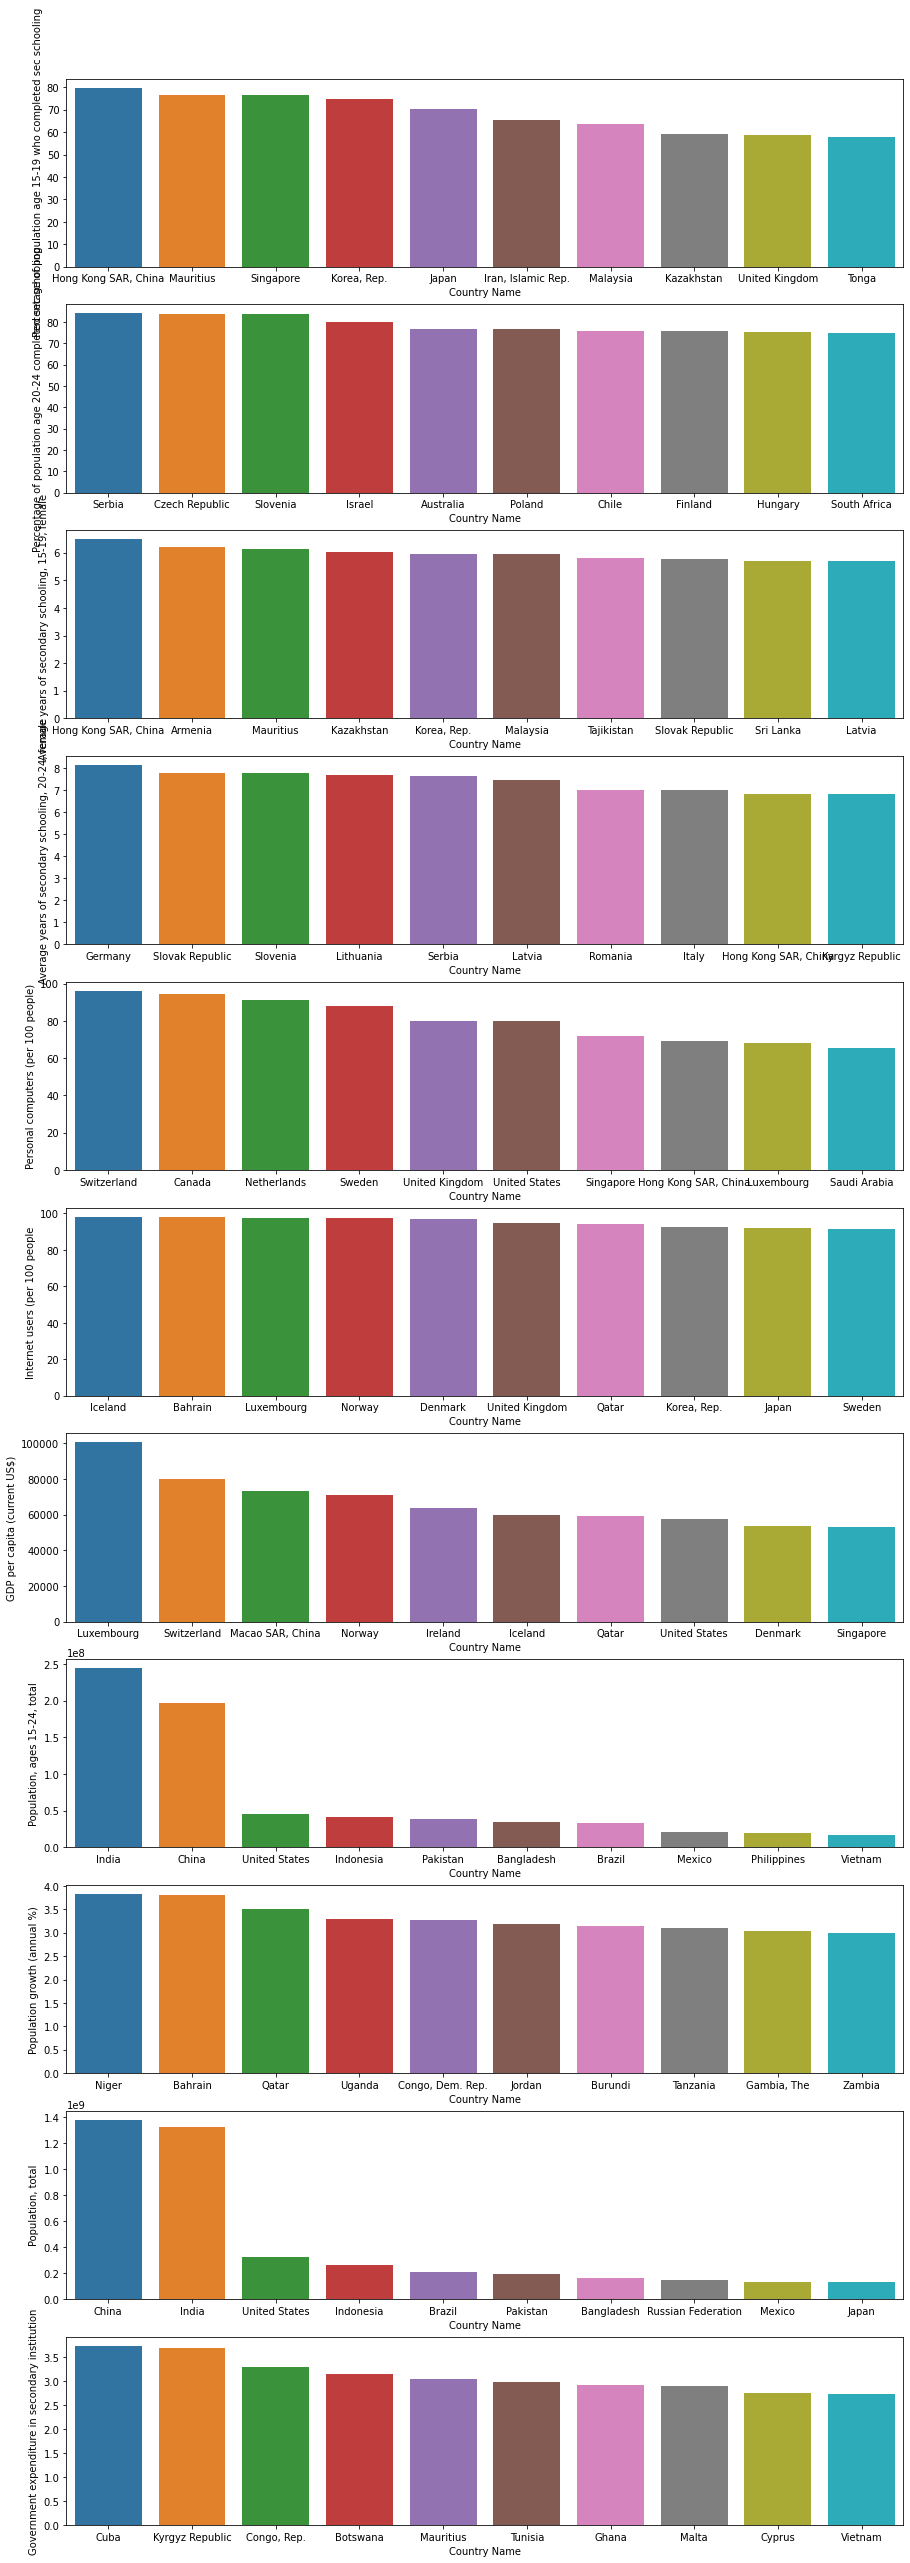

In [115]:
%matplotlib inline
f, ax = plt. subplots (nrows=11, ncols=1, figsize=(15,45))

for i, col in enumerate (df_univarie.drop('Country Name', axis = 1).columns):


    sns.barplot (x = df_univarie.sort_values(by = col, ascending = False)['Country Name'].head(10), y = df_univarie[col], ax=ax[i])

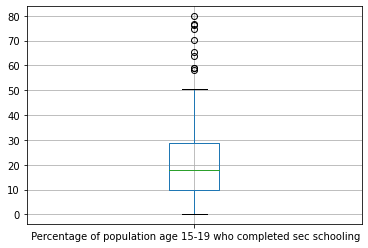

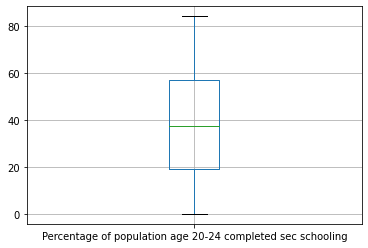

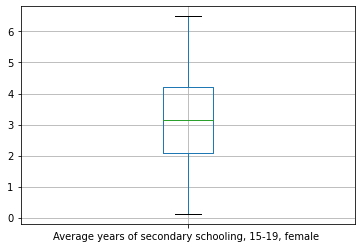

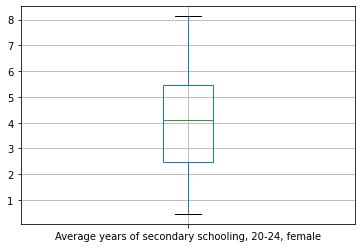

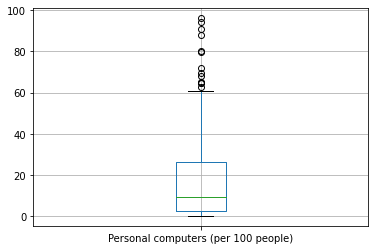

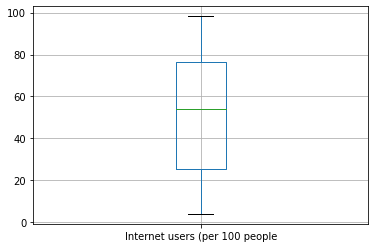

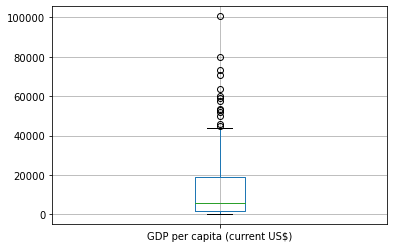

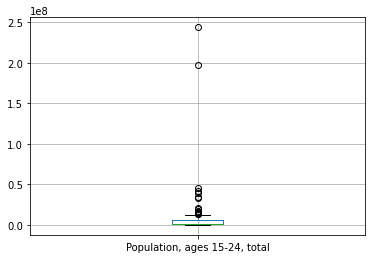

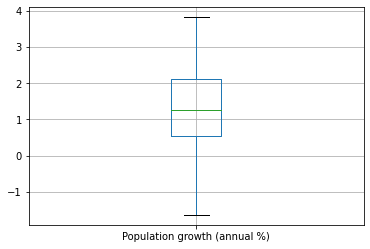

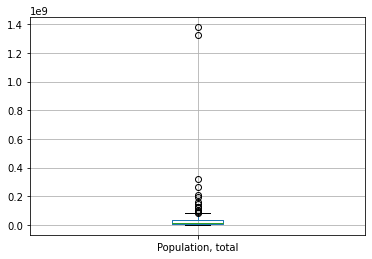

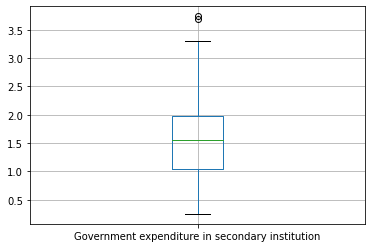

In [116]:
import matplotlib.pyplot as plt

for column in data_etude_pays:
    plt.figure()
    data_etude_pays.boxplot([column])
    

> Analyse des boîtes à moustache
- outliers dans la population totale et dispersion assez similaires entre l'indicateur de la population totale et de la population des 15-24 ans
- on voit beaucoup d'outliers pour le pourcentage de personnes ayant un ordinateur personnel, la distribution autour de la médiane étant plus "raisonnable" pour internet, ce qui peut nous orienter dans notre choix en insistant sur les personnes ayant un ordinateur personnel
- on peut considérer qu'il faudra faire attention aux pays ayant la population totale la plus élevée et qu'il faudra par la suite "normaliser" la data pour que ce seul indicateur n'emporte pas sur les autres

On ne va sans doute pas garder ces 2 indicateurs au risque de créer une redondance mais créer un nouvel indicateur "population cible etudiante" à partir des 3 indicateurs :
Percentage of population age 15-19 
Percentage of population age 20-24
Population, ages 15-24, total 



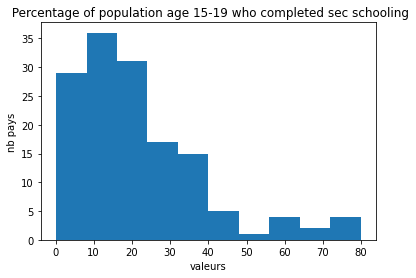

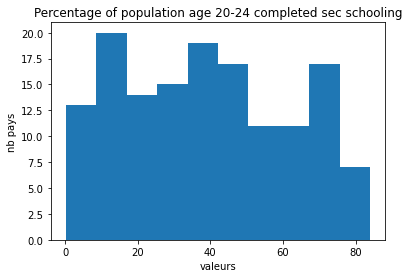

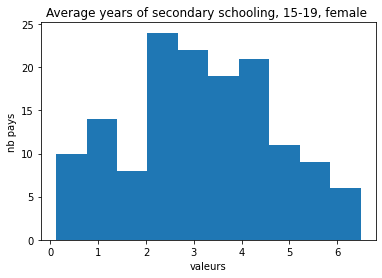

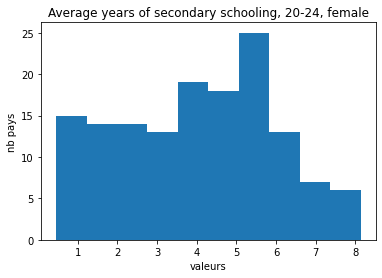

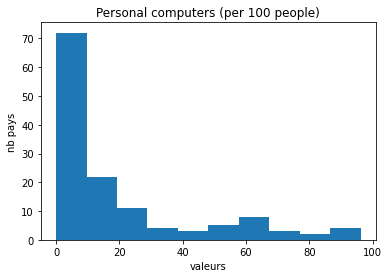

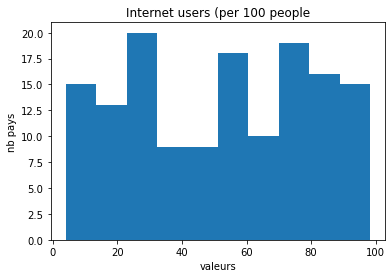

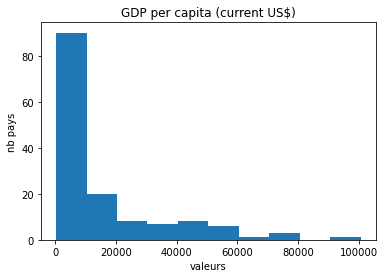

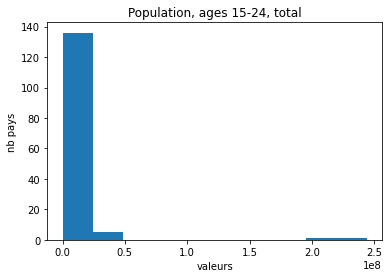

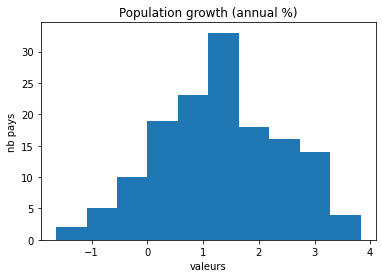

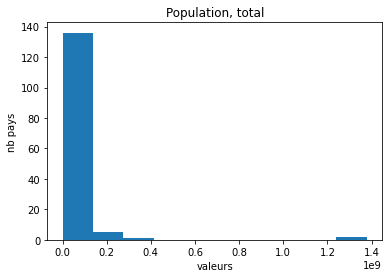

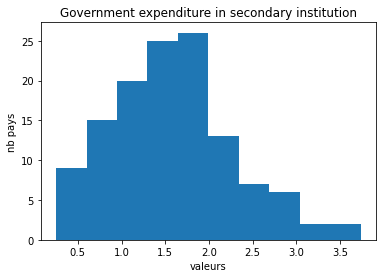

In [117]:
for i in data_etude_pays.columns: 
    plt.figure()
    plt.title(i)
    plt.xlabel('valeurs')
    plt.ylabel('nb pays')
    plt.hist(data_etude_pays[i])

> Pour les outliers, prenons connaissance des pays dont il s'agit et si cela nous semble cohérent :

In [118]:
column = data_etude_pays.columns

for i in column:
    print (data_etude_pays[[i]].idxmax(), data_etude_pays[[i]].max())

 Percentage of population age 15-19 who completed sec schooling    Hong Kong SAR, China
dtype: object  Percentage of population age 15-19 who completed sec schooling    79.84
dtype: float64
Percentage of population age 20-24 completed sec schooling    Serbia
dtype: object Percentage of population age 20-24 completed sec schooling    84.03
dtype: float64
Average years of secondary schooling, 15-19, female     Hong Kong SAR, China
dtype: object Average years of secondary schooling, 15-19, female     6.49
dtype: float64
Average years of secondary schooling, 20-24, female    Germany
dtype: object Average years of secondary schooling, 20-24, female    8.13
dtype: float64
Personal computers (per 100 people)    Switzerland
dtype: object Personal computers (per 100 people)    96.170657
dtype: float64
Internet users (per 100 people    Iceland
dtype: object Internet users (per 100 people    98.240016
dtype: float64
GDP per capita (current US$)    Luxembourg
dtype: object GDP per capita (current 

>Effectivement il n'est pas étonnant de retrouver des pays d'Asie aux sein des outliers représentant la population totale. Il faudra prendre en compte cela au moment de calculer les scores. Pour ce faire, on procèdera à une normalisation de la donnée.

# 7.matrice de corrélation, analyses bivariées

<AxesSubplot:>

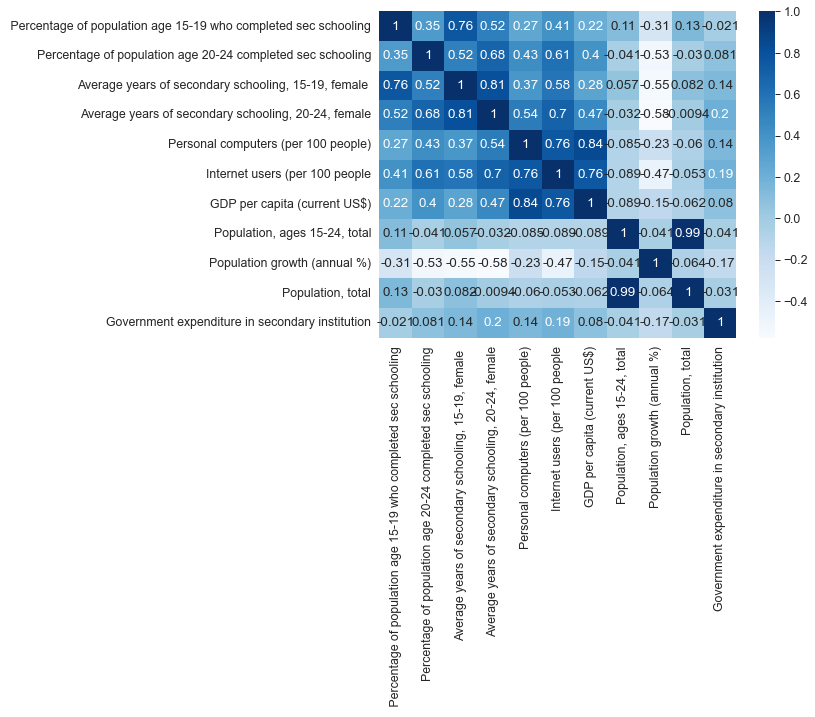

In [119]:
plt.figure(figsize=(8,6))
import seaborn as sns
 
sns.set(rc={'figure.figsize': (14, 5)})
sns.set_context('paper', font_scale=1.4)
data_etude_pays_corr = data_etude_pays.corr()
sns.heatmap(data_etude_pays_corr, annot=True, cmap='Blues')

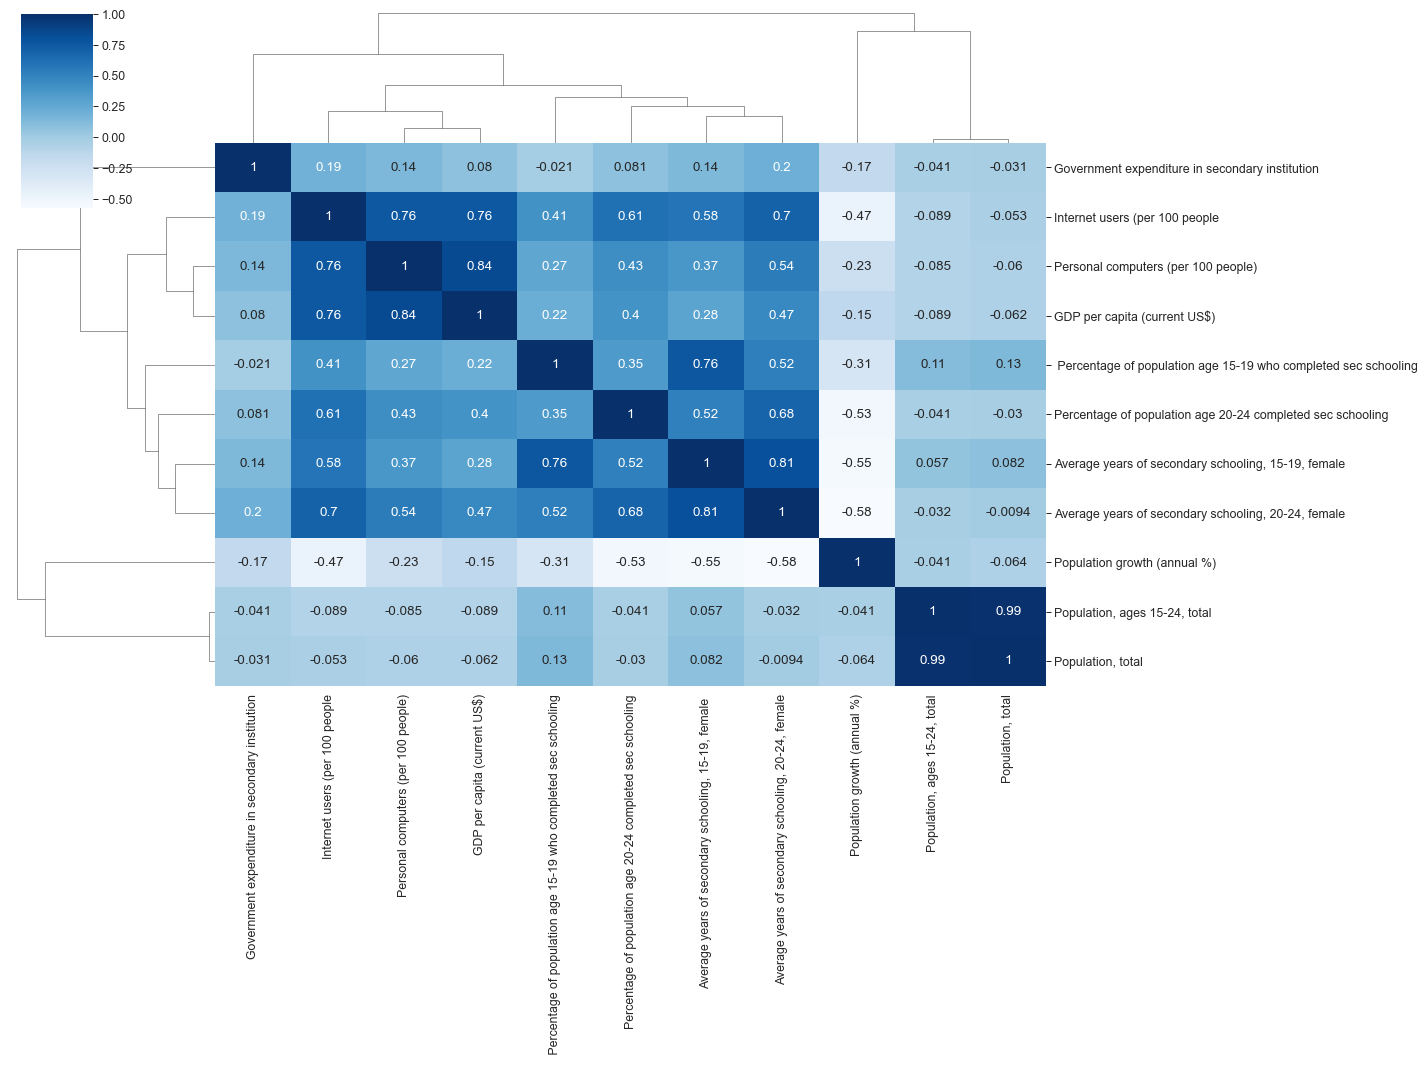

In [120]:
sns.clustermap(data_etude_pays_corr, figsize=(20, 15), annot=True, cmap='Blues')

In [121]:
plt.savefig("correlation_matrix.png")

<Figure size 1008x360 with 0 Axes>

<AxesSubplot:xlabel='Population, ages 15-24, total', ylabel='Population, total'>

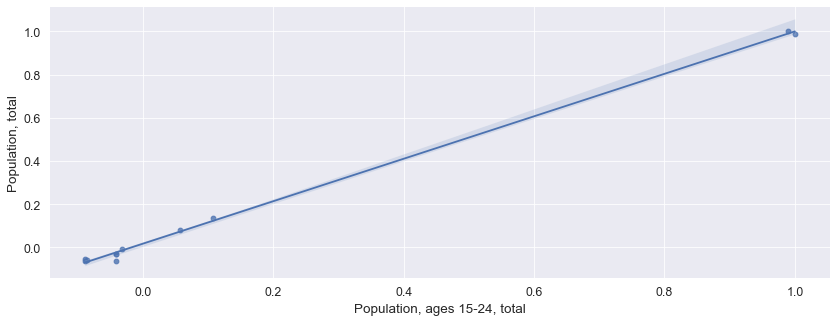

In [122]:
import seaborn as sns

sns.regplot(x=data_etude_pays_corr['Population, ages 15-24, total'], y=data_etude_pays_corr['Population, total'])

In [123]:
data_etude_pays_corr.columns

Index([' Percentage of population age 15-19 who completed sec schooling',
       'Percentage of population age 20-24 completed sec schooling',
       'Average years of secondary schooling, 15-19, female ',
       'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population, ages 15-24, total',
       'Population growth (annual %)', 'Population, total',
       'Government expenditure in secondary institution'],
      dtype='object')

> on remarque que population total, population 15-24 et population 20-24 sont tres fortement corrélés. 

In [124]:
data_etude_pays_corr.columns

Index([' Percentage of population age 15-19 who completed sec schooling',
       'Percentage of population age 20-24 completed sec schooling',
       'Average years of secondary schooling, 15-19, female ',
       'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population, ages 15-24, total',
       'Population growth (annual %)', 'Population, total',
       'Government expenditure in secondary institution'],
      dtype='object')

/Users/laureagrech/opt/anaconda3/lib/python3.9/site-packages/seaborn/axisgrid.py:156: UserWarning: The handle <matplotlib.patches.Patch object at 0x7f96cae2c0a0> has a label of '_nolegend_' which cannot be automatically added to the legend.
  figlegend = self._figure.legend(handles, labels, **kwargs)


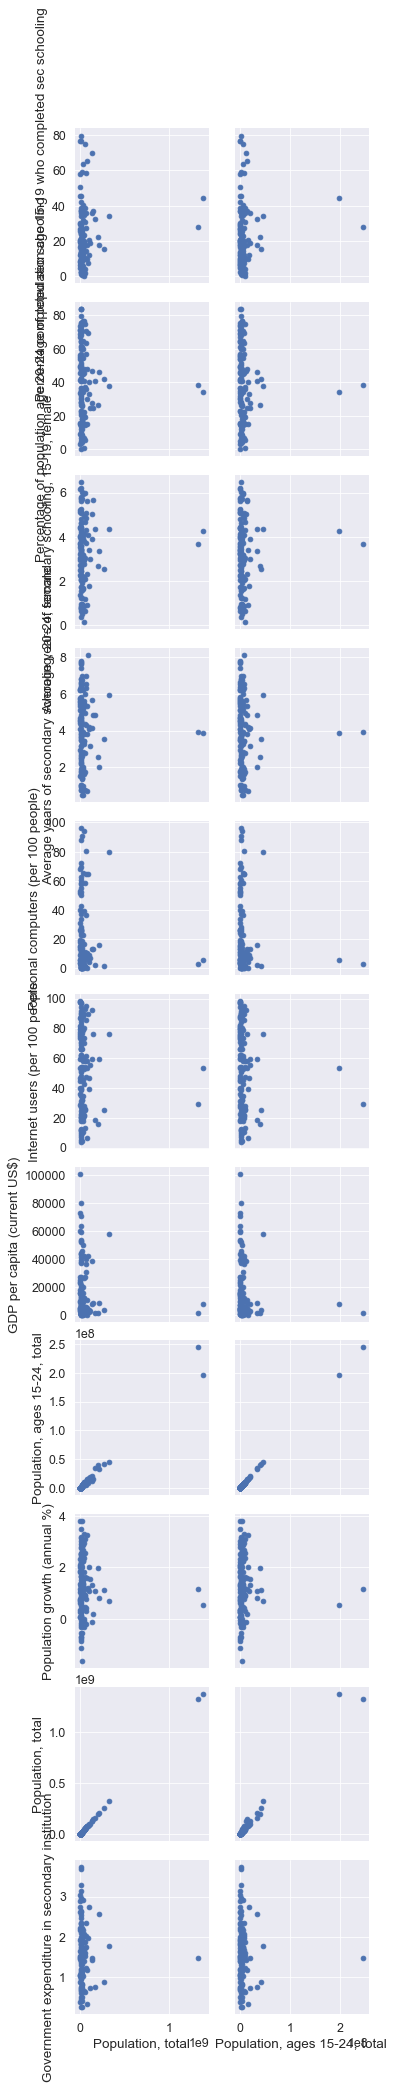

In [125]:
bivarie = sns.PairGrid(data_etude_pays,
x_vars=["Population, total", "Population, ages 15-24, total"])
y_vars=[' Percentage of population age 15-19 ', 'Percentage of population age 20-24']
bivarie.map(plt.scatter)
bivarie.add_legend()

In [126]:
data_etude_pays[["Population, ages 15-24, total", "Population, total"]].corr()


,"Population, ages 15-24, total","Population, total"
"Population, ages 15-24, total",1.000000,0.989896
"Population, total",0.989896,1.000000


> Cette analyse nous confirme la très forte corrélation entre la population agée de 15-24 ans et la population totale. Nous choisirons par la suite de supprimer l'indicateur Population total

In [127]:
data_etude_pays[["GDP per capita (current US$)", "Population, total"]].corr()

,GDP per capita (current US$),"Population, total"
GDP per capita (current US$),1.000000,-0.062391
"Population, total",-0.062391,1.000000


*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.


<AxesSubplot:xlabel='GDP per capita (current US$)', ylabel='Population, total'>

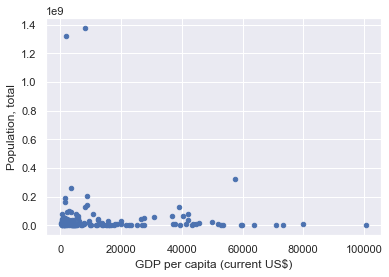

In [188]:
data_etude_pays.plot.scatter('GDP per capita (current US$)', 'Population, total')

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.


<AxesSubplot:xlabel='GDP per capita (current US$)', ylabel='Government expenditure in secondary institution'>

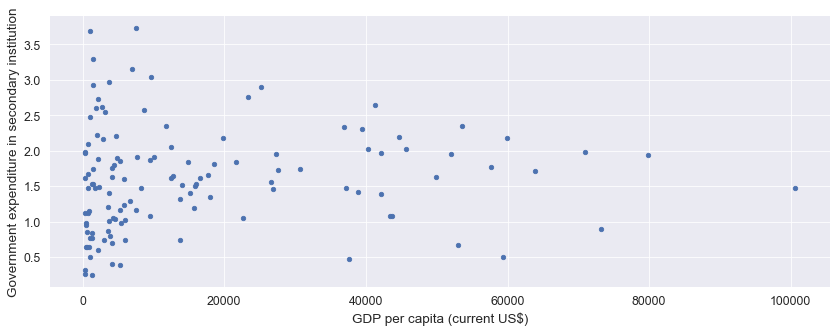

In [128]:
data_etude_pays.plot.scatter('GDP per capita (current US$)', 'Government expenditure in secondary institution')

>On remarque que plus le pays a un PIB faible. Cela nous sera donc utile pour notre scoring au moment d'affecter les coefficients aux indicateurs. On pourra donner un coefficient plus élevé à ce moment aux dépenses de l'état pour l'éducation.

/Users/laureagrech/opt/anaconda3/lib/python3.9/site-packages/seaborn/axisgrid.py:156: UserWarning: The handle <matplotlib.patches.Patch object at 0x7f9735d9f280> has a label of '_nolegend_' which cannot be automatically added to the legend.
  figlegend = self._figure.legend(handles, labels, **kwargs)


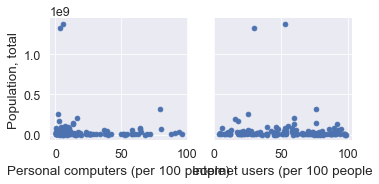

In [129]:
bivarie = sns.PairGrid(data_etude_pays,
x_vars=["Personal computers (per 100 people)", "Internet users (per 100 people"],
y_vars=["Population, total"])
bivarie.map(plt.scatter)
bivarie.add_legend()

> La population totale n'est pas corrélée aux indicateurs "personal computers pers 100 people" ni aux "internet users per 100 people". Cela peut s'expliquer par la prédominance d'internet dans le monde entier. Nous gardons cependant ces indicateurs car ils représent une condition sine qua none pour l'expansion de notre activité de cours en ligne mais ne semble pas être corrélée à la population totale des pays.


In [130]:
data_etude_pays.corr()

,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution
Percentage of population age 15-19 who completed sec schooling,1.000000,0.352454,0.762743,0.520557,0.268082,0.407768,0.215299,0.108106,-0.306482,0.133786,-0.021247
Percentage of population age 20-24 completed sec schooling,0.352454,1.000000,0.517675,0.681362,0.432612,0.611553,0.396242,-0.040870,-0.534013,-0.030003,0.081466
"Average years of secondary schooling, 15-19, female",0.762743,0.517675,1.000000,0.808156,0.372072,0.584080,0.282151,0.057415,-0.550017,0.082179,0.136558
"Average years of secondary schooling, 20-24, female",0.520557,0.681362,0.808156,1.000000,0.542655,0.696657,0.465880,-0.032012,-0.577484,-0.009410,0.199313
Personal computers (per 100 people),0.268082,0.432612,0.372072,0.542655,1.000000,0.756803,0.843529,-0.085099,-0.228668,-0.060419,0.139865
Internet users (per 100 people,0.407768,0.611553,0.584080,0.696657,0.756803,1.000000,0.757201,-0.088790,-0.468898,-0.053165,0.190940
GDP per capita (current US$),0.215299,0.396242,0.282151,0.465880,0.843529,0.757201,1.000000,-0.089229,-0.146702,-0.062391,0.080045
"Population, ages 15-24, total",0.108106,-0.040870,0.057415,-0.032012,-0.085099,-0.088790,-0.089229,1.000000,-0.041176,0.989896,-0.040685
Population growth (annual %),-0.306482,-0.534013,-0.550017,-0.577484,-0.228668,-0.468898,-0.146702,-0.041176,1.000000,-0.064096,-0.167765
"Population, total",0.133786,-0.030003,0.082179,-0.009410,-0.060419,-0.053165,-0.062391,0.989896,-0.064096,1.000000,-0.030670


In [131]:
corr_df = data_etude_pays.corr(method='pearson')

data_etude_pays.style.background_gradient(cmap='coolwarm')

,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution
Country Name,,,,,,,,,,,
Afghanistan,9.450000,15.600000,1.670000,0.960000,0.390148,10.595726,561.778746,7252785.000000,2.689163,34656032.000000,nan
Albania,36.850000,55.960000,5.260000,3.140000,4.593538,66.363445,4124.982390,556269.000000,-0.159880,2876101.000000,0.701640
Algeria,19.220000,22.370000,2.740000,3.280000,1.030597,42.945527,3916.881571,6467818.000000,1.825463,40606052.000000,nan
Argentina,17.260000,45.370000,2.990000,3.450000,9.056130,70.150764,12440.320982,6886530.000000,0.984742,43847430.000000,2.057730
Armenia,38.510000,36.470000,6.190000,6.650000,9.851017,62.000000,3614.688357,446958.000000,0.269302,2924816.000000,1.211870
Australia,32.030000,76.630000,3.960000,5.260000,nan,88.238658,49927.819509,2914620.000000,1.410064,24127159.000000,1.625120
Austria,7.060000,70.980000,2.080000,6.610000,60.641342,84.323331,44676.345835,964629.000000,1.314007,8747358.000000,2.197800
Bahrain,20.770000,49.920000,3.030000,4.080000,51.826192,97.999981,22579.093420,132609.000000,3.812797,1425171.000000,1.048110
Bangladesh,32.410000,40.880000,4.350000,4.820000,2.415981,18.246938,1358.779029,34400594.000000,1.080165,162951560.000000,0.764320


>Dernière manipulation du dataset :
On ne va garder qu'un indicateur en en créant un nouveau à partir des 3 indicateurs afin de simplifier notre dataset et diminuer le nombre d'indicateurs
' Percentage of population age 15-19 '+ 'Percentage of population age 20-24'* "Population, total"


In [132]:
data_etude_pays_population_cible = data_etude_pays.copy()

> On crée une nouvelle colonne qui comprend les 3 indicateurs Population totale, percentenge 15-19 et percentage 20-24

In [133]:
data_etude_pays_population_cible.columns

Index([' Percentage of population age 15-19 who completed sec schooling',
       'Percentage of population age 20-24 completed sec schooling',
       'Average years of secondary schooling, 15-19, female ',
       'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population, ages 15-24, total',
       'Population growth (annual %)', 'Population, total',
       'Government expenditure in secondary institution'],
      dtype='object')

In [134]:
data_etude_pays_population_cible['population cible niveau etudiant']= ((data_etude_pays_population_cible[' Percentage of population age 15-19 who completed sec schooling']+ data_etude_pays_population_cible['Percentage of population age 20-24 completed sec schooling'])* data_etude_pays_population_cible['Population, total'])/100
data_etude_pays_population_cible

,Percentage of population age 15-19 who completed sec schooling,Percentage of population age 20-24 completed sec schooling,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),"Population, ages 15-24, total",Population growth (annual %),"Population, total",Government expenditure in secondary institution,population cible niveau etudiant
Country Name,,,,,,,,,,,,
Afghanistan,9.45,15.60,1.67,0.96,0.390148,10.595726,561.778746,7252785.0,2.689163,34656032.0,NaN,8.681336e+06
Albania,36.85,55.96,5.26,3.14,4.593538,66.363445,4124.982390,556269.0,-0.159880,2876101.0,0.70164,2.669309e+06
Algeria,19.22,22.37,2.74,3.28,1.030597,42.945527,3916.881571,6467818.0,1.825463,40606052.0,NaN,1.688806e+07
Argentina,17.26,45.37,2.99,3.45,9.056130,70.150764,12440.320982,6886530.0,0.984742,43847430.0,2.05773,2.746165e+07
Armenia,38.51,36.47,6.19,6.65,9.851017,62.000000,3614.688357,446958.0,0.269302,2924816.0,1.21187,2.193027e+06
...,...,...,...,...,...,...,...,...,...,...,...,...
"Venezuela, RB",36.21,54.70,3.16,3.85,9.260681,60.000000,15692.412878,5479911.0,1.317057,31568179.0,1.19851,2.869863e+07
Vietnam,11.91,32.91,1.76,4.07,9.467318,46.500000,2214.387662,16939813.0,1.071293,92701100.0,2.72829,4.154863e+07
"Yemen, Rep.",9.79,19.24,1.64,2.02,2.903922,24.579208,990.334774,5995687.0,2.451502,27584213.0,NaN,8.007697e+06


In [135]:
data_etude_pays_population_cible=data_etude_pays_population_cible.drop(columns= [' Percentage of population age 15-19 who completed sec schooling', 'Percentage of population age 20-24 completed sec schooling','Population, ages 15-24, total', 'Population, total'])
data_etude_pays_population_cible

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
Country Name,,,,,,,,
Afghanistan,1.67,0.96,0.390148,10.595726,561.778746,2.689163,NaN,8.681336e+06
Albania,5.26,3.14,4.593538,66.363445,4124.982390,-0.159880,0.70164,2.669309e+06
Algeria,2.74,3.28,1.030597,42.945527,3916.881571,1.825463,NaN,1.688806e+07
Argentina,2.99,3.45,9.056130,70.150764,12440.320982,0.984742,2.05773,2.746165e+07
Armenia,6.19,6.65,9.851017,62.000000,3614.688357,0.269302,1.21187,2.193027e+06
...,...,...,...,...,...,...,...,...
"Venezuela, RB",3.16,3.85,9.260681,60.000000,15692.412878,1.317057,1.19851,2.869863e+07
Vietnam,1.76,4.07,9.467318,46.500000,2214.387662,1.071293,2.72829,4.154863e+07
"Yemen, Rep.",1.64,2.02,2.903922,24.579208,990.334774,2.451502,NaN,8.007697e+06


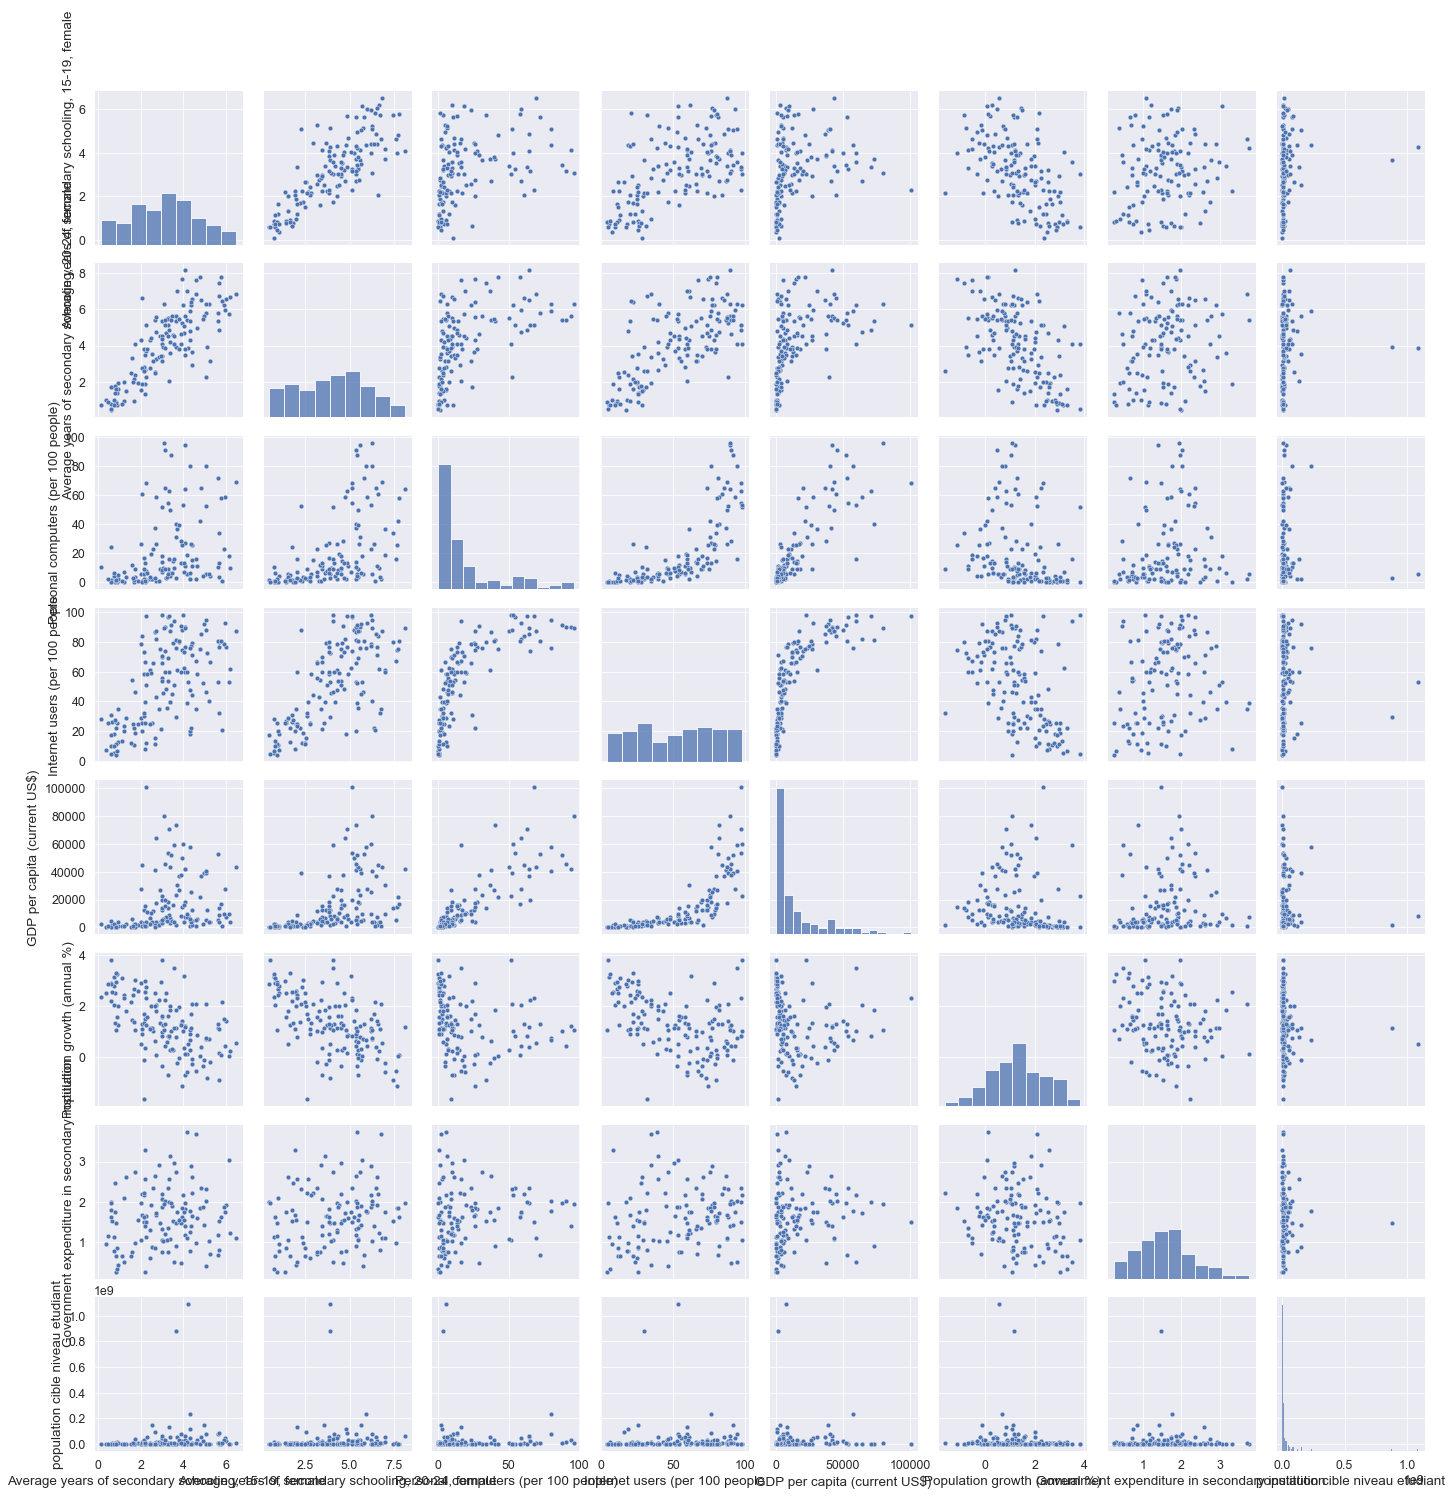

In [136]:
data_etude_pays_pairplot = data_etude_pays_population_cible[['Average years of secondary schooling, 15-19, female ', 'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population growth (annual %)',
       'Government expenditure in secondary institution',
       'population cible niveau etudiant']]

sns_plot = sns.pairplot(data_etude_pays_pairplot)
sns_plot.savefig("pairplot.png")

> On remarque pour l'histogramme de la population cible niveau étudiant que la courbe est fortement décalée à gauche, que donc très peu de pays ont beaucoup de personnes agées de 15 à 24 ans qui ont complété leur études supérieures (secondary schooling)

<AxesSubplot:>

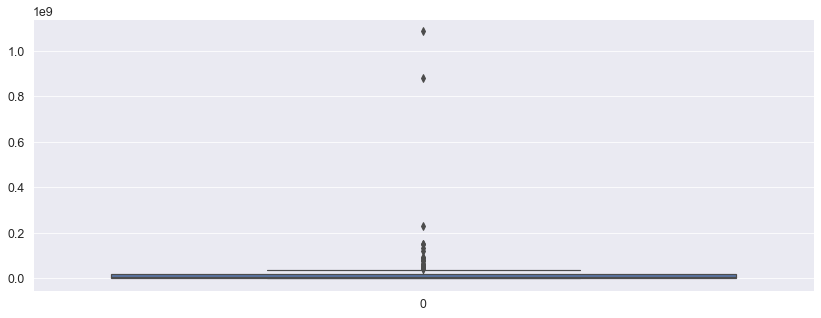

In [137]:
sns.boxplot(data=data_etude_pays_population_cible['population cible niveau etudiant'])

(array([137.,   4.,   1.,   0.,   0.,   0.,   0.,   0.,   1.,   1.]),
 array([6.17586332e+04, 1.08859825e+08, 2.17657891e+08, 3.26455956e+08,
        4.35254022e+08, 5.44052088e+08, 6.52850154e+08, 7.61648220e+08,
        8.70446286e+08, 9.79244352e+08, 1.08804242e+09]),
 <BarContainer object of 10 artists>)

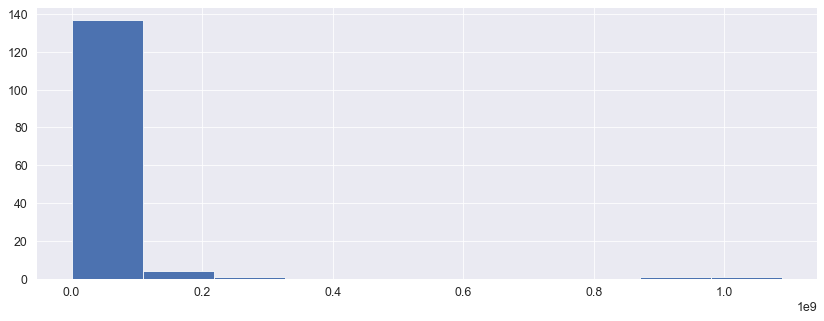

In [138]:
 plt.hist(data_etude_pays_population_cible['population cible niveau etudiant'])

# 8.Scoring

In [139]:
import pandas as pd
import numpy as np

data_etude_score = pd.DataFrame(data=data_etude_pays_population_cible,index=list(data_etude_pays_population_cible.index),columns=list(data_etude_pays_population_cible.columns))
data_etude_score

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
Afghanistan,1.67,0.96,0.390148,10.595726,561.778746,2.689163,NaN,8.681336e+06
Albania,5.26,3.14,4.593538,66.363445,4124.982390,-0.159880,0.70164,2.669309e+06
Algeria,2.74,3.28,1.030597,42.945527,3916.881571,1.825463,NaN,1.688806e+07
Argentina,2.99,3.45,9.056130,70.150764,12440.320982,0.984742,2.05773,2.746165e+07
Armenia,6.19,6.65,9.851017,62.000000,3614.688357,0.269302,1.21187,2.193027e+06
...,...,...,...,...,...,...,...,...
"Venezuela, RB",3.16,3.85,9.260681,60.000000,15692.412878,1.317057,1.19851,2.869863e+07
Vietnam,1.76,4.07,9.467318,46.500000,2214.387662,1.071293,2.72829,4.154863e+07
"Yemen, Rep.",1.64,2.02,2.903922,24.579208,990.334774,2.451502,NaN,8.007697e+06
Zambia,2.20,1.33,1.142108,25.506579,1269.573537,3.002816,0.25146,4.720250e+06


In [140]:
data_etude_score=data_etude_score.rename_axis('countries')
data_etude_score

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
countries,,,,,,,,
Afghanistan,1.67,0.96,0.390148,10.595726,561.778746,2.689163,NaN,8.681336e+06
Albania,5.26,3.14,4.593538,66.363445,4124.982390,-0.159880,0.70164,2.669309e+06
Algeria,2.74,3.28,1.030597,42.945527,3916.881571,1.825463,NaN,1.688806e+07
Argentina,2.99,3.45,9.056130,70.150764,12440.320982,0.984742,2.05773,2.746165e+07
Armenia,6.19,6.65,9.851017,62.000000,3614.688357,0.269302,1.21187,2.193027e+06
...,...,...,...,...,...,...,...,...
"Venezuela, RB",3.16,3.85,9.260681,60.000000,15692.412878,1.317057,1.19851,2.869863e+07
Vietnam,1.76,4.07,9.467318,46.500000,2214.387662,1.071293,2.72829,4.154863e+07
"Yemen, Rep.",1.64,2.02,2.903922,24.579208,990.334774,2.451502,NaN,8.007697e+06


## 8.1 Normalizing data

In [141]:
import seaborn as sns
# Min-Max Normalization
df_norm = (data_etude_score-data_etude_score.min())/(data_etude_score.max()-data_etude_score.min())
print("Dataset lissé en utilisant Pandas")
df_norm.head(10)

Dataset lissé en utilisant Pandas


,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
countries,,,,,,,,
Afghanistan,0.243328,0.065189,0.003827,0.069989,0.002753,0.791963,NaN,0.007923
Albania,0.806907,0.349413,0.047544,0.661751,0.038283,0.270628,0.129169,0.002397
Algeria,0.411303,0.367666,0.010488,0.413259,0.036207,0.633918,NaN,0.015466
Argentina,0.450549,0.389831,0.093958,0.701939,0.121198,0.480078,0.518270,0.025184
Armenia,0.952904,0.807040,0.102225,0.615450,0.033194,0.349163,0.275569,0.001959
Australia,0.602826,0.625815,NaN,0.893874,0.494998,0.557906,0.394142,0.024040
Austria,0.307692,0.801825,0.630474,0.852327,0.442634,0.540329,0.558460,0.006218
Bahrain,0.456829,0.471969,0.538792,0.997453,0.222295,0.997572,0.228582,0.000869
Bangladesh,0.664050,0.568449,0.024897,0.151177,0.010700,0.497539,0.147154,0.109713


In [142]:
df_norm_bar=df_norm.copy()
df_norm_bar = pd.DataFrame(data=df_norm_bar, index=None)
df_norm_bar = df_norm_bar.reset_index()
df_norm_bar

,countries,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
0,Afghanistan,0.243328,0.065189,0.003827,0.069989,0.002753,0.791963,NaN,0.007923
1,Albania,0.806907,0.349413,0.047544,0.661751,0.038283,0.270628,0.129169,0.002397
2,Algeria,0.411303,0.367666,0.010488,0.413259,0.036207,0.633918,NaN,0.015466
3,Argentina,0.450549,0.389831,0.093958,0.701939,0.121198,0.480078,0.518270,0.025184
4,Armenia,0.952904,0.807040,0.102225,0.615450,0.033194,0.349163,0.275569,0.001959
...,...,...,...,...,...,...,...,...,...
139,"Venezuela, RB",0.477237,0.441982,0.096085,0.594227,0.153625,0.540887,0.271736,0.026321
140,Vietnam,0.257457,0.470665,0.098235,0.450976,0.019231,0.495916,0.710673,0.038132
141,"Yemen, Rep.",0.238619,0.203390,0.029971,0.218370,0.007026,0.748474,NaN,0.007303
142,Zambia,0.326531,0.113429,0.011648,0.228211,0.009810,0.849357,0.000000,0.004282


In [143]:
data_etude_pays_population_cible.columns

Index(['Average years of secondary schooling, 15-19, female ',
       'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population growth (annual %)',
       'Government expenditure in secondary institution',
       'population cible niveau etudiant'],
      dtype='object')

<AxesSubplot:>

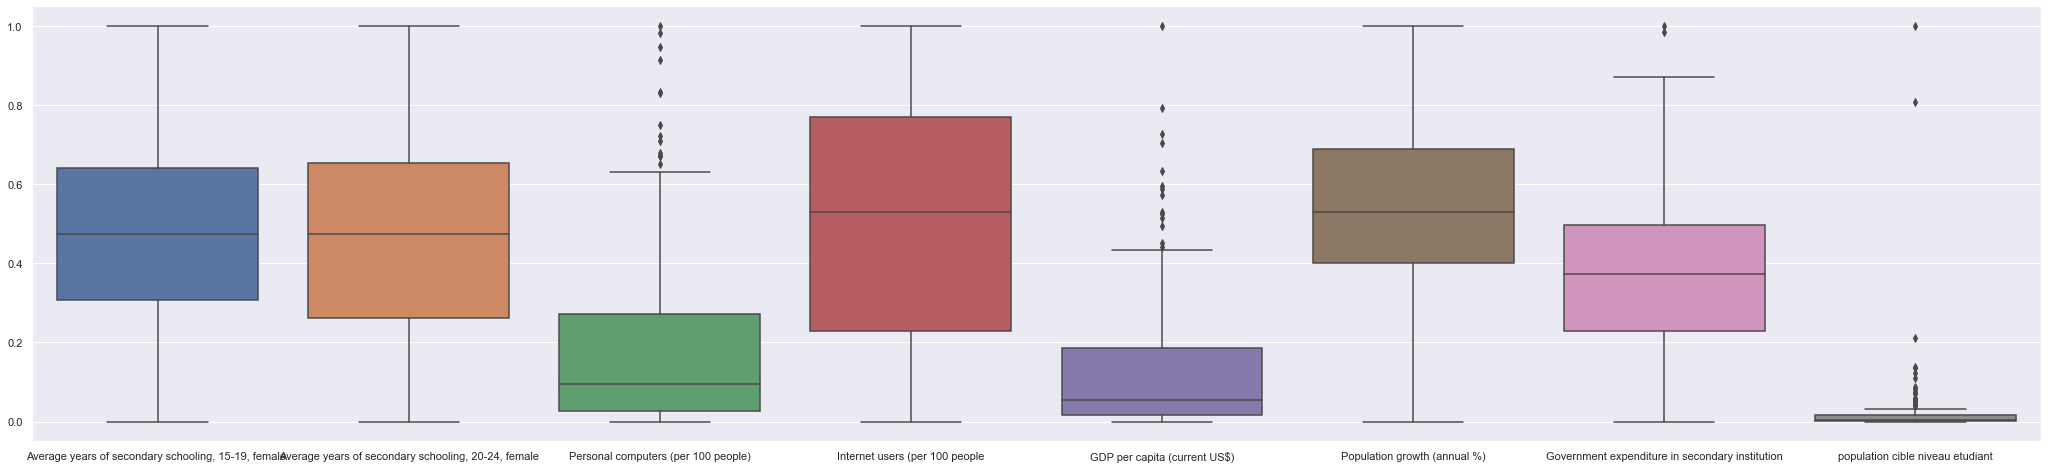

In [144]:
sns.set(rc={'figure.figsize': (36, 8)})
 
sns.boxplot(data=df_norm_bar.select_dtypes(include='number'))

>Ces boîtes à moustaches montrent une distribution assez homogène autour de la médiane pour des indicateurs comme "average years of secondary schooling" "population growth annual %", "internet users per 100 people" ou encore "Government expenditure in secondary institution"

In [145]:
df_norm_bar=df_norm.transpose()
df_norm_bar=df_norm_bar.rename_axis('Indicators')
df_norm_bar

countries,Afghanistan,Albania,Algeria,Argentina,Armenia,Australia,Austria,Bahrain,Bangladesh,Barbados,...,Ukraine,United Arab Emirates,United Kingdom,United States,Uruguay,"Venezuela, RB",Vietnam,"Yemen, Rep.",Zambia,Zimbabwe
Indicators,,,,,,,,,,,,,,,,,,,,,
"Average years of secondary schooling, 15-19, female",0.243328,0.806907,0.411303,0.450549,0.952904,0.602826,0.307692,0.456829,0.664050,0.536892,...,0.758242,0.591837,0.775510,0.660911,0.331240,0.477237,0.257457,0.238619,0.326531,0.171115
"Average years of secondary schooling, 20-24, female",0.065189,0.349413,0.367666,0.389831,0.807040,0.625815,0.801825,0.471969,0.568449,0.534550,...,0.649283,0.543677,0.761408,0.711864,0.391134,0.441982,0.470665,0.203390,0.113429,0.200782
Personal computers (per 100 people),0.003827,0.047544,0.010488,0.093958,0.102225,NaN,0.630474,0.538792,0.024897,0.151842,...,0.046838,0.298413,0.833588,0.830937,0.140522,0.096085,0.098235,0.029971,0.011648,0.077057
Internet users (per 100 people,0.069989,0.661751,0.413259,0.701939,0.615450,0.893874,0.852327,0.997453,0.151177,0.801670,...,0.514450,0.918930,0.963241,0.765882,0.662139,0.594227,0.450976,0.218370,0.228211,0.202886
GDP per capita (current US$),0.002753,0.038283,0.036207,0.121198,0.033194,0.494998,0.442634,0.222295,0.010700,0.155612,...,0.018946,0.372295,0.399409,0.571881,0.148920,0.153625,0.019231,0.007026,0.009810,0.007412
Population growth (annual %),0.791963,0.270628,0.633918,0.480078,0.349163,0.557906,0.540329,0.997572,0.497539,0.349970,...,0.239246,0.528938,0.442163,0.426657,0.366174,0.540887,0.495916,0.748474,0.849357,0.727352
Government expenditure in secondary institution,NaN,0.129169,NaN,0.518270,0.275569,0.394142,0.558460,0.228582,0.147154,0.360695,...,0.466259,0.061845,0.508563,0.434415,0.329308,0.271736,0.710673,NaN,0.000000,0.072825
population cible niveau etudiant,0.007923,0.002397,0.015466,0.025184,0.001959,0.024040,0.006218,0.000869,0.109713,0.000000,...,0.020696,0.008091,0.073853,0.212386,0.001332,0.026321,0.038132,0.007303,0.004282,0.000886


In [146]:
df_norm_bar=df_norm_bar.reset_index().rename_axis(index=None, columns=None)
df_norm_bar

,Indicators,Afghanistan,Albania,Algeria,Argentina,Armenia,Australia,Austria,Bahrain,Bangladesh,...,Ukraine,United Arab Emirates,United Kingdom,United States,Uruguay,"Venezuela, RB",Vietnam,"Yemen, Rep.",Zambia,Zimbabwe
0,"Average years of secondary schooling, 15-19, f...",0.243328,0.806907,0.411303,0.450549,0.952904,0.602826,0.307692,0.456829,0.664050,...,0.758242,0.591837,0.775510,0.660911,0.331240,0.477237,0.257457,0.238619,0.326531,0.171115
1,"Average years of secondary schooling, 20-24, f...",0.065189,0.349413,0.367666,0.389831,0.807040,0.625815,0.801825,0.471969,0.568449,...,0.649283,0.543677,0.761408,0.711864,0.391134,0.441982,0.470665,0.203390,0.113429,0.200782
2,Personal computers (per 100 people),0.003827,0.047544,0.010488,0.093958,0.102225,NaN,0.630474,0.538792,0.024897,...,0.046838,0.298413,0.833588,0.830937,0.140522,0.096085,0.098235,0.029971,0.011648,0.077057
3,Internet users (per 100 people,0.069989,0.661751,0.413259,0.701939,0.615450,0.893874,0.852327,0.997453,0.151177,...,0.514450,0.918930,0.963241,0.765882,0.662139,0.594227,0.450976,0.218370,0.228211,0.202886
4,GDP per capita (current US$),0.002753,0.038283,0.036207,0.121198,0.033194,0.494998,0.442634,0.222295,0.010700,...,0.018946,0.372295,0.399409,0.571881,0.148920,0.153625,0.019231,0.007026,0.009810,0.007412
5,Population growth (annual %),0.791963,0.270628,0.633918,0.480078,0.349163,0.557906,0.540329,0.997572,0.497539,...,0.239246,0.528938,0.442163,0.426657,0.366174,0.540887,0.495916,0.748474,0.849357,0.727352
6,Government expenditure in secondary institution,NaN,0.129169,NaN,0.518270,0.275569,0.394142,0.558460,0.228582,0.147154,...,0.466259,0.061845,0.508563,0.434415,0.329308,0.271736,0.710673,NaN,0.000000,0.072825
7,population cible niveau etudiant,0.007923,0.002397,0.015466,0.025184,0.001959,0.024040,0.006218,0.000869,0.109713,...,0.020696,0.008091,0.073853,0.212386,0.001332,0.026321,0.038132,0.007303,0.004282,0.000886


In [147]:
df_norm

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
countries,,,,,,,,
Afghanistan,0.243328,0.065189,0.003827,0.069989,0.002753,0.791963,NaN,0.007923
Albania,0.806907,0.349413,0.047544,0.661751,0.038283,0.270628,0.129169,0.002397
Algeria,0.411303,0.367666,0.010488,0.413259,0.036207,0.633918,NaN,0.015466
Argentina,0.450549,0.389831,0.093958,0.701939,0.121198,0.480078,0.518270,0.025184
Armenia,0.952904,0.807040,0.102225,0.615450,0.033194,0.349163,0.275569,0.001959
...,...,...,...,...,...,...,...,...
"Venezuela, RB",0.477237,0.441982,0.096085,0.594227,0.153625,0.540887,0.271736,0.026321
Vietnam,0.257457,0.470665,0.098235,0.450976,0.019231,0.495916,0.710673,0.038132
"Yemen, Rep.",0.238619,0.203390,0.029971,0.218370,0.007026,0.748474,NaN,0.007303


In [148]:
df_norm.columns

Index(['Average years of secondary schooling, 15-19, female ',
       'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population growth (annual %)',
       'Government expenditure in secondary institution',
       'population cible niveau etudiant'],
      dtype='object')

In [149]:
import pandas as pd
import numpy as np


countries = list(df_norm.index) 

feature_names_weights = {
   
    'Average years of secondary schooling, 15-19, female ' :3.0,
    'Average years of secondary schooling, 20-24, female' :3.0,
    'Personal computers (per 100 people)'  :10.0,
    'Internet users (per 100 people'  :10.0,
    'GDP per capita (current US$)'  :5.0,
    'population cible niveau etudiant' :7.0,
    'Population growth (annual %)':1.0,
    'Government expenditure in secondary institution' :6.0,
}
feature_names = list(feature_names_weights.keys())

df = pd.DataFrame(data=df_norm, index=countries, columns=feature_names)
data_etude_copy = df

data_sorted_by_feature = {}
country_scores = (pd.DataFrame(data=np.zeros(len(countries)),index=countries))[0]

for feature in feature_names:
    #ajoute à chaque pays son score en le multipliant par le coefficient de chaque indicateur retenu
    for country in countries:
        country_scores[country] += data_etude_copy[feature][country]*(feature_names_weights[feature])
    #classe les pays en fonction des valeurs de chaque colonne
    data_sorted_by_feature[feature] = data_etude_copy.sort_values(by=[feature], ascending=False).head(10)
    data_sorted_by_feature[feature].drop(data_sorted_by_feature[feature].loc[:,data_sorted_by_feature[feature].columns!=feature], inplace=True, axis = 1)

#region classées en fonction du score
ranked_countries = country_scores.sort_values(ascending=False).head(10)

##On rapatrie les résultats dans un nouveau dataframe :
#crée un dataframe vide
empty_data=np.empty((10,8),str)
outputDF = pd.DataFrame(data=empty_data,columns=((feature_names)))
#ajoute le résultat pour chaque pays de chaque colonne
for feature in feature_names:
    for index in range(10):
        country = list(data_sorted_by_feature[feature].index)[index]
        outputDF[feature][index] = f'{country}: {data_sorted_by_feature[feature][feature][country]}'
#ajoute la colonne avec le score global avec le coefficient

for index in range(10):
    country = list(ranked_countries.index)[index]
   

#nouveau dataframe avec le nom des pays
outputDF

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution
0,"Hong Kong SAR, China: 1.0",Germany: 1.0,Switzerland: 1.0,Iceland: 1.0,Luxembourg: 1.0,China: 1.0,Niger: 1.0,Cuba: 1.0
1,Armenia: 0.9529042386185244,Slovak Republic: 0.9543676662320729,Canada: 0.9820698976648105,Bahrain: 0.9974529333777291,Switzerland: 0.7937665809705543,India: 0.808943553172005,Bahrain: 0.9975718383387314,Kyrgyz Republic: 0.985590451996714
2,Mauritius: 0.9450549450549449,Slovenia: 0.951760104302477,Netherlands: 0.9460957700764433,Luxembourg: 0.9920831283854522,"Macao SAR, China: 0.7269230590098289",United States: 0.21238553224850754,Qatar: 0.9394323350245609,"Congo, Rep.: 0.8723685289206697"
3,Kazakhstan: 0.9277864992150706,Lithuania: 0.9400260756192959,Sweden: 0.9151444564551859,Norway: 0.9900062344322834,Norway: 0.7042362339440509,Indonesia: 0.1376552870956027,Uganda: 0.902067087211557,Botswana: 0.8315385802610714
4,"Korea, Rep.: 0.9183673469387754",Serbia: 0.9322033898305084,United Kingdom: 0.8335875770906536,Denmark: 0.9865000973052677,Ireland: 0.6339399225851798,Japan: 0.13662817667578112,"Congo, Dem. Rep.: 0.899809260063612",Mauritius: 0.798358201324294
5,Malaysia: 0.9136577708006279,Latvia: 0.910039113428944,United States: 0.8309367462414692,United Kingdom: 0.9632405022196501,Iceland: 0.5952014675987392,Brazil: 0.12152156863592359,Jordan: 0.882850333799742,Tunisia: 0.7798283755162558
6,Tajikistan: 0.8948194662480377,Romania: 0.8513689700130378,Singapore: 0.7492513410793976,Qatar: 0.9580974377441827,Qatar: 0.5886941325748357,Bangladesh: 0.10971283235886763,Burundi: 0.8736056174031094,Ghana: 0.7666870631135418
7,Slovak Republic: 0.8869701726844583,Italy: 0.8513689700130378,"Hong Kong SAR, China: 0.7215074367150933","Korea, Rep.: 0.9413893253963711",United States: 0.5718806597506244,Pakistan: 0.08624705769807677,Tanzania: 0.8657593564679007,Malta: 0.759594137928282
8,Sri Lanka: 0.8775510204081632,"Hong Kong SAR, China: 0.8305084745762711",Luxembourg: 0.7091902511065666,Japan: 0.9337859165883867,Denmark: 0.5311132462368818,Russian Federation: 0.08178735963099541,"Gambia, The: 0.854986277804926",Cyprus: 0.7169250800456572
9,Latvia: 0.8759811616954474,Kyrgyz Republic: 0.8279009126466752,Saudi Arabia: 0.6782474049969378,Sweden: 0.9285527708466664,Singapore: 0.5252579839715885,Mexico: 0.07426498702267795,Zambia: 0.8493567739943642,Vietnam: 0.7106729022324787


In [150]:
outputDF['SCORE'] = ""

In [151]:
for index in range(10):
    #country sont les noms de categories appartennat au ranking des catégories
    country = list(ranked_countries.index)[index]
     #le résultat de l'index de la colonne overall est le résultat de ranked country
    outputDF['SCORE'][index] = f'{country}: {ranked_countries[country]}'

#Print DataFrame
outputDF

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution,SCORE
0,"Hong Kong SAR, China: 1.0",Germany: 1.0,Switzerland: 1.0,Iceland: 1.0,Luxembourg: 1.0,China: 1.0,Niger: 1.0,Cuba: 1.0,Switzerland: 30.158763167678927
1,Armenia: 0.9529042386185244,Slovak Republic: 0.9543676662320729,Canada: 0.9820698976648105,Bahrain: 0.9974529333777291,Switzerland: 0.7937665809705543,India: 0.808943553172005,Bahrain: 0.9975718383387314,Kyrgyz Republic: 0.985590451996714,United Kingdom: 28.586593225433354
2,Mauritius: 0.9450549450549449,Slovenia: 0.951760104302477,Netherlands: 0.9460957700764433,Luxembourg: 0.9920831283854522,"Macao SAR, China: 0.7269230590098289",United States: 0.21238553224850754,Qatar: 0.9394323350245609,"Congo, Rep.: 0.8723685289206697",Sweden: 28.004038439756727
3,Kazakhstan: 0.9277864992150706,Lithuania: 0.9400260756192959,Sweden: 0.9151444564551859,Norway: 0.9900062344322834,Norway: 0.7042362339440509,Indonesia: 0.1376552870956027,Uganda: 0.902067087211557,Botswana: 0.8315385802610714,Netherlands: 27.7621576071886
4,"Korea, Rep.: 0.9183673469387754",Serbia: 0.9322033898305084,United Kingdom: 0.8335875770906536,Denmark: 0.9865000973052677,Ireland: 0.6339399225851798,Japan: 0.13662817667578112,"Congo, Dem. Rep.: 0.899809260063612",Mauritius: 0.798358201324294,Luxembourg: 27.700621778685317
5,Malaysia: 0.9136577708006279,Latvia: 0.910039113428944,United States: 0.8309367462414692,United Kingdom: 0.9632405022196501,Iceland: 0.5952014675987392,Brazil: 0.12152156863592359,Jordan: 0.882850333799742,Tunisia: 0.7798283755162558,Canada: 27.586869011574016
6,Tajikistan: 0.8948194662480377,Romania: 0.8513689700130378,Singapore: 0.7492513410793976,Qatar: 0.9580974377441827,Qatar: 0.5886941325748357,Bangladesh: 0.10971283235886763,Burundi: 0.8736056174031094,Ghana: 0.7666870631135418,United States: 27.46576391250104
7,Slovak Republic: 0.8869701726844583,Italy: 0.8513689700130378,"Hong Kong SAR, China: 0.7215074367150933","Korea, Rep.: 0.9413893253963711",United States: 0.5718806597506244,Pakistan: 0.08624705769807677,Tanzania: 0.8657593564679007,Malta: 0.759594137928282,Norway: 26.644229266266127
8,Sri Lanka: 0.8775510204081632,"Hong Kong SAR, China: 0.8305084745762711",Luxembourg: 0.7091902511065666,Japan: 0.9337859165883867,Denmark: 0.5311132462368818,Russian Federation: 0.08178735963099541,"Gambia, The: 0.854986277804926",Cyprus: 0.7169250800456572,Germany: 26.62070732864427
9,Latvia: 0.8759811616954474,Kyrgyz Republic: 0.8279009126466752,Saudi Arabia: 0.6782474049969378,Sweden: 0.9285527708466664,Singapore: 0.5252579839715885,Mexico: 0.07426498702267795,Zambia: 0.8493567739943642,Vietnam: 0.7106729022324787,Iceland: 26.386796961232566


In [152]:
outputDF=outputDF.rename_axis('ranking')
index = ["TOP1","TOP2","TOP3","TOP4","TOP5","TOP6","TOP7","TOP8","TOP9","TOP10",]
outputDF.index = index
outputDF

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution,SCORE
TOP1,"Hong Kong SAR, China: 1.0",Germany: 1.0,Switzerland: 1.0,Iceland: 1.0,Luxembourg: 1.0,China: 1.0,Niger: 1.0,Cuba: 1.0,Switzerland: 30.158763167678927
TOP2,Armenia: 0.9529042386185244,Slovak Republic: 0.9543676662320729,Canada: 0.9820698976648105,Bahrain: 0.9974529333777291,Switzerland: 0.7937665809705543,India: 0.808943553172005,Bahrain: 0.9975718383387314,Kyrgyz Republic: 0.985590451996714,United Kingdom: 28.586593225433354
TOP3,Mauritius: 0.9450549450549449,Slovenia: 0.951760104302477,Netherlands: 0.9460957700764433,Luxembourg: 0.9920831283854522,"Macao SAR, China: 0.7269230590098289",United States: 0.21238553224850754,Qatar: 0.9394323350245609,"Congo, Rep.: 0.8723685289206697",Sweden: 28.004038439756727
TOP4,Kazakhstan: 0.9277864992150706,Lithuania: 0.9400260756192959,Sweden: 0.9151444564551859,Norway: 0.9900062344322834,Norway: 0.7042362339440509,Indonesia: 0.1376552870956027,Uganda: 0.902067087211557,Botswana: 0.8315385802610714,Netherlands: 27.7621576071886
TOP5,"Korea, Rep.: 0.9183673469387754",Serbia: 0.9322033898305084,United Kingdom: 0.8335875770906536,Denmark: 0.9865000973052677,Ireland: 0.6339399225851798,Japan: 0.13662817667578112,"Congo, Dem. Rep.: 0.899809260063612",Mauritius: 0.798358201324294,Luxembourg: 27.700621778685317
TOP6,Malaysia: 0.9136577708006279,Latvia: 0.910039113428944,United States: 0.8309367462414692,United Kingdom: 0.9632405022196501,Iceland: 0.5952014675987392,Brazil: 0.12152156863592359,Jordan: 0.882850333799742,Tunisia: 0.7798283755162558,Canada: 27.586869011574016
TOP7,Tajikistan: 0.8948194662480377,Romania: 0.8513689700130378,Singapore: 0.7492513410793976,Qatar: 0.9580974377441827,Qatar: 0.5886941325748357,Bangladesh: 0.10971283235886763,Burundi: 0.8736056174031094,Ghana: 0.7666870631135418,United States: 27.46576391250104
TOP8,Slovak Republic: 0.8869701726844583,Italy: 0.8513689700130378,"Hong Kong SAR, China: 0.7215074367150933","Korea, Rep.: 0.9413893253963711",United States: 0.5718806597506244,Pakistan: 0.08624705769807677,Tanzania: 0.8657593564679007,Malta: 0.759594137928282,Norway: 26.644229266266127
TOP9,Sri Lanka: 0.8775510204081632,"Hong Kong SAR, China: 0.8305084745762711",Luxembourg: 0.7091902511065666,Japan: 0.9337859165883867,Denmark: 0.5311132462368818,Russian Federation: 0.08178735963099541,"Gambia, The: 0.854986277804926",Cyprus: 0.7169250800456572,Germany: 26.62070732864427
TOP10,Latvia: 0.8759811616954474,Kyrgyz Republic: 0.8279009126466752,Saudi Arabia: 0.6782474049969378,Sweden: 0.9285527708466664,Singapore: 0.5252579839715885,Mexico: 0.07426498702267795,Zambia: 0.8493567739943642,Vietnam: 0.7106729022324787,Iceland: 26.386796961232566


In [153]:
df=pd.DataFrame(data=outputDF['SCORE'])
df

,SCORE
TOP1,Switzerland: 30.158763167678927
TOP2,United Kingdom: 28.586593225433354
TOP3,Sweden: 28.004038439756727
TOP4,Netherlands: 27.7621576071886
TOP5,Luxembourg: 27.700621778685317
TOP6,Canada: 27.586869011574016
TOP7,United States: 27.46576391250104
TOP8,Norway: 26.644229266266127
TOP9,Germany: 26.62070732864427
TOP10,Iceland: 26.386796961232566


In [154]:
ranking = df

# 9.prédiction / évolution

>On va accorder un coefficient beaucoup plus important à la croissance de la population afin de faire une prédiction

In [155]:
import pandas as pd
import numpy as np


countries = list(df_norm.index) 

feature_names_weights = {
    'Average years of secondary schooling, 15-19, female ' :3.0,
    'Average years of secondary schooling, 20-24, female' :3.0,
    'Personal computers (per 100 people)'  :10.0,
    'Internet users (per 100 people'  :10.0,
    'GDP per capita (current US$)'  :5.0,
    'population cible niveau etudiant' :7.0,
    'Population growth (annual %)':10.0,
    'Government expenditure in secondary institution' :6.0,
}
feature_names = list(feature_names_weights.keys())

df = pd.DataFrame(data=df_norm, index=countries, columns=feature_names)
data_etude_copy = df

data_sorted_by_feature = {}
country_scores = (pd.DataFrame(data=np.zeros(len(countries)),index=countries))[0]

for feature in feature_names:
     #ajoute à chaque pays son score en le multipliant par le coefficient de chaque indicateur retenu
    for country in countries:
        country_scores[country] += data_etude_copy[feature][country]*(feature_names_weights[feature])
     #classe les pays en fonction des valeurs de chaque colonne
    data_sorted_by_feature[feature] = data_etude_copy.sort_values(by=[feature], ascending=False).head(10)
    data_sorted_by_feature[feature].drop(data_sorted_by_feature[feature].loc[:,data_sorted_by_feature[feature].columns!=feature], inplace=True, axis = 1)

#pays classées en fonction du score
ranked_countries = country_scores.sort_values(ascending=False).head(10)

##On rapatrie les résultats dans un nouveau dataframe :
#crée un dataframe vide
empty_data=np.empty((10,8),str)
outputDF = pd.DataFrame(data=empty_data,columns=((feature_names)))
#ajoute le résultat pour chaque pays de chaque colonne
for feature in feature_names:
    for index in range(10):
        country = list(data_sorted_by_feature[feature].index)[index]
        outputDF[feature][index] = f'{country}: {data_sorted_by_feature[feature][feature][country]}'
#ajoute la colonne avec le score global avec le coefficient
for index in range(10):
    country = list(ranked_countries.index)[index]
   

#nouveau dataframe avec le nom des pays
outputDF

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution
0,"Hong Kong SAR, China: 1.0",Germany: 1.0,Switzerland: 1.0,Iceland: 1.0,Luxembourg: 1.0,China: 1.0,Niger: 1.0,Cuba: 1.0
1,Armenia: 0.9529042386185244,Slovak Republic: 0.9543676662320729,Canada: 0.9820698976648105,Bahrain: 0.9974529333777291,Switzerland: 0.7937665809705543,India: 0.808943553172005,Bahrain: 0.9975718383387314,Kyrgyz Republic: 0.985590451996714
2,Mauritius: 0.9450549450549449,Slovenia: 0.951760104302477,Netherlands: 0.9460957700764433,Luxembourg: 0.9920831283854522,"Macao SAR, China: 0.7269230590098289",United States: 0.21238553224850754,Qatar: 0.9394323350245609,"Congo, Rep.: 0.8723685289206697"
3,Kazakhstan: 0.9277864992150706,Lithuania: 0.9400260756192959,Sweden: 0.9151444564551859,Norway: 0.9900062344322834,Norway: 0.7042362339440509,Indonesia: 0.1376552870956027,Uganda: 0.902067087211557,Botswana: 0.8315385802610714
4,"Korea, Rep.: 0.9183673469387754",Serbia: 0.9322033898305084,United Kingdom: 0.8335875770906536,Denmark: 0.9865000973052677,Ireland: 0.6339399225851798,Japan: 0.13662817667578112,"Congo, Dem. Rep.: 0.899809260063612",Mauritius: 0.798358201324294
5,Malaysia: 0.9136577708006279,Latvia: 0.910039113428944,United States: 0.8309367462414692,United Kingdom: 0.9632405022196501,Iceland: 0.5952014675987392,Brazil: 0.12152156863592359,Jordan: 0.882850333799742,Tunisia: 0.7798283755162558
6,Tajikistan: 0.8948194662480377,Romania: 0.8513689700130378,Singapore: 0.7492513410793976,Qatar: 0.9580974377441827,Qatar: 0.5886941325748357,Bangladesh: 0.10971283235886763,Burundi: 0.8736056174031094,Ghana: 0.7666870631135418
7,Slovak Republic: 0.8869701726844583,Italy: 0.8513689700130378,"Hong Kong SAR, China: 0.7215074367150933","Korea, Rep.: 0.9413893253963711",United States: 0.5718806597506244,Pakistan: 0.08624705769807677,Tanzania: 0.8657593564679007,Malta: 0.759594137928282
8,Sri Lanka: 0.8775510204081632,"Hong Kong SAR, China: 0.8305084745762711",Luxembourg: 0.7091902511065666,Japan: 0.9337859165883867,Denmark: 0.5311132462368818,Russian Federation: 0.08178735963099541,"Gambia, The: 0.854986277804926",Cyprus: 0.7169250800456572
9,Latvia: 0.8759811616954474,Kyrgyz Republic: 0.8279009126466752,Saudi Arabia: 0.6782474049969378,Sweden: 0.9285527708466664,Singapore: 0.5252579839715885,Mexico: 0.07426498702267795,Zambia: 0.8493567739943642,Vietnam: 0.7106729022324787


In [156]:
outputDF['SCORE PREDICTION'] = ""

In [157]:
for index in range(10):
    #country sont les noms de categories appartennat au ranking des catégories
    country = list(ranked_countries.index)[index]
     #le résultat de l'index de la colonne overall est le résultat de ranked country
    outputDF['SCORE PREDICTION'][index] = f'{country} : {ranked_countries[country]}'

#Print DataFrame
outputDF

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution,SCORE PREDICTION
0,"Hong Kong SAR, China: 1.0",Germany: 1.0,Switzerland: 1.0,Iceland: 1.0,Luxembourg: 1.0,China: 1.0,Niger: 1.0,Cuba: 1.0,Switzerland : 34.63176650253482
1,Armenia: 0.9529042386185244,Slovak Republic: 0.9543676662320729,Canada: 0.9820698976648105,Bahrain: 0.9974529333777291,Switzerland: 0.7937665809705543,India: 0.808943553172005,Bahrain: 0.9975718383387314,Kyrgyz Republic: 0.985590451996714,Luxembourg : 34.219956519395886
2,Mauritius: 0.9450549450549449,Slovenia: 0.951760104302477,Netherlands: 0.9460957700764433,Luxembourg: 0.9920831283854522,"Macao SAR, China: 0.7269230590098289",United States: 0.21238553224850754,Qatar: 0.9394323350245609,"Congo, Rep.: 0.8723685289206697",United Kingdom : 32.56606300956335
3,Kazakhstan: 0.9277864992150706,Lithuania: 0.9400260756192959,Sweden: 0.9151444564551859,Norway: 0.9900062344322834,Norway: 0.7042362339440509,Indonesia: 0.1376552870956027,Uganda: 0.902067087211557,Botswana: 0.8315385802610714,Sweden : 32.440568214192304
4,"Korea, Rep.: 0.9183673469387754",Serbia: 0.9322033898305084,United Kingdom: 0.8335875770906536,Denmark: 0.9865000973052677,Ireland: 0.6339399225851798,Japan: 0.13662817667578112,"Congo, Dem. Rep.: 0.899809260063612",Mauritius: 0.798358201324294,Canada : 32.28495020537827
5,Malaysia: 0.9136577708006279,Latvia: 0.910039113428944,United States: 0.8309367462414692,United Kingdom: 0.9632405022196501,Iceland: 0.5952014675987392,Brazil: 0.12152156863592359,Jordan: 0.882850333799742,Tunisia: 0.7798283755162558,United States : 31.305676961786318
6,Tajikistan: 0.8948194662480377,Romania: 0.8513689700130378,Singapore: 0.7492513410793976,Qatar: 0.9580974377441827,Qatar: 0.5886941325748357,Bangladesh: 0.10971283235886763,Burundi: 0.8736056174031094,Ghana: 0.7666870631135418,Germany : 31.28581103265125
7,Slovak Republic: 0.8869701726844583,Italy: 0.8513689700130378,"Hong Kong SAR, China: 0.7215074367150933","Korea, Rep.: 0.9413893253963711",United States: 0.5718806597506244,Pakistan: 0.08624705769807677,Tanzania: 0.8657593564679007,Malta: 0.759594137928282,Netherlands : 31.222371863356894
8,Sri Lanka: 0.8775510204081632,"Hong Kong SAR, China: 0.8305084745762711",Luxembourg: 0.7091902511065666,Japan: 0.9337859165883867,Denmark: 0.5311132462368818,Russian Federation: 0.08178735963099541,"Gambia, The: 0.854986277804926",Cyprus: 0.7169250800456572,Iceland : 30.7879441508647
9,Latvia: 0.8759811616954474,Kyrgyz Republic: 0.8279009126466752,Saudi Arabia: 0.6782474049969378,Sweden: 0.9285527708466664,Singapore: 0.5252579839715885,Mexico: 0.07426498702267795,Zambia: 0.8493567739943642,Vietnam: 0.7106729022324787,Norway : 30.74399991400934


In [158]:
outputDF=outputDF.rename_axis('ranking')
index = ["TOP1","TOP2","TOP3","TOP4","TOP5","TOP6","TOP7","TOP8","TOP9","TOP10",]
outputDF.index = index
outputDF

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution,SCORE PREDICTION
TOP1,"Hong Kong SAR, China: 1.0",Germany: 1.0,Switzerland: 1.0,Iceland: 1.0,Luxembourg: 1.0,China: 1.0,Niger: 1.0,Cuba: 1.0,Switzerland : 34.63176650253482
TOP2,Armenia: 0.9529042386185244,Slovak Republic: 0.9543676662320729,Canada: 0.9820698976648105,Bahrain: 0.9974529333777291,Switzerland: 0.7937665809705543,India: 0.808943553172005,Bahrain: 0.9975718383387314,Kyrgyz Republic: 0.985590451996714,Luxembourg : 34.219956519395886
TOP3,Mauritius: 0.9450549450549449,Slovenia: 0.951760104302477,Netherlands: 0.9460957700764433,Luxembourg: 0.9920831283854522,"Macao SAR, China: 0.7269230590098289",United States: 0.21238553224850754,Qatar: 0.9394323350245609,"Congo, Rep.: 0.8723685289206697",United Kingdom : 32.56606300956335
TOP4,Kazakhstan: 0.9277864992150706,Lithuania: 0.9400260756192959,Sweden: 0.9151444564551859,Norway: 0.9900062344322834,Norway: 0.7042362339440509,Indonesia: 0.1376552870956027,Uganda: 0.902067087211557,Botswana: 0.8315385802610714,Sweden : 32.440568214192304
TOP5,"Korea, Rep.: 0.9183673469387754",Serbia: 0.9322033898305084,United Kingdom: 0.8335875770906536,Denmark: 0.9865000973052677,Ireland: 0.6339399225851798,Japan: 0.13662817667578112,"Congo, Dem. Rep.: 0.899809260063612",Mauritius: 0.798358201324294,Canada : 32.28495020537827
TOP6,Malaysia: 0.9136577708006279,Latvia: 0.910039113428944,United States: 0.8309367462414692,United Kingdom: 0.9632405022196501,Iceland: 0.5952014675987392,Brazil: 0.12152156863592359,Jordan: 0.882850333799742,Tunisia: 0.7798283755162558,United States : 31.305676961786318
TOP7,Tajikistan: 0.8948194662480377,Romania: 0.8513689700130378,Singapore: 0.7492513410793976,Qatar: 0.9580974377441827,Qatar: 0.5886941325748357,Bangladesh: 0.10971283235886763,Burundi: 0.8736056174031094,Ghana: 0.7666870631135418,Germany : 31.28581103265125
TOP8,Slovak Republic: 0.8869701726844583,Italy: 0.8513689700130378,"Hong Kong SAR, China: 0.7215074367150933","Korea, Rep.: 0.9413893253963711",United States: 0.5718806597506244,Pakistan: 0.08624705769807677,Tanzania: 0.8657593564679007,Malta: 0.759594137928282,Netherlands : 31.222371863356894
TOP9,Sri Lanka: 0.8775510204081632,"Hong Kong SAR, China: 0.8305084745762711",Luxembourg: 0.7091902511065666,Japan: 0.9337859165883867,Denmark: 0.5311132462368818,Russian Federation: 0.08178735963099541,"Gambia, The: 0.854986277804926",Cyprus: 0.7169250800456572,Iceland : 30.7879441508647
TOP10,Latvia: 0.8759811616954474,Kyrgyz Republic: 0.8279009126466752,Saudi Arabia: 0.6782474049969378,Sweden: 0.9285527708466664,Singapore: 0.5252579839715885,Mexico: 0.07426498702267795,Zambia: 0.8493567739943642,Vietnam: 0.7106729022324787,Norway : 30.74399991400934


In [159]:
df2=pd.DataFrame(data=outputDF['SCORE PREDICTION'])
df2

,SCORE PREDICTION
TOP1,Switzerland : 34.63176650253482
TOP2,Luxembourg : 34.219956519395886
TOP3,United Kingdom : 32.56606300956335
TOP4,Sweden : 32.440568214192304
TOP5,Canada : 32.28495020537827
TOP6,United States : 31.305676961786318
TOP7,Germany : 31.28581103265125
TOP8,Netherlands : 31.222371863356894
TOP9,Iceland : 30.7879441508647
TOP10,Norway : 30.74399991400934


In [160]:
result = pd.concat([ranking, df2], axis=1)
result

,SCORE,SCORE PREDICTION
TOP1,Switzerland: 30.158763167678927,Switzerland : 34.63176650253482
TOP2,United Kingdom: 28.586593225433354,Luxembourg : 34.219956519395886
TOP3,Sweden: 28.004038439756727,United Kingdom : 32.56606300956335
TOP4,Netherlands: 27.7621576071886,Sweden : 32.440568214192304
TOP5,Luxembourg: 27.700621778685317,Canada : 32.28495020537827
TOP6,Canada: 27.586869011574016,United States : 31.305676961786318
TOP7,United States: 27.46576391250104,Germany : 31.28581103265125
TOP8,Norway: 26.644229266266127,Netherlands : 31.222371863356894
TOP9,Germany: 26.62070732864427,Iceland : 30.7879441508647
TOP10,Iceland: 26.386796961232566,Norway : 30.74399991400934


>Les pays qui apparaissent en premier dans le score global et le score avec prédictions  sont la Suisse, l'Angleterre, la Suède et le Canada.
Ce sont d'après les coefficients accordés les pays dans lesquels Mark devrait investir en premier


# 10.Etude des pays potentiels par régions

In [161]:
df_norm

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
countries,,,,,,,,
Afghanistan,0.243328,0.065189,0.003827,0.069989,0.002753,0.791963,NaN,0.007923
Albania,0.806907,0.349413,0.047544,0.661751,0.038283,0.270628,0.129169,0.002397
Algeria,0.411303,0.367666,0.010488,0.413259,0.036207,0.633918,NaN,0.015466
Argentina,0.450549,0.389831,0.093958,0.701939,0.121198,0.480078,0.518270,0.025184
Armenia,0.952904,0.807040,0.102225,0.615450,0.033194,0.349163,0.275569,0.001959
...,...,...,...,...,...,...,...,...
"Venezuela, RB",0.477237,0.441982,0.096085,0.594227,0.153625,0.540887,0.271736,0.026321
Vietnam,0.257457,0.470665,0.098235,0.450976,0.019231,0.495916,0.710673,0.038132
"Yemen, Rep.",0.238619,0.203390,0.029971,0.218370,0.007026,0.748474,NaN,0.007303


In [162]:
df_norm_region = pd.DataFrame(data=df_norm, index=None)
df_norm_region = df_norm_region.reset_index()
df_norm_region

,countries,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
0,Afghanistan,0.243328,0.065189,0.003827,0.069989,0.002753,0.791963,NaN,0.007923
1,Albania,0.806907,0.349413,0.047544,0.661751,0.038283,0.270628,0.129169,0.002397
2,Algeria,0.411303,0.367666,0.010488,0.413259,0.036207,0.633918,NaN,0.015466
3,Argentina,0.450549,0.389831,0.093958,0.701939,0.121198,0.480078,0.518270,0.025184
4,Armenia,0.952904,0.807040,0.102225,0.615450,0.033194,0.349163,0.275569,0.001959
...,...,...,...,...,...,...,...,...,...
139,"Venezuela, RB",0.477237,0.441982,0.096085,0.594227,0.153625,0.540887,0.271736,0.026321
140,Vietnam,0.257457,0.470665,0.098235,0.450976,0.019231,0.495916,0.710673,0.038132
141,"Yemen, Rep.",0.238619,0.203390,0.029971,0.218370,0.007026,0.748474,NaN,0.007303
142,Zambia,0.326531,0.113429,0.011648,0.228211,0.009810,0.849357,0.000000,0.004282


In [163]:
df_norm_region.columns = df_norm_region.columns.str.replace('countries', 'Table Name')

In [164]:
df_norm_region

,Table Name,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
0,Afghanistan,0.243328,0.065189,0.003827,0.069989,0.002753,0.791963,NaN,0.007923
1,Albania,0.806907,0.349413,0.047544,0.661751,0.038283,0.270628,0.129169,0.002397
2,Algeria,0.411303,0.367666,0.010488,0.413259,0.036207,0.633918,NaN,0.015466
3,Argentina,0.450549,0.389831,0.093958,0.701939,0.121198,0.480078,0.518270,0.025184
4,Armenia,0.952904,0.807040,0.102225,0.615450,0.033194,0.349163,0.275569,0.001959
...,...,...,...,...,...,...,...,...,...
139,"Venezuela, RB",0.477237,0.441982,0.096085,0.594227,0.153625,0.540887,0.271736,0.026321
140,Vietnam,0.257457,0.470665,0.098235,0.450976,0.019231,0.495916,0.710673,0.038132
141,"Yemen, Rep.",0.238619,0.203390,0.029971,0.218370,0.007026,0.748474,NaN,0.007303
142,Zambia,0.326531,0.113429,0.011648,0.228211,0.009810,0.849357,0.000000,0.004282


In [165]:
country = pd.read_csv('EdStatsCountry.csv', sep=",")

In [166]:
df_norm_region2 = pd.merge(df_norm_region,country[['Table Name','Region']],on='Table Name', how='left')

In [167]:
df_norm_region2

,Table Name,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant,Region
0,Afghanistan,0.243328,0.065189,0.003827,0.069989,0.002753,0.791963,NaN,0.007923,South Asia
1,Albania,0.806907,0.349413,0.047544,0.661751,0.038283,0.270628,0.129169,0.002397,Europe & Central Asia
2,Algeria,0.411303,0.367666,0.010488,0.413259,0.036207,0.633918,NaN,0.015466,Middle East & North Africa
3,Argentina,0.450549,0.389831,0.093958,0.701939,0.121198,0.480078,0.518270,0.025184,Latin America & Caribbean
4,Armenia,0.952904,0.807040,0.102225,0.615450,0.033194,0.349163,0.275569,0.001959,Europe & Central Asia
...,...,...,...,...,...,...,...,...,...,...
139,"Venezuela, RB",0.477237,0.441982,0.096085,0.594227,0.153625,0.540887,0.271736,0.026321,Latin America & Caribbean
140,Vietnam,0.257457,0.470665,0.098235,0.450976,0.019231,0.495916,0.710673,0.038132,East Asia & Pacific
141,"Yemen, Rep.",0.238619,0.203390,0.029971,0.218370,0.007026,0.748474,NaN,0.007303,Middle East & North Africa
142,Zambia,0.326531,0.113429,0.011648,0.228211,0.009810,0.849357,0.000000,0.004282,Sub-Saharan Africa


In [168]:
cols = df_norm_region2.columns.tolist()
cols = cols[-1:] + cols[:-1]
df_norm_region2 = df_norm_region2[cols] 

In [169]:
df_norm_region2

,Region,Table Name,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
0,South Asia,Afghanistan,0.243328,0.065189,0.003827,0.069989,0.002753,0.791963,NaN,0.007923
1,Europe & Central Asia,Albania,0.806907,0.349413,0.047544,0.661751,0.038283,0.270628,0.129169,0.002397
2,Middle East & North Africa,Algeria,0.411303,0.367666,0.010488,0.413259,0.036207,0.633918,NaN,0.015466
3,Latin America & Caribbean,Argentina,0.450549,0.389831,0.093958,0.701939,0.121198,0.480078,0.518270,0.025184
4,Europe & Central Asia,Armenia,0.952904,0.807040,0.102225,0.615450,0.033194,0.349163,0.275569,0.001959
...,...,...,...,...,...,...,...,...,...,...
139,Latin America & Caribbean,"Venezuela, RB",0.477237,0.441982,0.096085,0.594227,0.153625,0.540887,0.271736,0.026321
140,East Asia & Pacific,Vietnam,0.257457,0.470665,0.098235,0.450976,0.019231,0.495916,0.710673,0.038132
141,Middle East & North Africa,"Yemen, Rep.",0.238619,0.203390,0.029971,0.218370,0.007026,0.748474,NaN,0.007303
142,Sub-Saharan Africa,Zambia,0.326531,0.113429,0.011648,0.228211,0.009810,0.849357,0.000000,0.004282


In [170]:
df_norm_region2.columns = df_norm_region2.columns.str.replace('Table Name', 'countries')

In [171]:

dataset_region = df_norm_region2



In [172]:
dataset_region = dataset_region.groupby(dataset_region['Region'])
dataset_region.mean()

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),Population growth (annual %),Government expenditure in secondary institution,population cible niveau etudiant
Region,,,,,,,,
East Asia & Pacific,0.584062,0.513255,0.220465,0.555859,0.189373,0.509729,0.303688,0.072972
Europe & Central Asia,0.616680,0.688070,0.388702,0.762244,0.270755,0.375074,0.455479,0.015233
Latin America & Caribbean,0.434411,0.419661,0.095290,0.491939,0.076362,0.491638,0.374912,0.015273
Middle East & North Africa,0.503094,0.483319,0.178927,0.579789,0.153024,0.647082,0.413742,0.013759
North America,0.642857,0.691656,0.906503,0.838374,0.494701,0.474333,0.380856,0.120147
South Asia,0.487778,0.409946,0.051794,0.237595,0.025293,0.592354,0.307032,0.147477
Sub-Saharan Africa,0.223122,0.180847,0.038328,0.186694,0.015726,0.752444,0.358609,0.004764


In [173]:
df_norm_region3=df_norm_region2.copy()
df_norm_region3.drop(columns="countries", inplace= True)

In [174]:
df_norm_region3.columns

Index(['Region', 'Average years of secondary schooling, 15-19, female ',
       'Average years of secondary schooling, 20-24, female',
       'Personal computers (per 100 people)', 'Internet users (per 100 people',
       'GDP per capita (current US$)', 'Population growth (annual %)',
       'Government expenditure in secondary institution',
       'population cible niveau etudiant'],
      dtype='object')

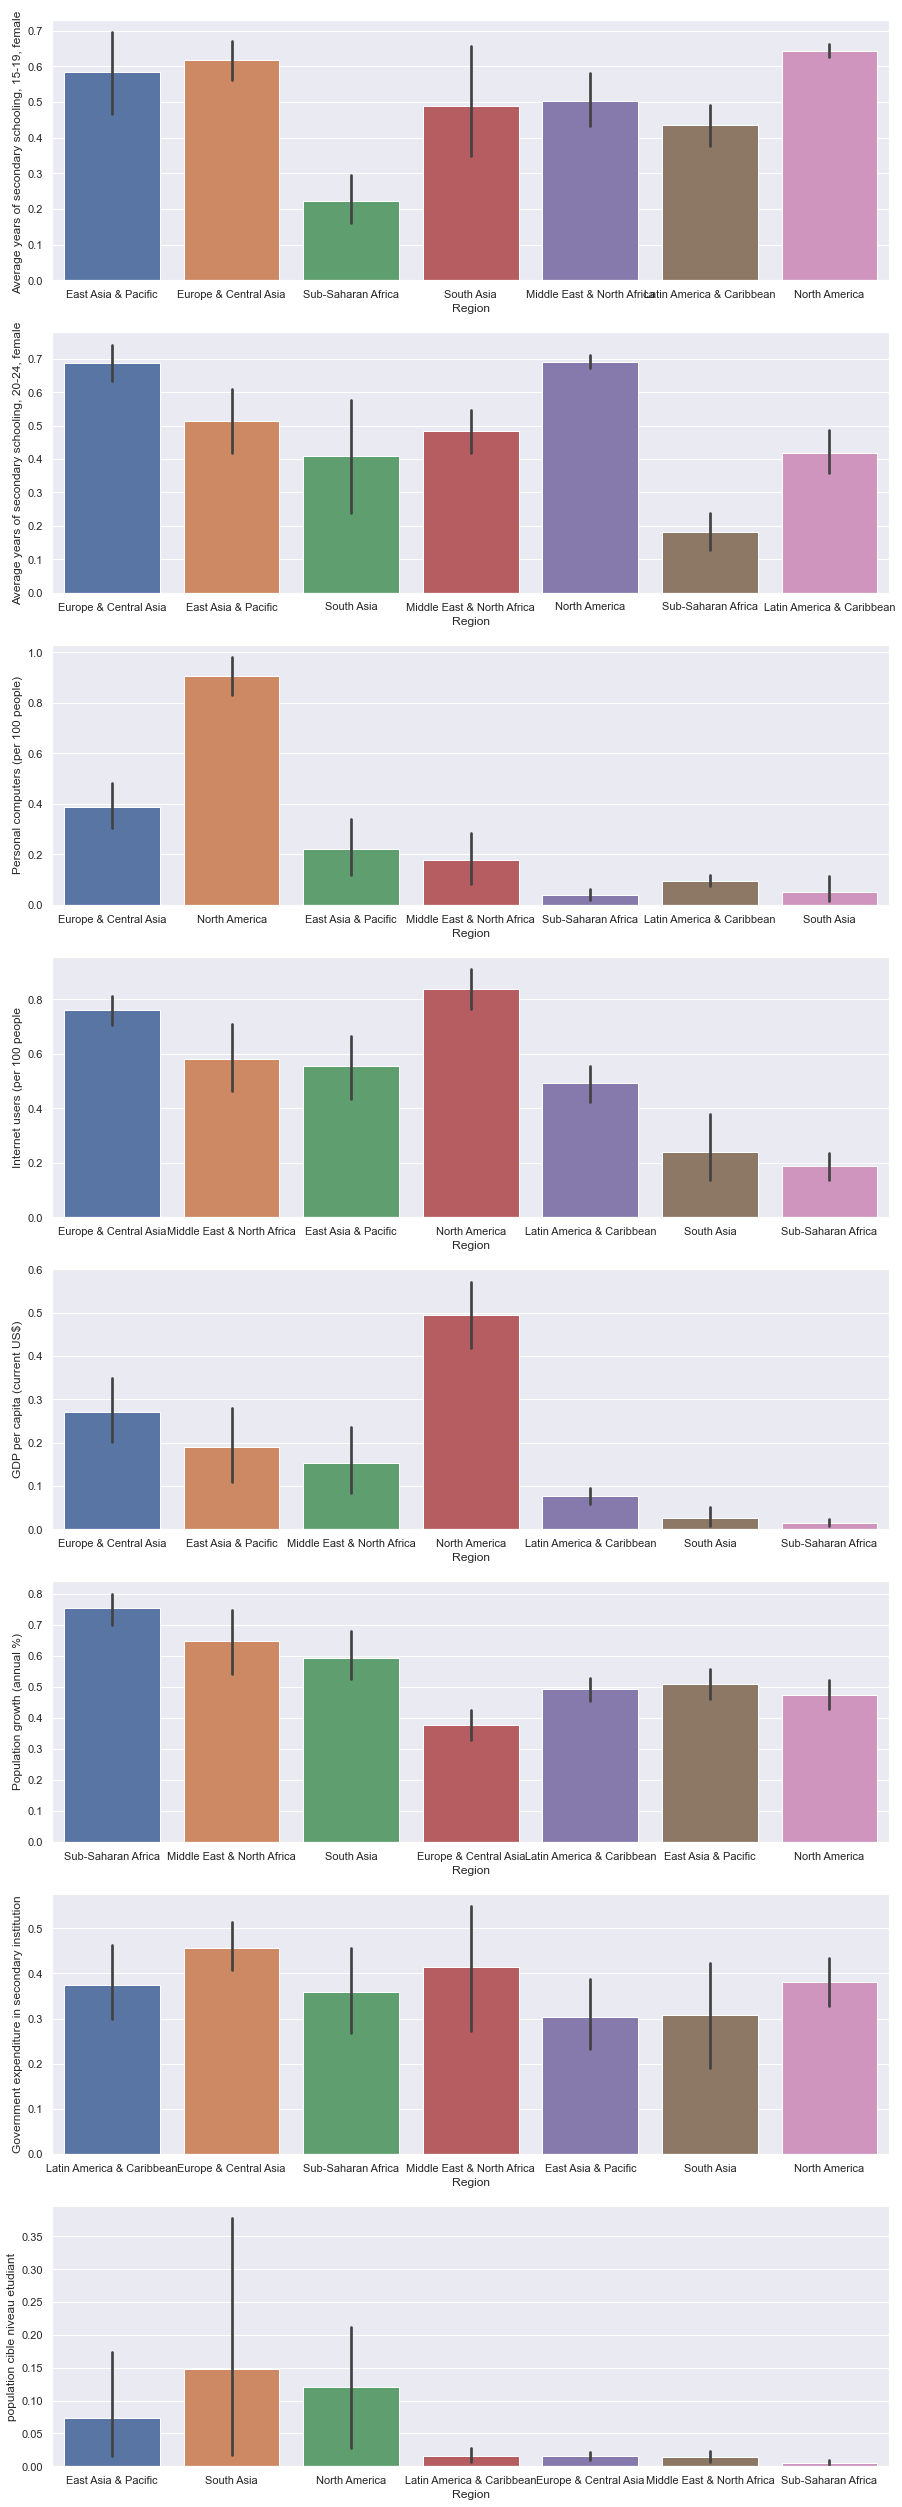

In [175]:
%matplotlib inline
f, ax = plt. subplots (nrows=8, ncols=1, figsize=(15,45))

for i, col in enumerate (df_norm_region3.drop('Region', axis = 1).columns):


    sns.barplot (x = df_norm_region3.sort_values(by = col, ascending = False)['Region'], y = df_norm_region3[col], ax=ax[i])

In [176]:
region_scoring = dataset_region.mean()

In [177]:
region_scoring.index

Index(['East Asia & Pacific', 'Europe & Central Asia',
       'Latin America & Caribbean', 'Middle East & North Africa',
       'North America', 'South Asia', 'Sub-Saharan Africa'],
      dtype='object', name='Region')

In [178]:
regions = list(region_scoring.index) 

feature_names_weights = {
    'Average years of secondary schooling, 15-19, female ' :3.0,
    'Average years of secondary schooling, 20-24, female' :3.0,
    'Personal computers (per 100 people)'  :10.0,
    'Internet users (per 100 people'  :10.0,
    'GDP per capita (current US$)'  :5.0,
    'population cible niveau etudiant' :7.0,
    'Population growth (annual %)':1.0,
    'Government expenditure in secondary institution' :6.0,
}
feature_names = list(feature_names_weights.keys())

df = pd.DataFrame(data=region_scoring, index=regions, columns=feature_names)
data_etude_copy = df

data_sorted_by_feature = {}
region_scores = (pd.DataFrame(data=np.zeros(len(regions)),index=regions))[0]

for feature in feature_names:
    #ajoute à chaque régions son score en le multipliant par le coefficient de chaque indicateur retenu
    for region in regions:
        region_scores[region] += data_etude_copy[feature][region]*(feature_names_weights[feature])
    #classe les régions en fonction des valeurs de chaque colonne
    data_sorted_by_feature[feature] = data_etude_copy.sort_values(by=[feature], ascending=False).head(10)
    data_sorted_by_feature[feature].drop(data_sorted_by_feature[feature].loc[:,data_sorted_by_feature[feature].columns!=feature], inplace=True, axis = 1)

#region classées en fonction du score
ranked_regions = region_scores.sort_values(ascending=False).head(10)

##On rapatrie les résultats dans un nouveau dataframe :
#crée un dataframe vide
empty_data=np.empty((7,8),str)
outputDF = pd.DataFrame(data=empty_data,columns=((feature_names)))

#ajoute le résultat pour chaque régions de chaque colonne
for feature in feature_names:
    for index in range(7):
        region = list(data_sorted_by_feature[feature].index)[index]
        outputDF[feature][index] = f'{region}: {data_sorted_by_feature[feature][feature][region]}'

#ajoute la colonne avec le score global avec le coefficient

for index in range(7):
    region = list(ranked_regions.index)[index]
   

#nouveau dataframe avec le nom des régions
outputDF

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution
0,North America: 0.6428571428571428,North America: 0.6916558018252933,North America: 0.9065033219531398,North America: 0.8383738839612235,North America: 0.4947013273425042,South Asia: 0.14747735499812215,Sub-Saharan Africa: 0.7524436199939445,Europe & Central Asia: 0.4554785168804001
1,Europe & Central Asia: 0.6166797488226059,Europe & Central Asia: 0.688070404172099,Europe & Central Asia: 0.38870181579891444,Europe & Central Asia: 0.7622435479327268,Europe & Central Asia: 0.270754606367841,North America: 0.12014724613632125,Middle East & North Africa: 0.6470815897271219,Middle East & North Africa: 0.4137421481060061
2,East Asia & Pacific: 0.5840621963070942,East Asia & Pacific: 0.5132551064754454,East Asia & Pacific: 0.2204649096396783,Middle East & North Africa: 0.579788543905794,East Asia & Pacific: 0.1893729597735877,East Asia & Pacific: 0.0729719790899033,South Asia: 0.5923537898732872,North America: 0.38085586594580706
3,Middle East & North Africa: 0.5030935451103519,Middle East & North Africa: 0.48331927295037963,Middle East & North Africa: 0.17892725276942234,East Asia & Pacific: 0.5558585893471607,Middle East & North Africa: 0.15302358422561008,Latin America & Caribbean: 0.01527301647923307,East Asia & Pacific: 0.5097290623082295,Latin America & Caribbean: 0.37491213675468554
4,South Asia: 0.4877775285938551,Latin America & Caribbean: 0.41966101694915253,Latin America & Caribbean: 0.09528978770885826,Latin America & Caribbean: 0.4919388751421513,Latin America & Caribbean: 0.07636213963786434,Europe & Central Asia: 0.015233005547327963,Latin America & Caribbean: 0.4916376421814558,Sub-Saharan Africa: 0.3586092575573373
5,Latin America & Caribbean: 0.4344113029827315,South Asia: 0.40994598621717265,South Asia: 0.05179368878193887,South Asia: 0.2375950681245494,South Asia: 0.02529339041982231,Middle East & North Africa: 0.013759293712364687,North America: 0.47433301350497403,South Asia: 0.30703175807757754
6,Sub-Saharan Africa: 0.22312249962019545,Sub-Saharan Africa: 0.18084703705261387,Sub-Saharan Africa: 0.03832803636164947,Sub-Saharan Africa: 0.18669351430485215,Sub-Saharan Africa: 0.01572588538730451,Sub-Saharan Africa: 0.004763772099348716,Europe & Central Asia: 0.37507402308062887,East Asia & Pacific: 0.3036880637675993


In [179]:
outputDF['SCORE'] = ""
for index in range(7):
    #country sont les noms de categories appartennat au ranking des catégories
    region = list(ranked_regions.index)[index]
     #le résultat de l'index de la colonne overall est le résultat de ranked country
    outputDF['SCORE'][index] = f'{region}: {ranked_regions[region]}'


outputDF

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution,SCORE
0,North America: 0.6428571428571428,North America: 0.6916558018252933,North America: 0.9065033219531398,North America: 0.8383738839612235,North America: 0.4947013273425042,South Asia: 0.14747735499812215,Sub-Saharan Africa: 0.7524436199939445,Europe & Central Asia: 0.4554785168804001,North America: 27.526316462037528
1,Europe & Central Asia: 0.6166797488226059,Europe & Central Asia: 0.688070404172099,Europe & Central Asia: 0.38870181579891444,Europe & Central Asia: 0.7622435479327268,Europe & Central Asia: 0.270754606367841,North America: 0.12014724613632125,Middle East & North Africa: 0.6470815897271219,Middle East & North Africa: 0.4137421481060061,Europe & Central Asia: 19.992053291334052
2,East Asia & Pacific: 0.5840621963070942,East Asia & Pacific: 0.5132551064754454,East Asia & Pacific: 0.2204649096396783,Middle East & North Africa: 0.579788543905794,East Asia & Pacific: 0.1893729597735877,East Asia & Pacific: 0.0729719790899033,South Asia: 0.5923537898732872,North America: 0.38085586594580706,East Asia & Pacific: 14.844712995627095
3,Middle East & North Africa: 0.5030935451103519,Middle East & North Africa: 0.48331927295037963,Middle East & North Africa: 0.17892725276942234,East Asia & Pacific: 0.5558585893471607,Middle East & North Africa: 0.15302358422561008,Latin America & Caribbean: 0.01527301647923307,East Asia & Pacific: 0.5097290623082295,Latin America & Caribbean: 0.37491213675468554,Middle East & North Africa: 14.537363876412119
4,South Asia: 0.4877775285938551,Latin America & Caribbean: 0.41966101694915253,Latin America & Caribbean: 0.09528978770885826,Latin America & Caribbean: 0.4919388751421513,Latin America & Caribbean: 0.07636213963786434,Europe & Central Asia: 0.015233005547327963,Latin America & Caribbean: 0.4916376421814558,Sub-Saharan Africa: 0.3586092575573373,Latin America & Caribbean: 11.66433586455927
5,Latin America & Caribbean: 0.4344113029827315,South Asia: 0.40994598621717265,South Asia: 0.05179368878193887,South Asia: 0.2375950681245494,South Asia: 0.02529339041982231,Middle East & North Africa: 0.013759293712364687,North America: 0.47433301350497403,South Asia: 0.30703175807757754,South Asia: 9.180410888922683
6,Sub-Saharan Africa: 0.22312249962019545,Sub-Saharan Africa: 0.18084703705261387,Sub-Saharan Africa: 0.03832803636164947,Sub-Saharan Africa: 0.18669351430485215,Sub-Saharan Africa: 0.01572588538730451,Sub-Saharan Africa: 0.004763772099348716,Europe & Central Asia: 0.37507402308062887,East Asia & Pacific: 0.3036880637675993,Sub-Saharan Africa: 6.4781991136533765


In [180]:
outputDF=outputDF.rename_axis('ranking')
index = ["TOP1","TOP2","TOP3","TOP4","TOP5","TOP6","TOP7"]
outputDF.index = index
outputDF

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution,SCORE
TOP1,North America: 0.6428571428571428,North America: 0.6916558018252933,North America: 0.9065033219531398,North America: 0.8383738839612235,North America: 0.4947013273425042,South Asia: 0.14747735499812215,Sub-Saharan Africa: 0.7524436199939445,Europe & Central Asia: 0.4554785168804001,North America: 27.526316462037528
TOP2,Europe & Central Asia: 0.6166797488226059,Europe & Central Asia: 0.688070404172099,Europe & Central Asia: 0.38870181579891444,Europe & Central Asia: 0.7622435479327268,Europe & Central Asia: 0.270754606367841,North America: 0.12014724613632125,Middle East & North Africa: 0.6470815897271219,Middle East & North Africa: 0.4137421481060061,Europe & Central Asia: 19.992053291334052
TOP3,East Asia & Pacific: 0.5840621963070942,East Asia & Pacific: 0.5132551064754454,East Asia & Pacific: 0.2204649096396783,Middle East & North Africa: 0.579788543905794,East Asia & Pacific: 0.1893729597735877,East Asia & Pacific: 0.0729719790899033,South Asia: 0.5923537898732872,North America: 0.38085586594580706,East Asia & Pacific: 14.844712995627095
TOP4,Middle East & North Africa: 0.5030935451103519,Middle East & North Africa: 0.48331927295037963,Middle East & North Africa: 0.17892725276942234,East Asia & Pacific: 0.5558585893471607,Middle East & North Africa: 0.15302358422561008,Latin America & Caribbean: 0.01527301647923307,East Asia & Pacific: 0.5097290623082295,Latin America & Caribbean: 0.37491213675468554,Middle East & North Africa: 14.537363876412119
TOP5,South Asia: 0.4877775285938551,Latin America & Caribbean: 0.41966101694915253,Latin America & Caribbean: 0.09528978770885826,Latin America & Caribbean: 0.4919388751421513,Latin America & Caribbean: 0.07636213963786434,Europe & Central Asia: 0.015233005547327963,Latin America & Caribbean: 0.4916376421814558,Sub-Saharan Africa: 0.3586092575573373,Latin America & Caribbean: 11.66433586455927
TOP6,Latin America & Caribbean: 0.4344113029827315,South Asia: 0.40994598621717265,South Asia: 0.05179368878193887,South Asia: 0.2375950681245494,South Asia: 0.02529339041982231,Middle East & North Africa: 0.013759293712364687,North America: 0.47433301350497403,South Asia: 0.30703175807757754,South Asia: 9.180410888922683
TOP7,Sub-Saharan Africa: 0.22312249962019545,Sub-Saharan Africa: 0.18084703705261387,Sub-Saharan Africa: 0.03832803636164947,Sub-Saharan Africa: 0.18669351430485215,Sub-Saharan Africa: 0.01572588538730451,Sub-Saharan Africa: 0.004763772099348716,Europe & Central Asia: 0.37507402308062887,East Asia & Pacific: 0.3036880637675993,Sub-Saharan Africa: 6.4781991136533765


In [181]:
score_par_region=pd.DataFrame(data=outputDF['SCORE'])
score_par_region

,SCORE
TOP1,North America: 27.526316462037528
TOP2,Europe & Central Asia: 19.992053291334052
TOP3,East Asia & Pacific: 14.844712995627095
TOP4,Middle East & North Africa: 14.537363876412119
TOP5,Latin America & Caribbean: 11.66433586455927
TOP6,South Asia: 9.180410888922683
TOP7,Sub-Saharan Africa: 6.4781991136533765


In [182]:
regions = list(region_scoring.index) 

feature_names_weights = {
    'Average years of secondary schooling, 15-19, female ' :3.0,
    'Average years of secondary schooling, 20-24, female' :3.0,
    'Personal computers (per 100 people)'  :10.0,
    'Internet users (per 100 people'  :10.0,
    'GDP per capita (current US$)'  :5.0,
    'population cible niveau etudiant' :7.0,
    'Population growth (annual %)':10.0,
    'Government expenditure in secondary institution' :6.0,
}

feature_names = list(feature_names_weights.keys())

df2 = pd.DataFrame(data=region_scoring, index=regions, columns=feature_names)
data_etude_copy = df2

data_sorted_by_feature = {}
region_scores = (pd.DataFrame(data=np.zeros(len(regions)),index=regions))[0]

for feature in feature_names:

    for region in regions:
        region_scores[region] += data_etude_copy[feature][region]*(feature_names_weights[feature])

    data_sorted_by_feature[feature] = data_etude_copy.sort_values(by=[feature], ascending=False).head(10)
    data_sorted_by_feature[feature].drop(data_sorted_by_feature[feature].loc[:,data_sorted_by_feature[feature].columns!=feature], inplace=True, axis = 1)


ranked_regions = region_scores.sort_values(ascending=False).head(10)


empty_data=np.empty((7,8),str)
outputDF2 = pd.DataFrame(data=empty_data,columns=((feature_names)))

for feature in feature_names:
    for index in range(7):
        region = list(data_sorted_by_feature[feature].index)[index]
        outputDF2[feature][index] = f'{region}: {data_sorted_by_feature[feature][feature][region]}'


for index in range(7):
    region = list(ranked_regions.index)[index]
   

#Print DataFrame
outputDF2

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution
0,North America: 0.6428571428571428,North America: 0.6916558018252933,North America: 0.9065033219531398,North America: 0.8383738839612235,North America: 0.4947013273425042,South Asia: 0.14747735499812215,Sub-Saharan Africa: 0.7524436199939445,Europe & Central Asia: 0.4554785168804001
1,Europe & Central Asia: 0.6166797488226059,Europe & Central Asia: 0.688070404172099,Europe & Central Asia: 0.38870181579891444,Europe & Central Asia: 0.7622435479327268,Europe & Central Asia: 0.270754606367841,North America: 0.12014724613632125,Middle East & North Africa: 0.6470815897271219,Middle East & North Africa: 0.4137421481060061
2,East Asia & Pacific: 0.5840621963070942,East Asia & Pacific: 0.5132551064754454,East Asia & Pacific: 0.2204649096396783,Middle East & North Africa: 0.579788543905794,East Asia & Pacific: 0.1893729597735877,East Asia & Pacific: 0.0729719790899033,South Asia: 0.5923537898732872,North America: 0.38085586594580706
3,Middle East & North Africa: 0.5030935451103519,Middle East & North Africa: 0.48331927295037963,Middle East & North Africa: 0.17892725276942234,East Asia & Pacific: 0.5558585893471607,Middle East & North Africa: 0.15302358422561008,Latin America & Caribbean: 0.01527301647923307,East Asia & Pacific: 0.5097290623082295,Latin America & Caribbean: 0.37491213675468554
4,South Asia: 0.4877775285938551,Latin America & Caribbean: 0.41966101694915253,Latin America & Caribbean: 0.09528978770885826,Latin America & Caribbean: 0.4919388751421513,Latin America & Caribbean: 0.07636213963786434,Europe & Central Asia: 0.015233005547327963,Latin America & Caribbean: 0.4916376421814558,Sub-Saharan Africa: 0.3586092575573373
5,Latin America & Caribbean: 0.4344113029827315,South Asia: 0.40994598621717265,South Asia: 0.05179368878193887,South Asia: 0.2375950681245494,South Asia: 0.02529339041982231,Middle East & North Africa: 0.013759293712364687,North America: 0.47433301350497403,South Asia: 0.30703175807757754
6,Sub-Saharan Africa: 0.22312249962019545,Sub-Saharan Africa: 0.18084703705261387,Sub-Saharan Africa: 0.03832803636164947,Sub-Saharan Africa: 0.18669351430485215,Sub-Saharan Africa: 0.01572588538730451,Sub-Saharan Africa: 0.004763772099348716,Europe & Central Asia: 0.37507402308062887,East Asia & Pacific: 0.3036880637675993


In [183]:
outputDF2['SCORE PREDICTION'] = ""
for index in range(7):
    #country sont les noms de categories appartennat au ranking des catégories
    region = list(ranked_regions.index)[index]
     #le résultat de l'index de la colonne overall est le résultat de ranked country
    outputDF2['SCORE PREDICTION'][index] = f'{region}: {ranked_regions[region]}'

outputDF2

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution,SCORE PREDICTION
0,North America: 0.6428571428571428,North America: 0.6916558018252933,North America: 0.9065033219531398,North America: 0.8383738839612235,North America: 0.4947013273425042,South Asia: 0.14747735499812215,Sub-Saharan Africa: 0.7524436199939445,Europe & Central Asia: 0.4554785168804001,North America: 31.795313583582296
1,Europe & Central Asia: 0.6166797488226059,Europe & Central Asia: 0.688070404172099,Europe & Central Asia: 0.38870181579891444,Europe & Central Asia: 0.7622435479327268,Europe & Central Asia: 0.270754606367841,North America: 0.12014724613632125,Middle East & North Africa: 0.6470815897271219,Middle East & North Africa: 0.4137421481060061,Europe & Central Asia: 23.367719499059717
2,East Asia & Pacific: 0.5840621963070942,East Asia & Pacific: 0.5132551064754454,East Asia & Pacific: 0.2204649096396783,Middle East & North Africa: 0.579788543905794,East Asia & Pacific: 0.1893729597735877,East Asia & Pacific: 0.0729719790899033,South Asia: 0.5923537898732872,North America: 0.38085586594580706,Middle East & North Africa: 20.361098183956216
3,Middle East & North Africa: 0.5030935451103519,Middle East & North Africa: 0.48331927295037963,Middle East & North Africa: 0.17892725276942234,East Asia & Pacific: 0.5558585893471607,Middle East & North Africa: 0.15302358422561008,Latin America & Caribbean: 0.01527301647923307,East Asia & Pacific: 0.5097290623082295,Latin America & Caribbean: 0.37491213675468554,East Asia & Pacific: 19.432274556401158
4,South Asia: 0.4877775285938551,Latin America & Caribbean: 0.41966101694915253,Latin America & Caribbean: 0.09528978770885826,Latin America & Caribbean: 0.4919388751421513,Latin America & Caribbean: 0.07636213963786434,Europe & Central Asia: 0.015233005547327963,Latin America & Caribbean: 0.4916376421814558,Sub-Saharan Africa: 0.3586092575573373,Latin America & Caribbean: 16.089074644192372
5,Latin America & Caribbean: 0.4344113029827315,South Asia: 0.40994598621717265,South Asia: 0.05179368878193887,South Asia: 0.2375950681245494,South Asia: 0.02529339041982231,Middle East & North Africa: 0.013759293712364687,North America: 0.47433301350497403,South Asia: 0.30703175807757754,South Asia: 14.51159499778227
6,Sub-Saharan Africa: 0.22312249962019545,Sub-Saharan Africa: 0.18084703705261387,Sub-Saharan Africa: 0.03832803636164947,Sub-Saharan Africa: 0.18669351430485215,Sub-Saharan Africa: 0.01572588538730451,Sub-Saharan Africa: 0.004763772099348716,Europe & Central Asia: 0.37507402308062887,East Asia & Pacific: 0.3036880637675993,Sub-Saharan Africa: 13.250191693598877


In [184]:
outputDF2=outputDF2.rename_axis('ranking')
index = ["TOP1","TOP2","TOP3","TOP4","TOP5","TOP6","TOP7"]
outputDF2.index = index
outputDF2

,"Average years of secondary schooling, 15-19, female","Average years of secondary schooling, 20-24, female",Personal computers (per 100 people),Internet users (per 100 people,GDP per capita (current US$),population cible niveau etudiant,Population growth (annual %),Government expenditure in secondary institution,SCORE PREDICTION
TOP1,North America: 0.6428571428571428,North America: 0.6916558018252933,North America: 0.9065033219531398,North America: 0.8383738839612235,North America: 0.4947013273425042,South Asia: 0.14747735499812215,Sub-Saharan Africa: 0.7524436199939445,Europe & Central Asia: 0.4554785168804001,North America: 31.795313583582296
TOP2,Europe & Central Asia: 0.6166797488226059,Europe & Central Asia: 0.688070404172099,Europe & Central Asia: 0.38870181579891444,Europe & Central Asia: 0.7622435479327268,Europe & Central Asia: 0.270754606367841,North America: 0.12014724613632125,Middle East & North Africa: 0.6470815897271219,Middle East & North Africa: 0.4137421481060061,Europe & Central Asia: 23.367719499059717
TOP3,East Asia & Pacific: 0.5840621963070942,East Asia & Pacific: 0.5132551064754454,East Asia & Pacific: 0.2204649096396783,Middle East & North Africa: 0.579788543905794,East Asia & Pacific: 0.1893729597735877,East Asia & Pacific: 0.0729719790899033,South Asia: 0.5923537898732872,North America: 0.38085586594580706,Middle East & North Africa: 20.361098183956216
TOP4,Middle East & North Africa: 0.5030935451103519,Middle East & North Africa: 0.48331927295037963,Middle East & North Africa: 0.17892725276942234,East Asia & Pacific: 0.5558585893471607,Middle East & North Africa: 0.15302358422561008,Latin America & Caribbean: 0.01527301647923307,East Asia & Pacific: 0.5097290623082295,Latin America & Caribbean: 0.37491213675468554,East Asia & Pacific: 19.432274556401158
TOP5,South Asia: 0.4877775285938551,Latin America & Caribbean: 0.41966101694915253,Latin America & Caribbean: 0.09528978770885826,Latin America & Caribbean: 0.4919388751421513,Latin America & Caribbean: 0.07636213963786434,Europe & Central Asia: 0.015233005547327963,Latin America & Caribbean: 0.4916376421814558,Sub-Saharan Africa: 0.3586092575573373,Latin America & Caribbean: 16.089074644192372
TOP6,Latin America & Caribbean: 0.4344113029827315,South Asia: 0.40994598621717265,South Asia: 0.05179368878193887,South Asia: 0.2375950681245494,South Asia: 0.02529339041982231,Middle East & North Africa: 0.013759293712364687,North America: 0.47433301350497403,South Asia: 0.30703175807757754,South Asia: 14.51159499778227
TOP7,Sub-Saharan Africa: 0.22312249962019545,Sub-Saharan Africa: 0.18084703705261387,Sub-Saharan Africa: 0.03832803636164947,Sub-Saharan Africa: 0.18669351430485215,Sub-Saharan Africa: 0.01572588538730451,Sub-Saharan Africa: 0.004763772099348716,Europe & Central Asia: 0.37507402308062887,East Asia & Pacific: 0.3036880637675993,Sub-Saharan Africa: 13.250191693598877


In [185]:
score_par_region2=pd.DataFrame(data=outputDF2['SCORE PREDICTION'])
score_par_region2

,SCORE PREDICTION
TOP1,North America: 31.795313583582296
TOP2,Europe & Central Asia: 23.367719499059717
TOP3,Middle East & North Africa: 20.361098183956216
TOP4,East Asia & Pacific: 19.432274556401158
TOP5,Latin America & Caribbean: 16.089074644192372
TOP6,South Asia: 14.51159499778227
TOP7,Sub-Saharan Africa: 13.250191693598877


In [186]:
result_region = pd.concat([score_par_region, score_par_region2], axis=1)
result_region

,SCORE,SCORE PREDICTION
TOP1,North America: 27.526316462037528,North America: 31.795313583582296
TOP2,Europe & Central Asia: 19.992053291334052,Europe & Central Asia: 23.367719499059717
TOP3,East Asia & Pacific: 14.844712995627095,Middle East & North Africa: 20.361098183956216
TOP4,Middle East & North Africa: 14.537363876412119,East Asia & Pacific: 19.432274556401158
TOP5,Latin America & Caribbean: 11.66433586455927,Latin America & Caribbean: 16.089074644192372
TOP6,South Asia: 9.180410888922683,South Asia: 14.51159499778227
TOP7,Sub-Saharan Africa: 6.4781991136533765,Sub-Saharan Africa: 13.250191693598877


> L'analyse par région préconise donc d'opérer en priorité son expansion en Amérique du Nord, si l'on regarde les scores par pays, on peut donc déduire de ce résultat une piste d'expansion encore plus précise :

In [187]:
result

,SCORE,SCORE PREDICTION
TOP1,Switzerland: 30.158763167678927,Switzerland : 34.63176650253482
TOP2,United Kingdom: 28.586593225433354,Luxembourg : 34.219956519395886
TOP3,Sweden: 28.004038439756727,United Kingdom : 32.56606300956335
TOP4,Netherlands: 27.7621576071886,Sweden : 32.440568214192304
TOP5,Luxembourg: 27.700621778685317,Canada : 32.28495020537827
TOP6,Canada: 27.586869011574016,United States : 31.305676961786318
TOP7,United States: 27.46576391250104,Germany : 31.28581103265125
TOP8,Norway: 26.644229266266127,Netherlands : 31.222371863356894
TOP9,Germany: 26.62070732864427,Iceland : 30.7879441508647
TOP10,Iceland: 26.386796961232566,Norway : 30.74399991400934



>Ainsi les Etats-Unis pour la région de l'Amérique du Nord, le Luxembourg, la Suisse et l'Angleterre pour l'Europe sont des pays à fort potentiel pour la mission d'expansion d'Academia

>L'analyse par région nous indique donc qu'il faut aussi cibler les Etats-Unis comme pays potentiel